# Fraud Risk Intelligence & Decision Engine

## Project Objective

Develop a production-oriented fraud risk intelligence pipeline
that generates calibrated fraud probabilities, cost-sensitive
operational decisions, and explainable predictions.

## 1. Data Forensics & Quality Engineering

Perform a comprehensive data audit to identify missing values,
duplicates, invalid observations, extreme values, and potential
data leakage before model development.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from scipy.stats import fisher_exact
from sklearn.model_selection import train_test_split
from IPython.display import display

# Reproducibility
RANDOM_STATE = 42

# Project paths
PROJECT_ROOT = Path.cwd()

DATA_PATH = (
    PROJECT_ROOT / "data" / "raw"
    / "transaction_fraud_risk_advanced_dataset.csv"
)

FIGURES_DIR = PROJECT_ROOT / "outputs" / "figures"
METRICS_DIR = PROJECT_ROOT / "outputs" / "metrics"

FIGURES_DIR.mkdir(parents=True, exist_ok=True)
METRICS_DIR.mkdir(parents=True, exist_ok=True)

# Display configurations
pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", lambda x: f"{x:.4f}")

sns.set_theme(style="whitegrid")

print("Project initialized successfully.")

Project initialized successfully.


In [2]:
df = pd.read_csv(DATA_PATH)

print("Dataset shape:", df.shape)
print("Number of transactions:", len(df))
print("Number of columns:", df.shape[1])

display(df.head())

Dataset shape: (3000, 25)
Number of transactions: 3000
Number of columns: 25


,transaction_id,hour,day_of_week,transaction_amount,distance_from_usual_location_km,transactions_last_1h,transactions_last_24h,account_age_days,failed_logins_24h,prior_chargebacks,device_age_days,merchant_risk_score,ip_risk_score,email_age_days,login_to_transaction_minutes,card_presence,channel,country,device_type,merchant_category,authentication_level,new_device,billing_address_mismatch,customer_tier,fraud
0,TXN5000001,20,0,35.0100,47.9300,6,12,783,0,0,221,0.6210,0.1070,2975,3.1200,Not present,E-commerce,Sri Lanka,iOS,Grocery,Standard,0,1,Basic,1
1,TXN5000002,4,1,29.6600,78.0200,2,6,564,0,0,799,0.5530,0.0420,2104,22.5600,Not present,POS,UK,macOS,Grocery,Strong,0,1,Basic,0
2,TXN5000003,0,4,46.0500,21.3900,5,10,1618,0,0,879,0.4060,0.1230,2194,18.6800,Present,E-commerce,Sri Lanka,Android,Grocery,Standard,0,0,Gold,0
3,TXN5000004,15,4,77.0200,95.2900,4,10,1433,1,0,877,0.3840,0.6000,3925,13.4200,Present,E-commerce,Sri Lanka,Other,Grocery,Strong,0,0,Basic,0
4,TXN5000005,8,3,187.6500,6.0800,1,10,50,0,0,826,0.5880,0.3270,2047,19.9000,Not present,POS,Sri Lanka,Android,Grocery,Standard,0,0,Basic,0


In [3]:
TARGET = "fraud"
ID_COLUMN = "transaction_id"

categorical_features = [
    "card_presence",
    "channel",
    "country",
    "device_type",
    "merchant_category",
    "authentication_level",
    "customer_tier",
]

binary_features = [
    "new_device",
    "billing_address_mismatch",
]

numerical_features = [
    "hour",
    "day_of_week",
    "transaction_amount",
    "distance_from_usual_location_km",
    "transactions_last_1h",
    "transactions_last_24h",
    "account_age_days",
    "failed_logins_24h",
    "prior_chargebacks",
    "device_age_days",
    "merchant_risk_score",
    "ip_risk_score",
    "email_age_days",
    "login_to_transaction_minutes",
]

feature_columns = (
    numerical_features
    + categorical_features
    + binary_features
)

assert set(df.columns) == set(
    feature_columns + [TARGET, ID_COLUMN]
)

print("Numerical features:", len(numerical_features))
print("Categorical features:", len(categorical_features))
print("Binary features:", len(binary_features))
print("Total potential predictors:", len(feature_columns))

Numerical features: 14
Categorical features: 7
Binary features: 2
Total potential predictors: 23


In [4]:
assert df[TARGET].notna().all()
assert set(df[TARGET].unique()) == {0, 1}

development_df, test_df = train_test_split(
    df,
    test_size=0.20,
    stratify=df[TARGET],
    random_state=RANDOM_STATE
)

development_df = development_df.copy()
test_df = test_df.copy()

assert set(development_df[ID_COLUMN]).isdisjoint(
    test_df[ID_COLUMN]
)

print("Development dataset:", development_df.shape)
print("Reserved test dataset:", test_df.shape)

# Use only development data for analytical investigations
audit_df = development_df.copy()

Development dataset: (2400, 25)
Reserved test dataset: (600, 25)


In [5]:

import numpy as np
import pandas as pd
from scipy.stats import fisher_exact


def create_schema_report(df):
    """Generate a column-level data quality report."""

    report = pd.DataFrame({
        "data_type": df.dtypes.astype(str),
        "non_null_count": df.notna().sum(),
        "missing_count": df.isna().sum(),
        "missing_percentage": df.isna().mean() * 100,
        "unique_count": df.nunique(),
        "cardinality_percentage": (
            df.nunique() / len(df) * 100
        )
    })

    report.index.name = "feature"

    return report


def analyze_missingness(df, target):
    """Investigate associations between missingness and fraud."""

    results = []

    for column in df.columns:

        if column == target or not df[column].isna().any():
            continue

        missing = df[column].isna()

        contingency = pd.crosstab(
            missing, df[target]
        ).reindex(
            index=[False, True],
            columns=[0, 1],
            fill_value=0
        )

        _, p_value = fisher_exact(contingency)

        results.append({
            "feature": column,
            "missing_count": missing.sum(),
            "missing_percentage": missing.mean() * 100,
            "fraud_rate_missing": (
                df.loc[missing, target].mean()
            ),
            "fraud_rate_present": (
                df.loc[~missing, target].mean()
            ),
            "fisher_p_value": p_value
        })

    return pd.DataFrame(results)


def detect_iqr_outliers(df, columns):
    """Identify extreme observations without removing them."""

    results = []

    for column in columns:

        values = df[column].dropna()

        q1 = values.quantile(0.25)
        q3 = values.quantile(0.75)
        iqr = q3 - q1

        lower = q1 - 1.5 * iqr
        upper = q3 + 1.5 * iqr

        # IQR can be misleading for zero-inflated variables
        if iqr == 0:
            count = np.nan
        else:
            count = (
                (values < lower) | (values > upper)
            ).sum()

        results.append({
            "feature": column,
            "minimum": values.min(),
            "maximum": values.max(),
            "q1": q1,
            "q3": q3,
            "iqr": iqr,
            "lower_bound": lower,
            "upper_bound": upper,
            "outlier_count": count,
            "outlier_percentage": count / len(values) * 100,
            "iqr_applicable": iqr > 0
        })

    return pd.DataFrame(results)


### 1.1 Schema and Data Quality Assessment

Investigate data types, missing values, unique values,
and feature cardinality to identify potential data quality issues.

In [6]:
import importlib
import src.data_quality as dq

importlib.reload(dq)

print(dir(dq))

['__builtins__', '__cached__', '__doc__', '__file__', '__loader__', '__name__', '__package__', '__spec__', 'analyze_missingness', 'create_schema_report', 'detect_iqr_outliers', 'fisher_exact', 'np', 'pd']


In [7]:
from src.data_quality import (
    create_schema_report,
    analyze_missingness,
    detect_iqr_outliers
)

audit_df.info()

schema_report = create_schema_report(audit_df)

display(schema_report)

schema_report.to_csv(
    METRICS_DIR / "data_quality_schema.csv"
)

print("Total missing values:",
      audit_df.isna().sum().sum())

print("Rows containing missing values:",
      audit_df.isna().any(axis=1).sum())

<class 'pandas.DataFrame'>
Index: 2400 entries, 1894 to 2380
Data columns (total 25 columns):
 #   Column                           Non-Null Count  Dtype  
---  ------                           --------------  -----  
 0   transaction_id                   2400 non-null   str    
 1   hour                             2400 non-null   int64  
 2   day_of_week                      2400 non-null   int64  
 3   transaction_amount               2360 non-null   float64
 4   distance_from_usual_location_km  2344 non-null   float64
 5   transactions_last_1h             2400 non-null   int64  
 6   transactions_last_24h            2400 non-null   int64  
 7   account_age_days                 2400 non-null   int64  
 8   failed_logins_24h                2400 non-null   int64  
 9   prior_chargebacks                2400 non-null   int64  
 10  device_age_days                  2400 non-null   int64  
 11  merchant_risk_score              2350 non-null   float64
 12  ip_risk_score                    

,data_type,non_null_count,missing_count,missing_percentage,unique_count,cardinality_percentage
feature,,,,,,
transaction_id,str,2400,0,0.0000,2400,100.0000
hour,int64,2400,0,0.0000,24,1.0000
day_of_week,int64,2400,0,0.0000,7,0.2917
transaction_amount,float64,2360,40,1.6667,2258,94.0833
distance_from_usual_location_km,float64,2344,56,2.3333,2001,83.3750
transactions_last_1h,int64,2400,0,0.0000,11,0.4583
transactions_last_24h,int64,2400,0,0.0000,24,1.0000
account_age_days,int64,2400,0,0.0000,1328,55.3333
failed_logins_24h,int64,2400,0,0.0000,4,0.1667


Total missing values: 455
Rows containing missing values: 425


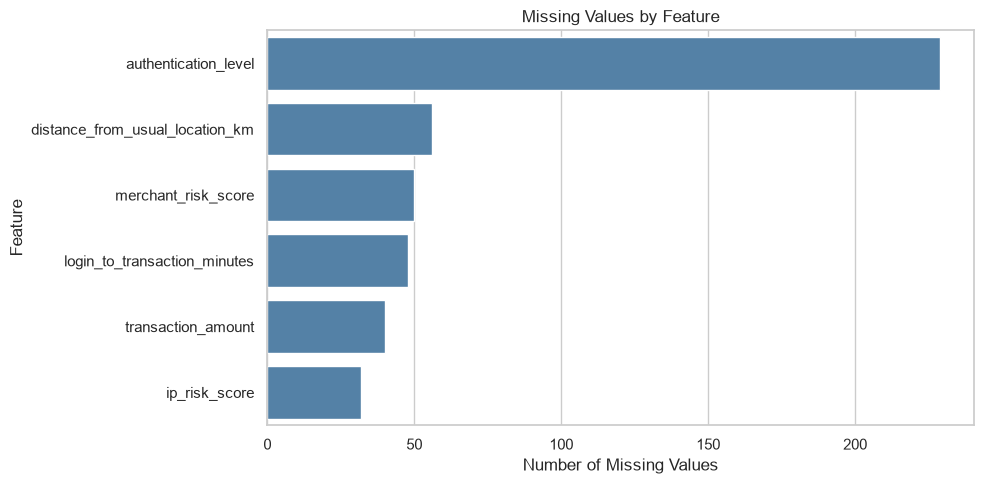

In [8]:
missing_counts = audit_df.isna().sum()
missing_counts = missing_counts[missing_counts > 0]
missing_counts = missing_counts.sort_values(ascending=False)

plt.figure(figsize=(10, 5))

sns.barplot(
    x=missing_counts.values,
    y=missing_counts.index,
    color="steelblue"
)

plt.title("Missing Values by Feature")
plt.xlabel("Number of Missing Values")
plt.ylabel("Feature")
plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "data_quality_missing_values.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [9]:
duplicate_report = {
    "exact_duplicate_rows": int(
        df.duplicated().sum()
    ),
    "duplicate_transaction_ids": int(
        df[ID_COLUMN].duplicated().sum()
    ),
    "duplicate_predictor_rows": int(
        df[feature_columns].duplicated().sum()
    ),
    "missing_transaction_ids": int(
        df[ID_COLUMN].isna().sum()
    )
}

display(pd.Series(duplicate_report))

pd.Series(duplicate_report).to_csv(
    METRICS_DIR / "duplicate_report.csv",
    header=["count"]
)

assert duplicate_report["duplicate_transaction_ids"] == 0
assert duplicate_report["duplicate_predictor_rows"] == 0

exact_duplicate_rows         0
duplicate_transaction_ids    0
duplicate_predictor_rows     0
missing_transaction_ids      0
dtype: int64

In [10]:
missingness_report = analyze_missingness(
    audit_df,
    TARGET
)

missingness_report = missingness_report.sort_values(
    "fisher_p_value"
)

display(missingness_report)

missingness_report.to_csv(
    METRICS_DIR / "missingness_analysis.csv",
    index=False
)

,feature,missing_count,missing_percentage,fraud_rate_missing,fraud_rate_present,fisher_p_value
5,authentication_level,229,9.5417,0.2096,0.1119,0.0001
2,merchant_risk_score,50,2.0833,0.0200,0.1234,0.0254
1,distance_from_usual_location_km,56,2.3333,0.0714,0.1224,0.3045
0,transaction_amount,40,1.6667,0.0750,0.1220,0.4703
3,ip_risk_score,32,1.3333,0.0938,0.1216,0.7902
4,login_to_transaction_minutes,48,2.0000,0.1042,0.1216,1.0000


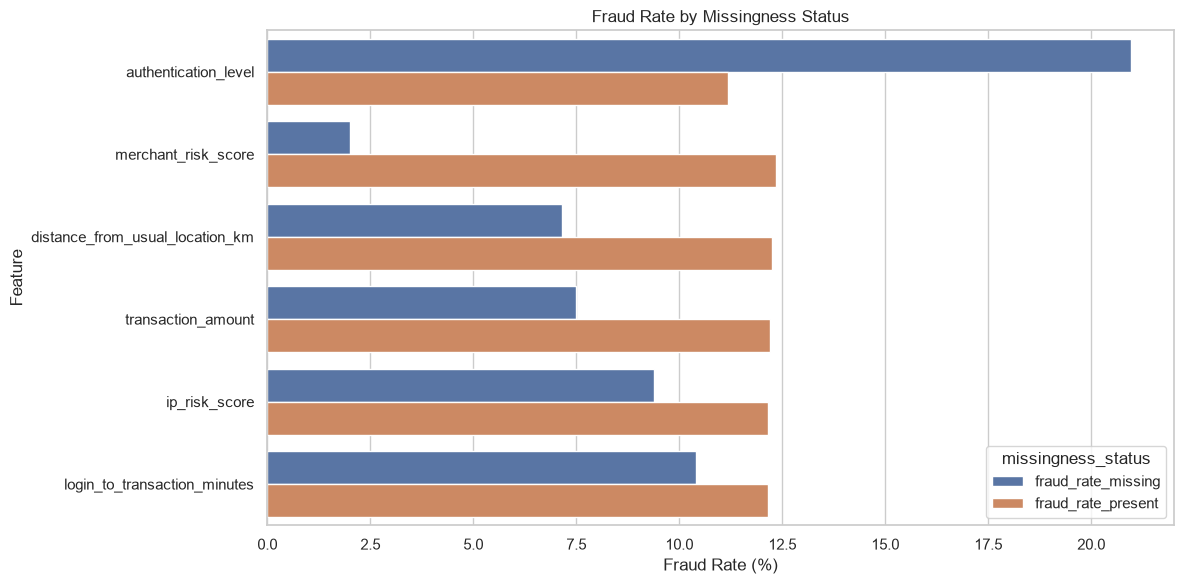

In [11]:
plot_data = missingness_report.melt(
    id_vars="feature",
    value_vars=[
        "fraud_rate_missing",
        "fraud_rate_present"
    ],
    var_name="missingness_status",
    value_name="fraud_rate"
)

plot_data["fraud_rate"] *= 100

plt.figure(figsize=(12, 6))

sns.barplot(
    data=plot_data,
    y="feature",
    x="fraud_rate",
    hue="missingness_status"
)

plt.title("Fraud Rate by Missingness Status")
plt.xlabel("Fraud Rate (%)")
plt.ylabel("Feature")
plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "missingness_fraud_rate.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [12]:
non_negative_columns = [
    "distance_from_usual_location_km",
    "transactions_last_1h",
    "transactions_last_24h",
    "account_age_days",
    "failed_logins_24h",
    "prior_chargebacks",
    "device_age_days",
    "email_age_days",
    "login_to_transaction_minutes"
]

integer_columns = [
    "hour",
    "day_of_week",
    "transactions_last_1h",
    "transactions_last_24h",
    "account_age_days",
    "failed_logins_24h",
    "prior_chargebacks",
    "device_age_days",
    "email_age_days"
]

invalid_checks = {
    "invalid_hour": (
        ~audit_df["hour"].between(0, 23)
    ).sum(),

    "invalid_day_of_week": (
        ~audit_df["day_of_week"].between(0, 6)
    ).sum(),

    "non_positive_transaction_amount": (
        audit_df["transaction_amount"] <= 0
    ).sum(),

    "invalid_merchant_risk": (
        audit_df["merchant_risk_score"].notna()
        & ~audit_df["merchant_risk_score"].between(0, 1)
    ).sum(),

    "invalid_ip_risk": (
        audit_df["ip_risk_score"].notna()
        & ~audit_df["ip_risk_score"].between(0, 1)
    ).sum(),

    "invalid_new_device": (
        ~audit_df["new_device"].isin([0, 1])
    ).sum(),

    "invalid_billing_address_mismatch": (
        ~audit_df["billing_address_mismatch"].isin([0, 1])
    ).sum(),

    "inconsistent_transaction_velocity": (
        audit_df["transactions_last_1h"]
        > audit_df["transactions_last_24h"]
    ).sum(),

    "invalid_target": (
        ~audit_df[TARGET].isin([0, 1])
    ).sum(),

    "infinite_values": (
        audit_df.select_dtypes(include="number")
        .isin([np.inf, -np.inf])
        .sum()
        .sum()
    )
}

for column in non_negative_columns:
    invalid_checks[f"negative_{column}"] = (
        audit_df[column] < 0
    ).sum()

for column in integer_columns:
    values = audit_df[column].dropna()

    invalid_checks[f"non_integer_{column}"] = (
        values % 1 != 0
    ).sum()

invalid_report = pd.DataFrame(
    invalid_checks.items(),
    columns=["validation_rule", "invalid_count"]
)

display(invalid_report)

invalid_report.to_csv(
    METRICS_DIR / "invalid_values_report.csv",
    index=False
)

,validation_rule,invalid_count
0,invalid_hour,0
1,invalid_day_of_week,0
2,non_positive_transaction_amount,0
3,invalid_merchant_risk,0
4,invalid_ip_risk,0
5,invalid_new_device,0
6,invalid_billing_address_mismatch,0
7,inconsistent_transaction_velocity,0
8,invalid_target,0
9,infinite_values,0


In [13]:
consistency_report = {
    "device_older_than_account": (
        audit_df["device_age_days"]
        > audit_df["account_age_days"]
    ).sum(),

    "new_device_with_age_above_30_days": (
        (audit_df["new_device"] == 1)
        & (audit_df["device_age_days"] > 30)
    ).sum()
}

display(pd.Series(consistency_report))

device_older_than_account            992
new_device_with_age_above_30_days    391
dtype: int64

In [14]:
numerical_summary = audit_df[
    numerical_features + binary_features
].describe().T

numerical_summary["skewness"] = audit_df[
    numerical_features + binary_features
].skew()

numerical_summary["median"] = audit_df[
    numerical_features + binary_features
].median()

display(numerical_summary)

numerical_summary.to_csv(
    METRICS_DIR / "numerical_summary.csv"
)

,count,mean,std,min,25%,50%,75%,max,skewness,median
hour,2400.0000,11.6708,6.9207,0.0000,6.0000,12.0000,18.0000,23.0000,-0.0414,12.0000
day_of_week,2400.0000,2.9442,1.9660,0.0000,1.0000,3.0000,5.0000,6.0000,0.0578,3.0000
transaction_amount,2360.0000,134.3472,249.2323,4.1200,49.6025,90.3200,156.3325,5538.1516,15.9679,90.3200
distance_from_usual_location_km,2344.0000,37.5151,50.5099,0.4900,16.8650,30.1250,48.3675,1173.2691,14.8463,30.1250
transactions_last_1h,2400.0000,2.1842,1.4556,0.0000,1.0000,2.0000,3.0000,10.0000,0.6990,2.0000
transactions_last_24h,2400.0000,7.8229,5.1222,0.0000,6.0000,8.0000,9.0000,113.0000,13.2938,8.0000
account_age_days,2400.0000,884.6638,519.7073,1.0000,436.5000,888.5000,1331.0000,1799.0000,0.0221,888.5000
failed_logins_24h,2400.0000,0.3308,0.5729,0.0000,0.0000,0.0000,1.0000,3.0000,1.6857,0.0000
prior_chargebacks,2400.0000,0.1246,0.3499,0.0000,0.0000,0.0000,0.0000,3.0000,2.7902,0.0000
device_age_days,2400.0000,750.0354,428.6903,2.0000,381.0000,741.0000,1116.2500,1499.0000,0.0158,741.0000


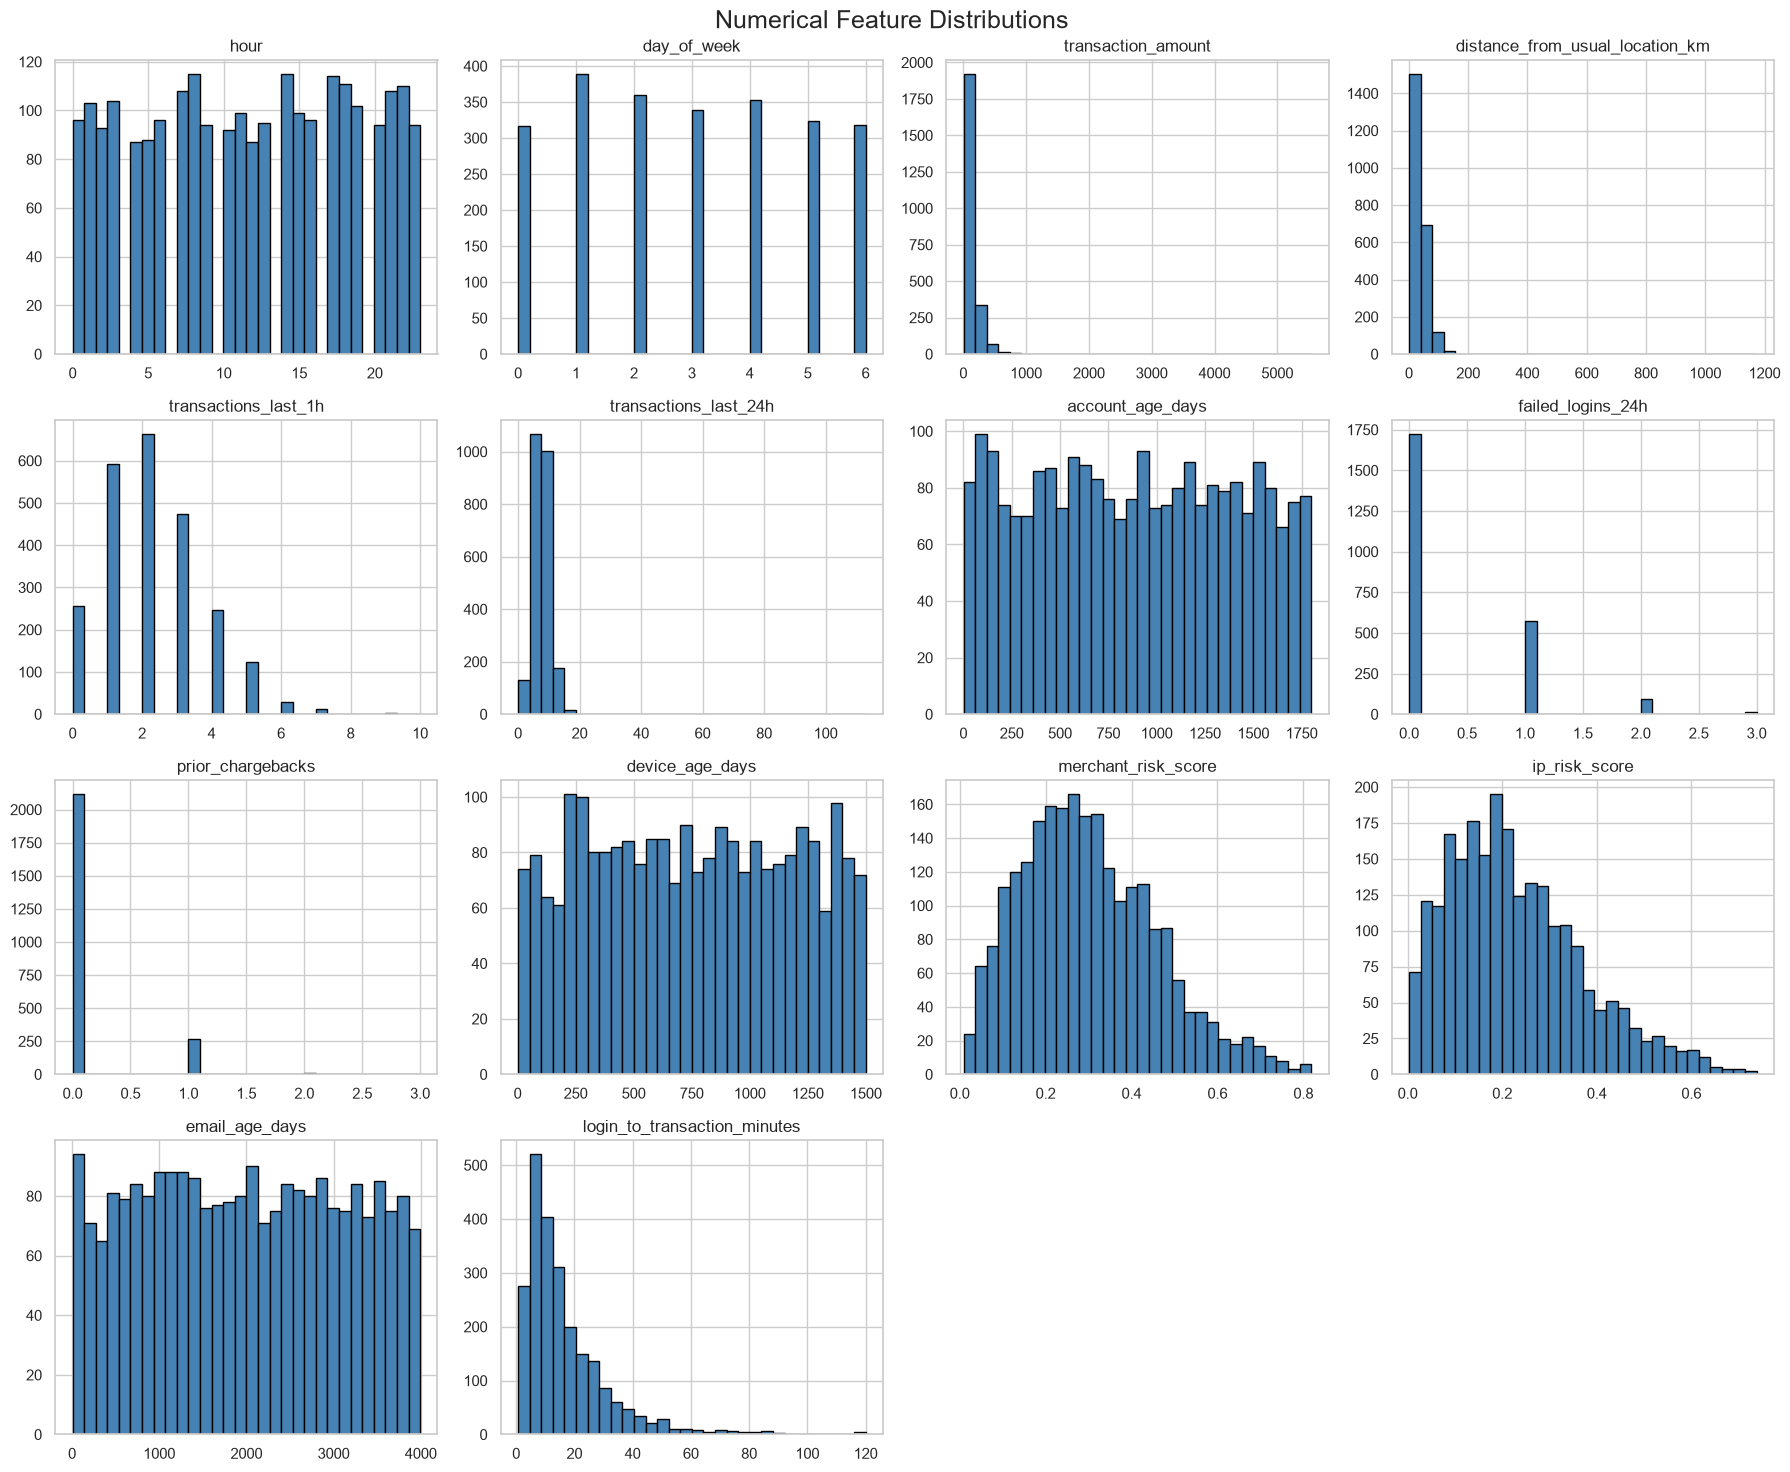

In [15]:
audit_df[numerical_features].hist(
    figsize=(18, 15),
    bins=30,
    color="steelblue",
    edgecolor="black"
)

plt.suptitle(
    "Numerical Feature Distributions",
    fontsize=18
)

plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "numerical_distributions.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [16]:
categorical_records = []

for column in categorical_features:

    print(f"\nFeature: {column}")

    counts = audit_df[column].value_counts(
        dropna=False
    )

    display(counts)

    for category, count in counts.items():

        categorical_records.append({
            "feature": column,
            "category": category,
            "count": count,
            "percentage": count / len(audit_df) * 100
        })

categorical_report = pd.DataFrame(
    categorical_records
)

categorical_report.to_csv(
    METRICS_DIR / "categorical_distributions.csv",
    index=False
)


Feature: card_presence


card_presence
Present        1396
Not present    1004
Name: count, dtype: int64


Feature: channel


channel
E-commerce    938
POS           770
Mobile App    471
ATM           221
Name: count, dtype: int64


Feature: country


country
Sri Lanka    1316
UAE           205
India         204
UK            188
Australia     170
Singapore     168
USA           149
Name: count, dtype: int64

... (4 outputs left out)


Feature: authentication_level


authentication_level
Strong      1094
Standard    1077
NaN          229
Name: count, dtype: int64


Feature: customer_tier


customer_tier
Basic       898
Silver      733
Gold        540
Platinum    229
Name: count, dtype: int64

In [17]:
outlier_features = [
    column for column in numerical_features
    if column not in ["hour", "day_of_week"]
]

outlier_report = detect_iqr_outliers(
    audit_df,
    outlier_features
)

display(
    outlier_report.sort_values(
        "outlier_count",
        ascending=False
    )
)

outlier_report.to_csv(
    METRICS_DIR / "outlier_report.csv",
    index=False
)

,feature,minimum,maximum,q1,q3,iqr,lower_bound,upper_bound,outlier_count,outlier_percentage,iqr_applicable
0,transaction_amount,4.1200,5538.1516,49.6025,156.3325,106.7300,-110.4925,316.4275,158.0000,6.6949,True
11,login_to_transaction_minutes,0.6600,120.0000,6.9375,21.9850,15.0475,-15.6337,44.5562,127.0000,5.3997,True
1,distance_from_usual_location_km,0.4900,1173.2691,16.8650,48.3675,31.5025,-30.3887,95.6213,72.0000,3.0717,True
3,transactions_last_24h,0.0000,113.0000,6.0000,9.0000,3.0000,1.5000,13.5000,71.0000,2.9583,True
9,ip_risk_score,0.0030,0.7380,0.1190,0.3130,0.1940,-0.1720,0.6040,36.0000,1.5203,True
2,transactions_last_1h,0.0000,10.0000,1.0000,3.0000,2.0000,-2.0000,6.0000,16.0000,0.6667,True
8,merchant_risk_score,0.0090,0.8180,0.1830,0.4050,0.2220,-0.1500,0.7380,16.0000,0.6809,True
5,failed_logins_24h,0.0000,3.0000,0.0000,1.0000,1.0000,-1.5000,2.5000,11.0000,0.4583,True
4,account_age_days,1.0000,1799.0000,436.5000,1331.0000,894.5000,-905.2500,2672.7500,0.0000,0.0000,True
7,device_age_days,2.0000,1499.0000,381.0000,1116.2500,735.2500,-721.8750,2219.1250,0.0000,0.0000,True


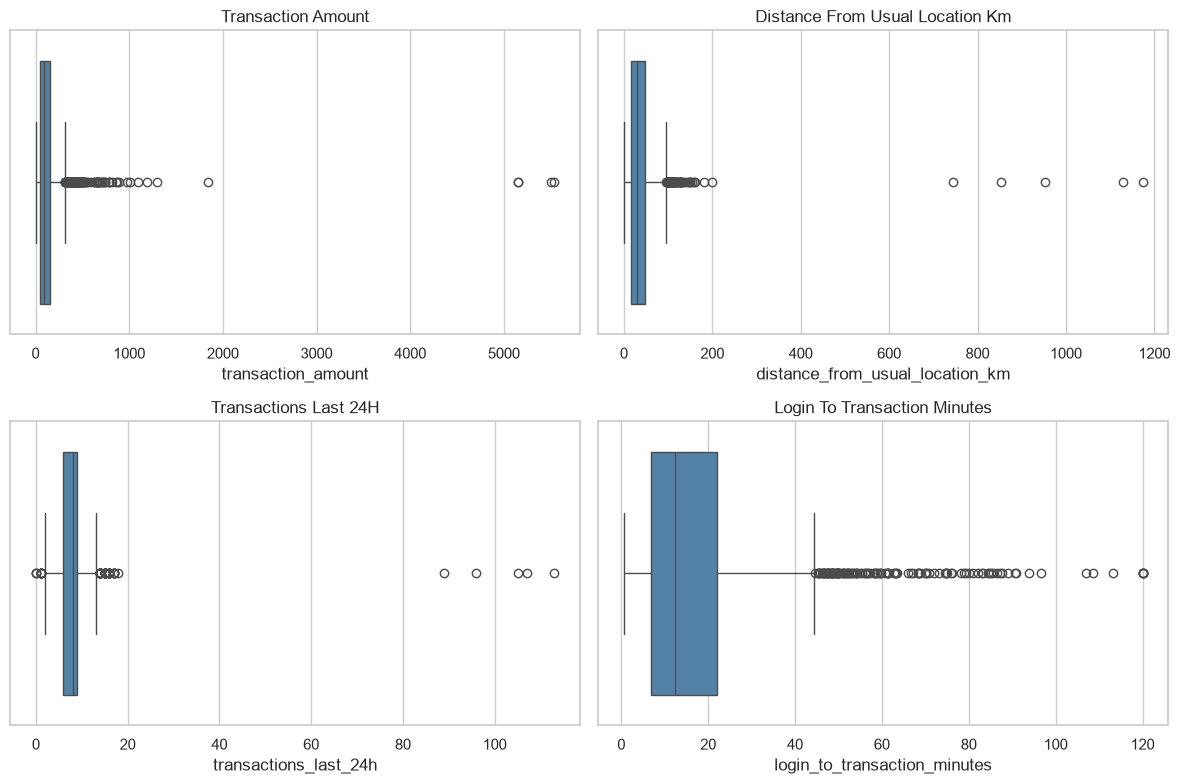

In [18]:
selected_features = [
    "transaction_amount",
    "distance_from_usual_location_km",
    "transactions_last_24h",
    "login_to_transaction_minutes"
]

fig, axes = plt.subplots(
    2, 2, figsize=(12, 8)
)

for column, ax in zip(
    selected_features, axes.flatten()
):

    sns.boxplot(
        x=audit_df[column],
        ax=ax,
        color="steelblue"
    )

    ax.set_title(column.replace("_", " ").title())

plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "extreme_observations.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### Data Leakage Assessment

The transaction ID is excluded from model predictors because
it is an identifier rather than a defensible behavioral feature.

The fraud label is used exclusively as the prediction target.

Historical chargebacks, transaction velocity, authentication,
location baselines, device information and external risk scores
must be calculated using information available before the
operational transaction decision.

The dataset does not provide feature lineage, complete timestamps,
customer identifiers or label maturity dates. Therefore, point-in-time
correctness, customer-level independence and temporal leakage
cannot be fully verified.

Risk-sensitive features are provisionally permitted under explicit
point-in-time availability assumptions. Their influence will be
investigated through feature exclusion sensitivity experiments.

Production deployment requires verification of these assumptions.

## 2. Data Splitting & Validation Strategy

Establish a reproducible validation framework using stratified
data partitioning and cross-validation.

The dataset is divided into four independent, non-overlapping
subsets:

- Training: 50%
- Calibration: 15%
- Threshold validation: 15%
- Final testing: 20%

The final test dataset is reserved exclusively for evaluation
after model selection, calibration and threshold optimization.

In [19]:
from src.validation import (
    split_development_data,
    create_split_summary,
    create_cv_strategy
)

train_df, calibration_df, threshold_df = (
    split_development_data(
        development_df,
        target=TARGET,
        random_state=RANDOM_STATE
    )
)

print("Training dataset:", train_df.shape)
print("Calibration dataset:", calibration_df.shape)
print("Threshold dataset:", threshold_df.shape)
print("Final test dataset:", test_df.shape)

Training dataset: (1500, 25)
Calibration dataset: (450, 25)
Threshold dataset: (450, 25)
Final test dataset: (600, 25)


In [20]:
datasets = {
    "Training": train_df,
    "Calibration": calibration_df,
    "Threshold Validation": threshold_df,
    "Final Test": test_df
}

split_summary = create_split_summary(
    datasets,
    target=TARGET
)

display(split_summary)

split_summary.to_csv(
    METRICS_DIR / "data_split_summary.csv",
    index=False
)

,dataset,total_transactions,legitimate_transactions,fraudulent_transactions,fraud_rate_percentage
0,Training,1500,1318,182,12.1333
1,Calibration,450,395,55,12.2222
2,Threshold Validation,450,396,54,12.0000
3,Final Test,600,527,73,12.1667


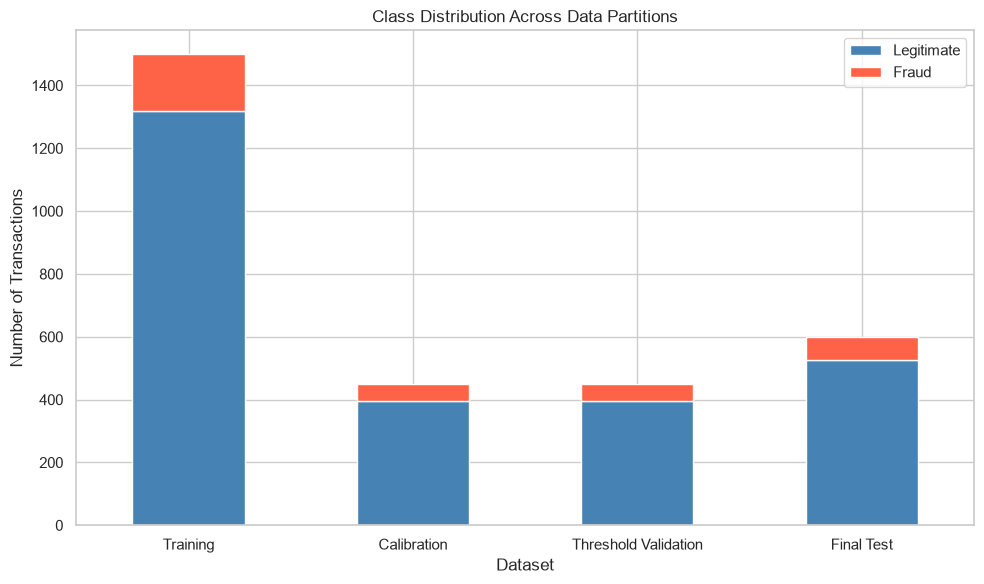

In [21]:
plot_df = split_summary.set_index("dataset")[
    [
        "legitimate_transactions",
        "fraudulent_transactions"
    ]
]

plot_df.plot(
    kind="bar",
    stacked=True,
    figsize=(10, 6),
    color=["steelblue", "tomato"]
)

plt.title("Class Distribution Across Data Partitions")
plt.xlabel("Dataset")
plt.ylabel("Number of Transactions")
plt.xticks(rotation=0)
plt.legend(["Legitimate", "Fraud"])
plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "data_split_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [22]:
from itertools import combinations

# Check for overlapping transaction IDs
for (name_a, data_a), (name_b, data_b) in combinations(
    datasets.items(), 2
):

    overlapping_ids = (
        set(data_a[ID_COLUMN])
        & set(data_b[ID_COLUMN])
    )

    assert len(overlapping_ids) == 0, (
        f"Overlap detected: {name_a} and {name_b}"
    )

    print(f"{name_a} vs {name_b}: No overlap")


# Verify all original transactions are preserved
all_ids = set().union(
    *(set(dataset[ID_COLUMN])
      for dataset in datasets.values())
)

assert all_ids == set(df[ID_COLUMN])

assert sum(
    len(dataset) for dataset in datasets.values()
) == len(df)

# Verify both target classes exist in every subset
for name, dataset in datasets.items():

    assert set(dataset[TARGET].unique()) == {0, 1}

print("\nAll data integrity checks passed!")

Training vs Calibration: No overlap
Training vs Threshold Validation: No overlap
Training vs Final Test: No overlap
Calibration vs Threshold Validation: No overlap
Calibration vs Final Test: No overlap
Threshold Validation vs Final Test: No overlap

All data integrity checks passed!


In [23]:
# Training dataset
X_train = train_df[feature_columns].copy()
y_train = train_df[TARGET].copy()

# Calibration dataset
X_calibration = calibration_df[feature_columns].copy()
y_calibration = calibration_df[TARGET].copy()

# Threshold validation dataset
X_threshold = threshold_df[feature_columns].copy()
y_threshold = threshold_df[TARGET].copy()

# Final test dataset
X_test = test_df[feature_columns].copy()
y_test = test_df[TARGET].copy()

print("X_train:", X_train.shape)
print("y_train:", y_train.shape)

print("X_calibration:", X_calibration.shape)
print("y_calibration:", y_calibration.shape)

print("X_threshold:", X_threshold.shape)
print("y_threshold:", y_threshold.shape)

print("X_test:", X_test.shape)
print("y_test:", y_test.shape)

X_train: (1500, 23)
y_train: (1500,)
X_calibration: (450, 23)
y_calibration: (450,)
X_threshold: (450, 23)
y_threshold: (450,)
X_test: (600, 23)
y_test: (600,)


In [24]:
cv = create_cv_strategy(
    random_state=RANDOM_STATE
)

print("Cross-validation strategy:", cv)
print("Number of folds:", cv.get_n_splits())

Cross-validation strategy: StratifiedKFold(n_splits=5, random_state=42, shuffle=True)
Number of folds: 5


In [25]:
fold_records = []

for fold, (train_index, val_index) in enumerate(
    cv.split(X_train, y_train),
    start=1
):

    fold_y_train = y_train.iloc[train_index]
    fold_y_val = y_train.iloc[val_index]

    fold_records.append({
        "fold": fold,
        "training_samples": len(fold_y_train),
        "validation_samples": len(fold_y_val),
        "training_fraud_count": int(
            fold_y_train.sum()
        ),
        "validation_fraud_count": int(
            fold_y_val.sum()
        ),
        "training_fraud_rate": (
            fold_y_train.mean() * 100
        ),
        "validation_fraud_rate": (
            fold_y_val.mean() * 100
        )
    })

cv_summary = pd.DataFrame(fold_records)

display(cv_summary)

cv_summary.to_csv(
    METRICS_DIR / "cross_validation_summary.csv",
    index=False
)

,fold,training_samples,validation_samples,training_fraud_count,validation_fraud_count,training_fraud_rate,validation_fraud_rate
0,1,1200,300,146,36,12.1667,12.0000
1,2,1200,300,146,36,12.1667,12.0000
2,3,1200,300,146,36,12.1667,12.0000
3,4,1200,300,145,37,12.0833,12.3333
4,5,1200,300,145,37,12.0833,12.3333


In [26]:
print("Available time-related features:")

time_features = [
    "hour",
    "day_of_week",
    "login_to_transaction_minutes"
]

display(df[time_features].head())

print("\nFirst transaction ID:")
print(df[ID_COLUMN].iloc[0])

print("\nLast transaction ID:")
print(df[ID_COLUMN].iloc[-1])

print(
    "\nTransaction IDs are sorted:",
    df[ID_COLUMN].is_monotonic_increasing
)

Available time-related features:


,hour,day_of_week,login_to_transaction_minutes
0,20,0,3.1200
1,4,1,22.5600
2,0,4,18.6800
3,15,4,13.4200
4,8,3,19.9000



First transaction ID:
TXN5000001

Last transaction ID:
TXN5003000

Transaction IDs are sorted: True


### Temporal Validation and Leakage Limitations

The dataset does not contain complete transaction timestamps,
customer identifiers or historical feature calculation metadata.

Although transaction identifiers are sequential, their
chronological meaning cannot be verified.

Therefore, chronological splitting and customer-level grouped
validation cannot be reliably implemented with the available data.

Stratified random splitting and five-fold cross-validation are
used as reproducible alternatives.

Production validation should include chronological holdout
datasets, point-in-time feature verification and monitoring
for changes in fraud patterns over time.

In [27]:
split_manifest = pd.concat(
    [
        dataset[[ID_COLUMN]].assign(dataset=name)
        for name, dataset in datasets.items()
    ],
    ignore_index=True
)

split_manifest = split_manifest.sort_values(
    ID_COLUMN
).reset_index(drop=True)

assert len(split_manifest) == len(df)
assert split_manifest[ID_COLUMN].is_unique

split_manifest.to_csv(
    METRICS_DIR / "data_split_manifest.csv",
    index=False
)

print("Split manifest saved successfully.")
print("Total assignments:", len(split_manifest))

Split manifest saved successfully.
Total assignments: 3000


In [28]:
eda_df = train_df.copy()

print("EDA dataset shape:", eda_df.shape)
print("Fraud rate:", eda_df[TARGET].mean() * 100)

EDA dataset shape: (1500, 25)
Fraud rate: 12.133333333333333


## 3. Advanced Exploratory Data Analysis

Investigate transaction fraud patterns using categorical,
temporal, numerical and interaction-based analysis.

All exploratory investigations are conducted exclusively
on the training dataset to reduce data leakage risk.

Fraud rates, sample sizes and confidence intervals are used
to identify potential risk factors and feature engineering
opportunities.

In [29]:
eda_df = train_df.copy()

assert len(eda_df) == len(X_train)

assert set(eda_df[ID_COLUMN]).isdisjoint(
    test_df[ID_COLUMN]
)

BASELINE_FRAUD_RATE = eda_df[TARGET].mean()

print("EDA dataset shape:", eda_df.shape)
print("Fraud transactions:", eda_df[TARGET].sum())
print(f"Baseline fraud rate: {BASELINE_FRAUD_RATE:.2%}")

EDA dataset shape: (1500, 25)
Fraud transactions: 182
Baseline fraud rate: 12.13%


In [30]:
### 3.1 Target Distribution and Class Imbalance

,transactions,percentage
fraud,,
0,1318,87.8667
1,182,12.1333


Imbalance ratio: 7.24


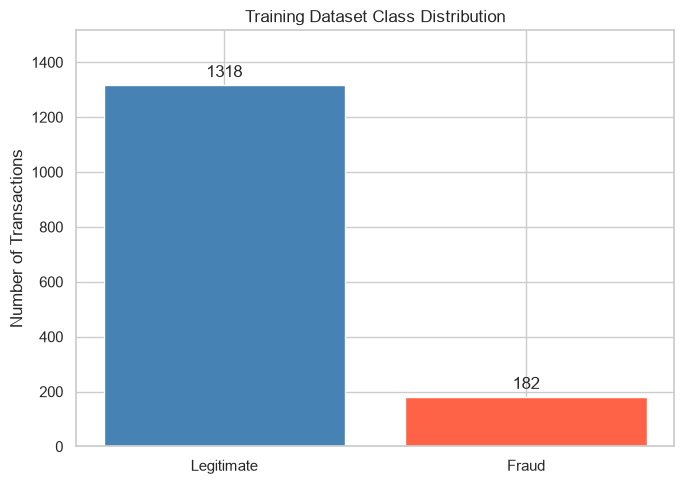

In [31]:
from src.eda import (
    create_bins,
    fraud_rate_table,
    plot_fraud_rates,
    plot_interaction
)

class_counts = eda_df[TARGET].value_counts().sort_index()

class_summary = pd.DataFrame({
    "transactions": class_counts,
    "percentage": class_counts / len(eda_df) * 100
})

display(class_summary)

class_summary.to_csv(
    METRICS_DIR / "eda_class_distribution.csv"
)

print(
    "Imbalance ratio:",
    round(class_counts[0] / class_counts[1], 2)
)

fig, ax = plt.subplots(figsize=(7, 5))

bars = ax.bar(
    ["Legitimate", "Fraud"],
    class_counts.values,
    color=["steelblue", "tomato"]
)

ax.bar_label(bars, padding=3)

ax.set_title("Training Dataset Class Distribution")
ax.set_ylabel("Number of Transactions")
ax.set_ylim(0, class_counts.max() * 1.15)

fig.tight_layout()

fig.savefig(
    FIGURES_DIR / "eda_01_class_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

### 3.2 Categorical Fraud Risk Analysis

Compare observed fraud rates across channels, merchant
categories, authentication levels, customer tiers and
device types.

Confidence intervals and transaction volumes are included
to prevent misleading interpretations of small groups.


Fraud Analysis: Transaction Channel


,transactions,fraud_count,fraud_rate,ci_lower,ci_upper,risk_lift,low_support
group,,,,,,,
E-commerce,584,87,0.1490,0.1224,0.1801,1.2278,False
Mobile App,283,35,0.1237,0.0903,0.1671,1.0193,False
POS,491,47,0.0957,0.0727,0.1250,0.7889,False
ATM,142,13,0.0915,0.0543,0.1503,0.7545,False


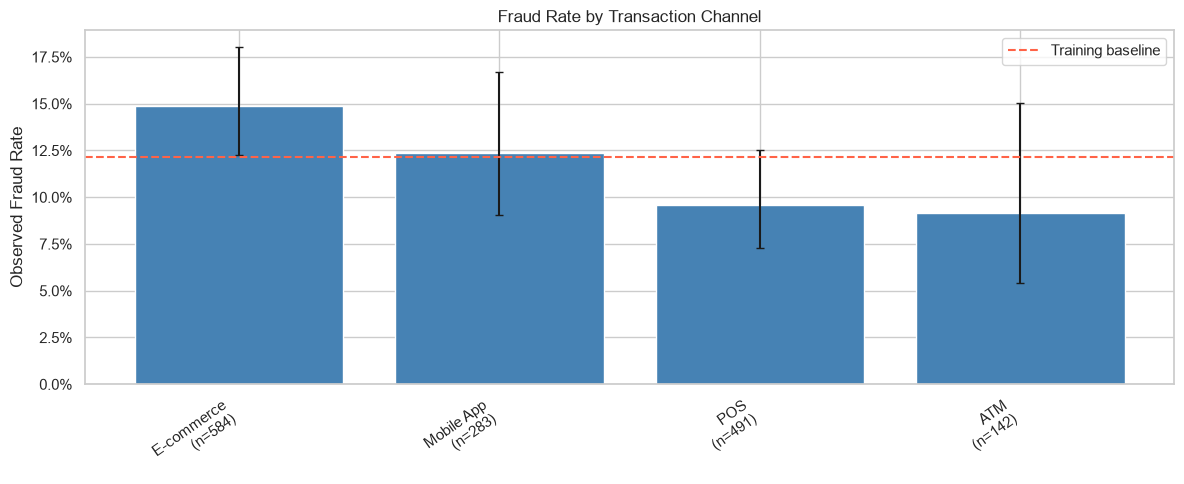


Fraud Analysis: Merchant Category


,transactions,fraud_count,fraud_rate,ci_lower,ci_upper,risk_lift,low_support
group,,,,,,,
Jewelry,59,13,0.2203,0.1335,0.3413,1.8160,False
Healthcare,101,14,0.1386,0.0844,0.2193,1.1424,False
Fashion,189,26,0.1376,0.0956,0.1939,1.1338,False
Gaming,114,15,0.1316,0.0814,0.2058,1.0844,False
Electronics,169,22,0.1302,0.0876,0.1892,1.0729,False
Grocery,252,30,0.1190,0.0847,0.1649,0.9812,False
Travel,108,12,0.1111,0.0647,0.1842,0.9158,False
Restaurants,206,22,0.1068,0.0716,0.1564,0.8802,False
Fuel,125,12,0.0960,0.0558,0.1603,0.7912,False


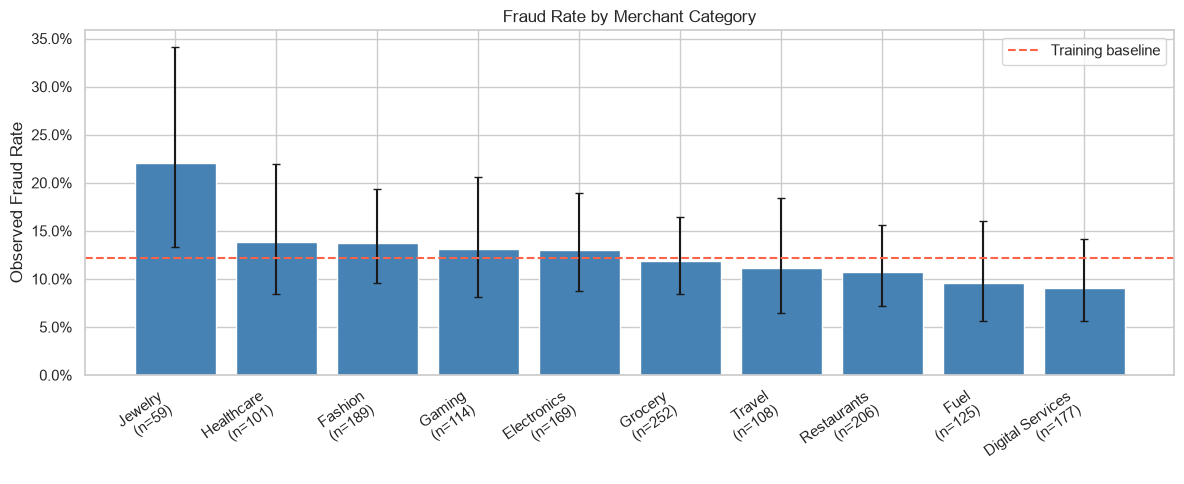


Fraud Analysis: Authentication Level


,transactions,fraud_count,fraud_rate,ci_lower,ci_upper,risk_lift,low_support
group,,,,,,,
Missing,146,30,0.2055,0.1479,0.2782,1.6935,False
Strong,673,80,0.1189,0.0966,0.1455,0.9797,False
Standard,681,72,0.1057,0.0848,0.1311,0.8714,False


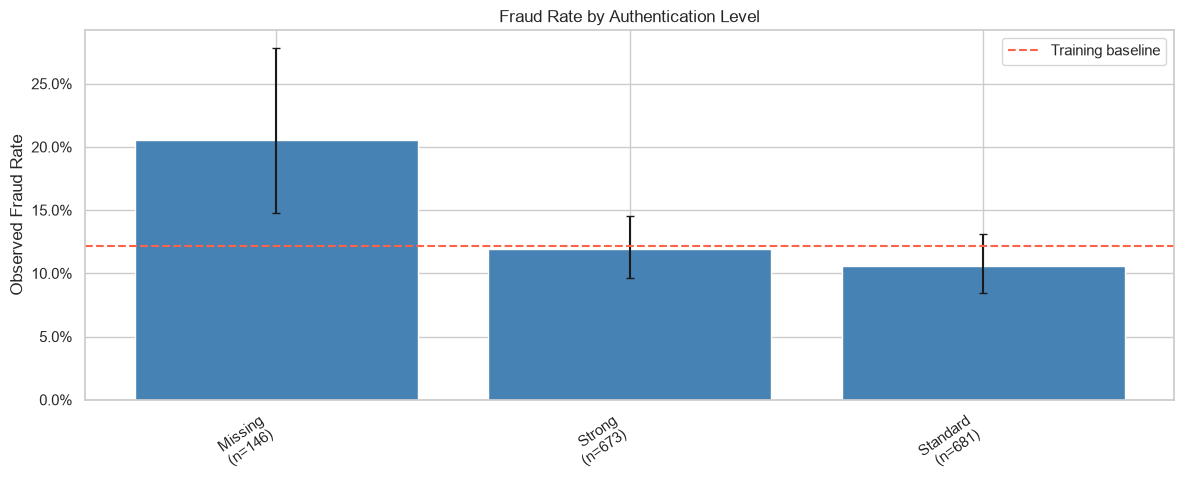


Fraud Analysis: Customer Tier


,transactions,fraud_count,fraud_rate,ci_lower,ci_upper,risk_lift,low_support
group,,,,,,,
Basic,568,85,0.1496,0.1227,0.1813,1.2334,False
Gold,340,37,0.1088,0.0800,0.1464,0.8969,False
Platinum,149,16,0.1074,0.0672,0.1673,0.8850,False
Silver,443,44,0.0993,0.0748,0.1307,0.8186,False


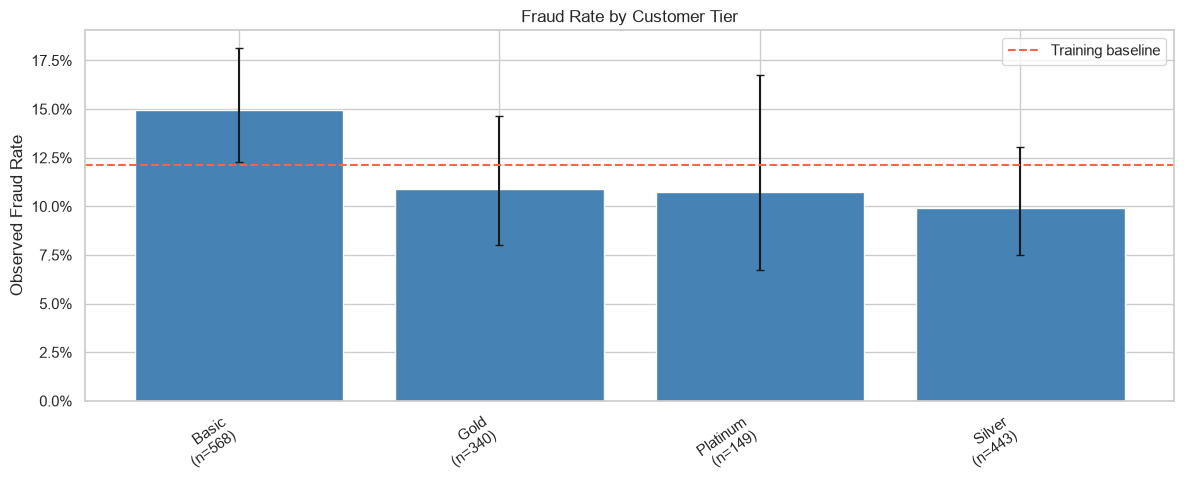


Fraud Analysis: Device Type


,transactions,fraud_count,fraud_rate,ci_lower,ci_upper,risk_lift,low_support
group,,,,,,,
Windows,187,25,0.1337,0.0922,0.1899,1.1018,False
macOS,184,24,0.1304,0.0892,0.1867,1.0750,False
Other,125,16,0.1280,0.0803,0.1978,1.0549,False
Android,571,72,0.1261,0.1013,0.1558,1.0392,False
iOS,433,45,0.1039,0.0786,0.1362,0.8565,False


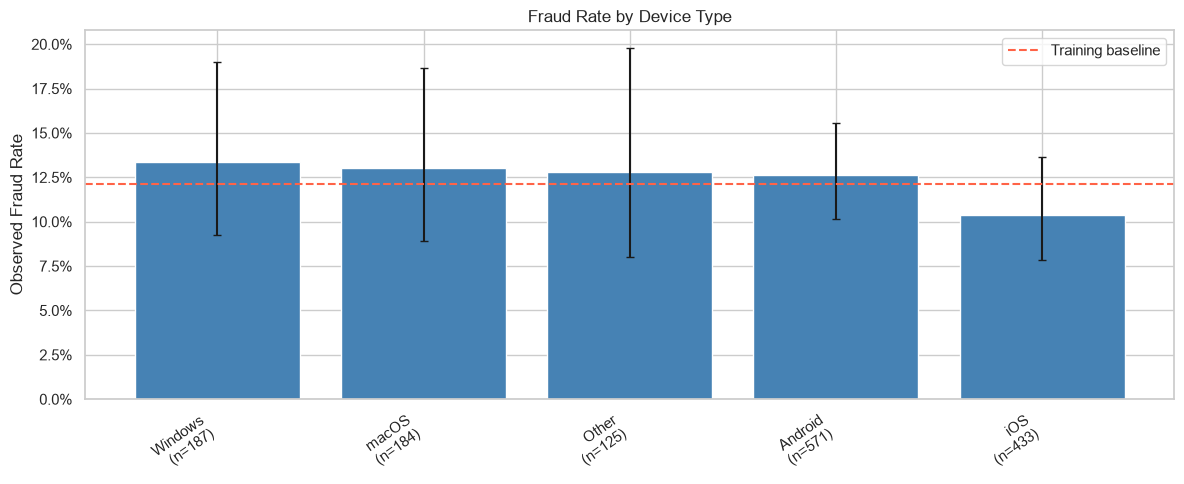

In [32]:
categorical_eda_features = {
    "channel": "Transaction Channel",
    "merchant_category": "Merchant Category",
    "authentication_level": "Authentication Level",
    "customer_tier": "Customer Tier",
    "device_type": "Device Type"
}

eda_results = {}

for number, (feature, title) in enumerate(
    categorical_eda_features.items(),
    start=2
):

    summary = fraud_rate_table(
        eda_df,
        feature,
        target=TARGET
    )

    eda_results[feature] = summary

    print(f"\nFraud Analysis: {title}")

    display(summary)

    summary.to_csv(
        METRICS_DIR / f"eda_{feature}.csv"
    )

    plot_fraud_rates(
        summary,
        f"Fraud Rate by {title}",
        BASELINE_FRAUD_RATE,
        FIGURES_DIR / f"eda_{number:02d}_{feature}.png"
    )

### 3.3 Time-Based Fraud Analysis

Investigate fraud-rate variation by transaction hour
and recorded day of the week.

The dataset lacks full timestamps; therefore, this analysis
examines recurring time patterns rather than chronological
fraud trends.

,transactions,fraud_count,fraud_rate,ci_lower,ci_upper,risk_lift,low_support
group,,,,,,,
0,64,12,0.1875,0.1106,0.2997,1.5453,False
1,58,5,0.0862,0.0374,0.1864,0.7105,False
2,58,6,0.1034,0.0483,0.2079,0.8526,False
3,58,9,0.1552,0.0838,0.2693,1.2789,False
4,58,10,0.1724,0.0964,0.2891,1.4210,False
5,51,7,0.1373,0.0681,0.2572,1.1312,False
6,60,11,0.1833,0.1056,0.2992,1.5110,False
7,70,4,0.0571,0.0224,0.1379,0.4710,False
8,73,8,0.1096,0.0566,0.2016,0.9032,False


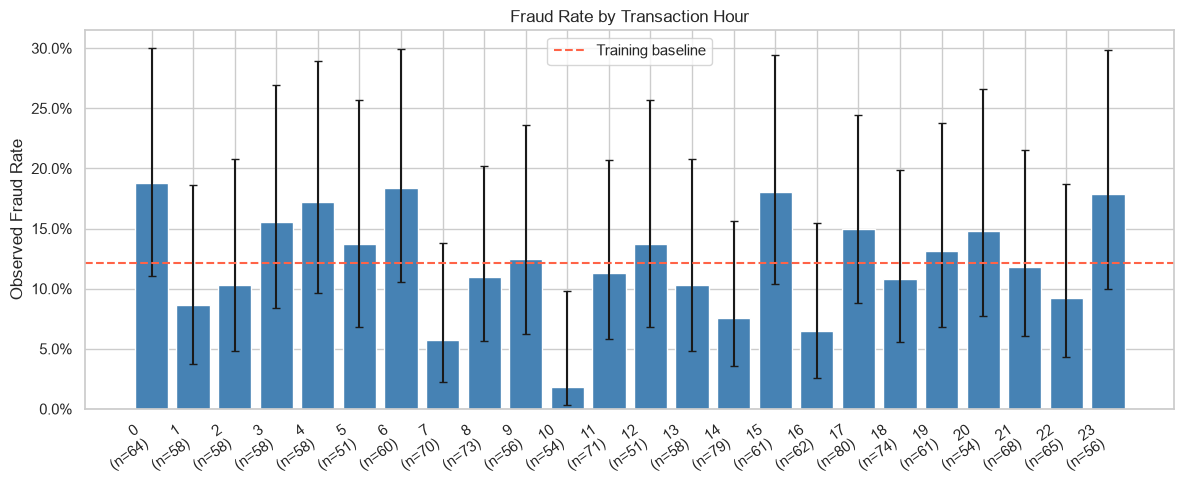

,transactions,fraud_count,fraud_rate,ci_lower,ci_upper,risk_lift,low_support
group,,,,,,,
0,192,22,0.1146,0.0769,0.1674,0.9444,False
1,235,32,0.1362,0.0981,0.1859,1.1223,False
2,223,29,0.1300,0.0921,0.1805,1.0718,False
3,219,27,0.1233,0.0861,0.1734,1.0161,False
4,221,27,0.1222,0.0853,0.1719,1.0069,False
5,208,22,0.1058,0.0709,0.1549,0.8717,False
6,202,23,0.1139,0.0771,0.1651,0.9384,False


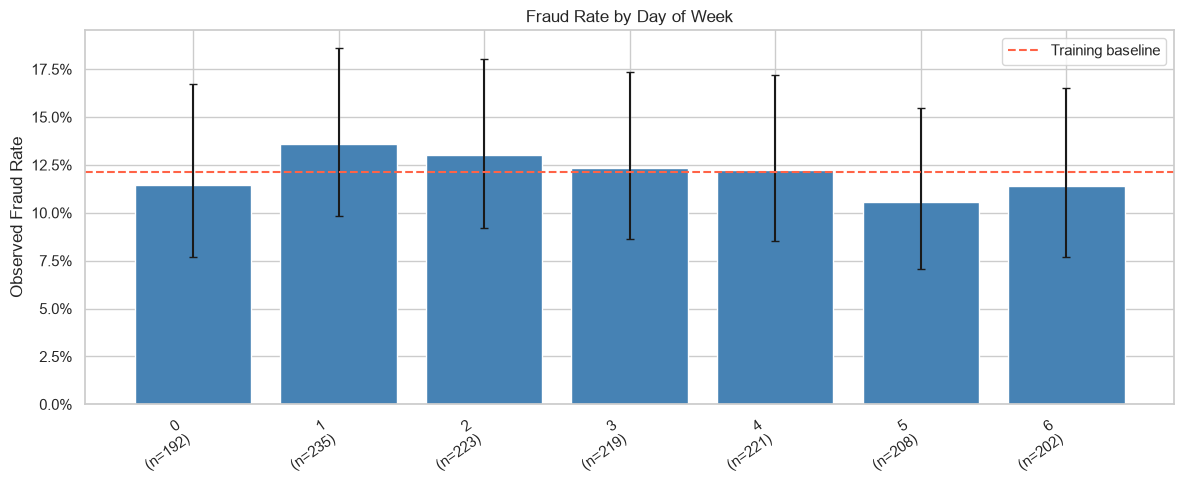

In [33]:
time_eda_features = {
    "hour": (
        "Transaction Hour",
        list(range(24))
    ),
    "day_of_week": (
        "Day of Week",
        list(range(7))
    )
}

for number, (feature, config) in enumerate(
    time_eda_features.items(),
    start=7
):

    title, order = config

    summary = fraud_rate_table(
        eda_df,
        feature,
        target=TARGET,
        order=order
    )

    eda_results[feature] = summary

    display(summary)

    summary.to_csv(
        METRICS_DIR / f"eda_{feature}.csv"
    )

    plot_fraud_rates(
        summary,
        f"Fraud Rate by {title}",
        BASELINE_FRAUD_RATE,
        FIGURES_DIR / f"eda_{number:02d}_{feature}.png"
    )

### 3.4 Numerical and Nonlinear Risk Analysis

Analyze nonlinear relationships between fraud and transaction
amount, transaction velocity, geographical distance, account
age, merchant risk scores and IP risk scores.

Numerical intervals are used for exploratory analysis.
Missing observations are represented as separate groups.
Extreme observations are retained.


Fraud Analysis: Transaction Amount


,transactions,fraud_count,fraud_rate,ci_lower,ci_upper,risk_lift,low_support
group,,,,,,,
<=50,373,39,0.1046,0.0774,0.1397,0.8617,False
50-150,697,79,0.1133,0.0919,0.1390,0.9341,False
150-500,378,54,0.1429,0.1112,0.1817,1.1774,False
>500,25,8,0.3200,0.1720,0.5159,2.6374,True
Missing,27,2,0.0741,0.0206,0.2337,0.6105,True


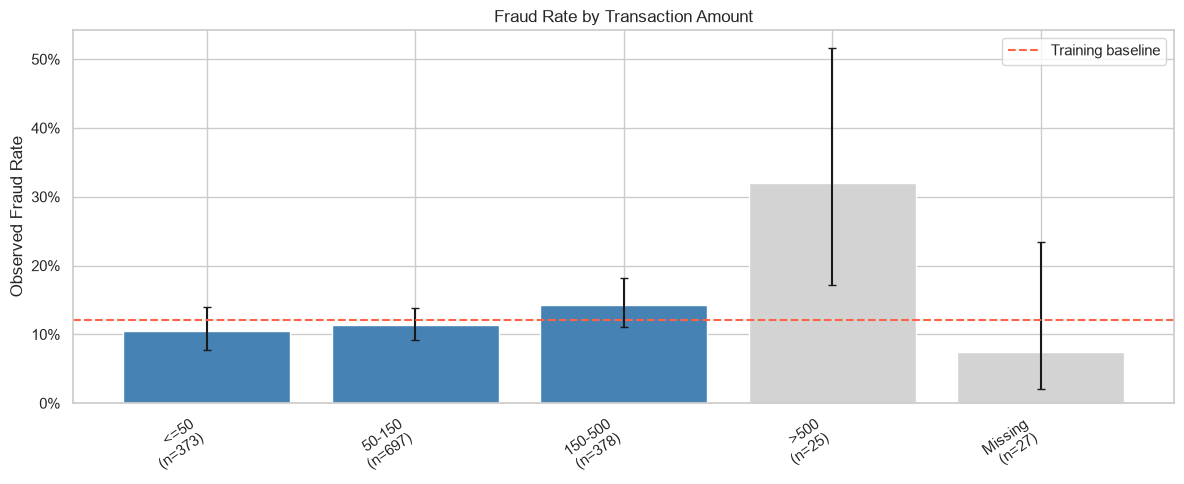


Fraud Analysis: Distance from Usual Location


,transactions,fraud_count,fraud_rate,ci_lower,ci_upper,risk_lift,low_support
group,,,,,,,
<=20,464,52,0.1121,0.0865,0.1440,0.9236,False
20-50,658,90,0.1368,0.1126,0.1651,1.1273,False
50-100,303,32,0.1056,0.0758,0.1453,0.8704,False
>100,36,5,0.1389,0.0608,0.2866,1.1447,False
Missing,39,3,0.0769,0.0265,0.2032,0.6340,False


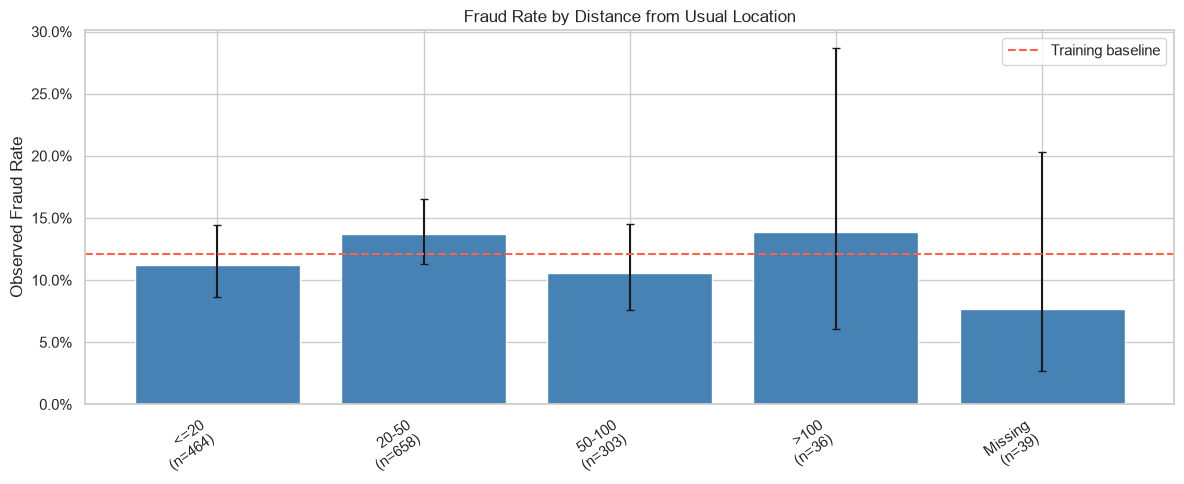


Fraud Analysis: Transactions in Last Hour


,transactions,fraud_count,fraud_rate,ci_lower,ci_upper,risk_lift,low_support
group,,,,,,,
0-1,543.0000,49.0000,0.0902,0.0689,0.1173,0.7437,False
2-3,700.0000,91.0000,0.1300,0.1071,0.1569,1.0714,False
4-5,228.0000,33.0000,0.1447,0.1050,0.1963,1.1929,False
6+,29.0000,9.0000,0.3103,0.1728,0.4923,2.5578,True


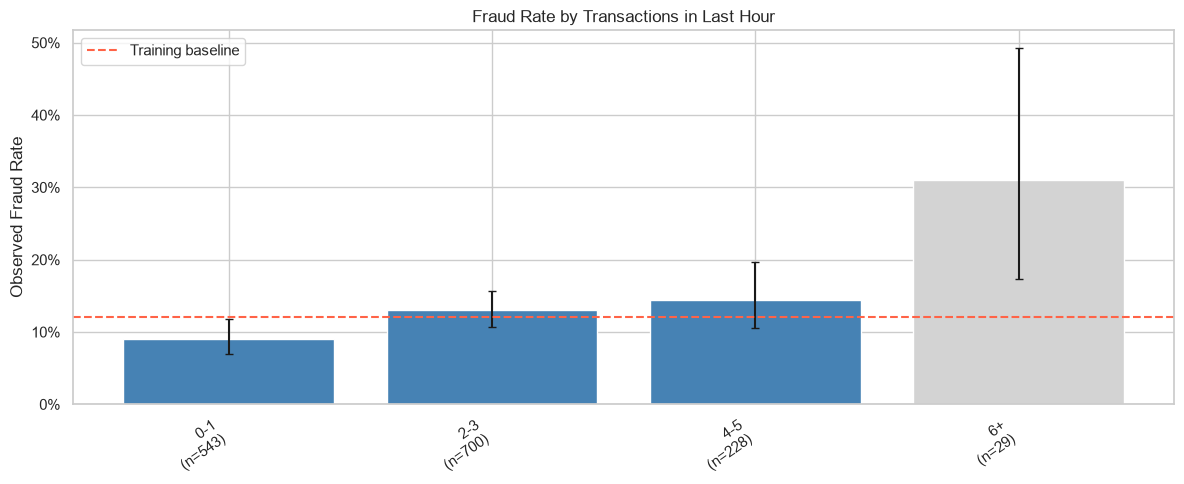


Fraud Analysis: Transactions in Last 24 Hours


,transactions,fraud_count,fraud_rate,ci_lower,ci_upper,risk_lift,low_support
group,,,,,,,
0-5,351.0000,33.0000,0.0940,0.0677,0.1291,0.7749,False
6-10,917.0000,112.0000,0.1221,0.1025,0.1449,1.0066,False
11-20,230.0000,37.0000,0.1609,0.1190,0.2139,1.3258,False
21+,2.0000,0.0000,0.0000,0.0000,0.6576,0.0000,True


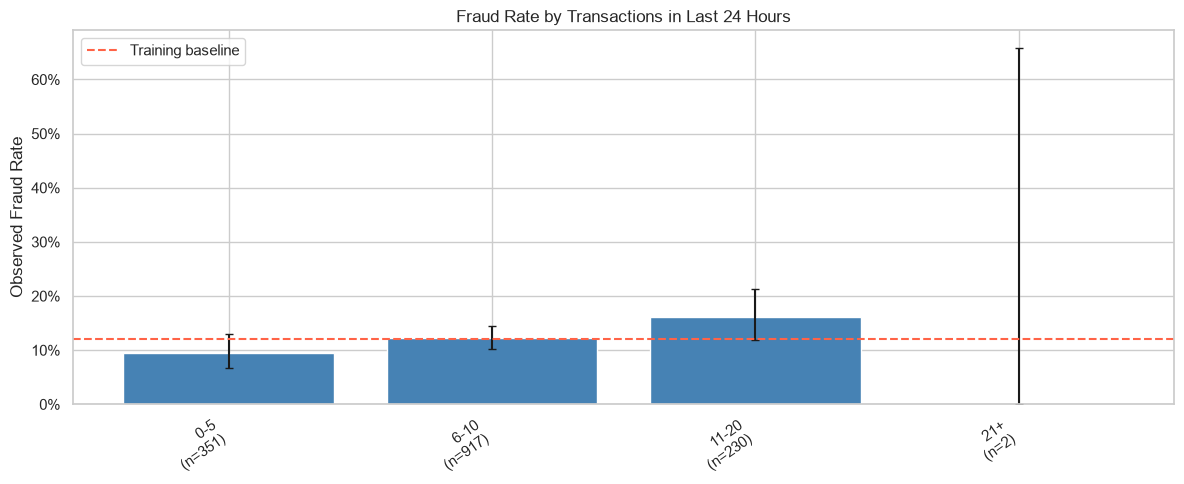


Fraud Analysis: Account Age


,transactions,fraud_count,fraud_rate,ci_lower,ci_upper,risk_lift,low_support
group,,,,,,,
<=90,79.0000,14.0000,0.1772,0.1086,0.2758,1.4606,False
91-365,214.0000,34.0000,0.1589,0.1160,0.2138,1.3094,False
366-730,320.0000,39.0000,0.1219,0.0904,0.1623,1.0045,False
731+,887.0000,95.0000,0.1071,0.0884,0.1292,0.8827,False


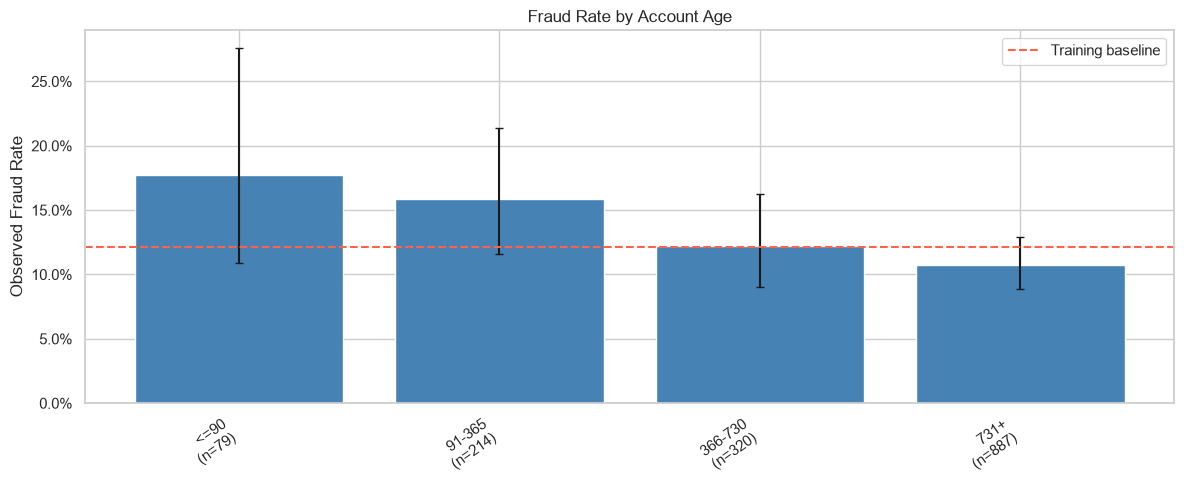


Fraud Analysis: Merchant Risk Score


,transactions,fraud_count,fraud_rate,ci_lower,ci_upper,risk_lift,low_support
group,,,,,,,
<=0.2,436,39,0.0894,0.0661,0.1199,0.7372,False
0.2-0.4,667,78,0.1169,0.0947,0.1436,0.9638,False
>0.4,364,64,0.1758,0.1402,0.2183,1.4491,False
Missing,33,1,0.0303,0.0054,0.1532,0.2498,False


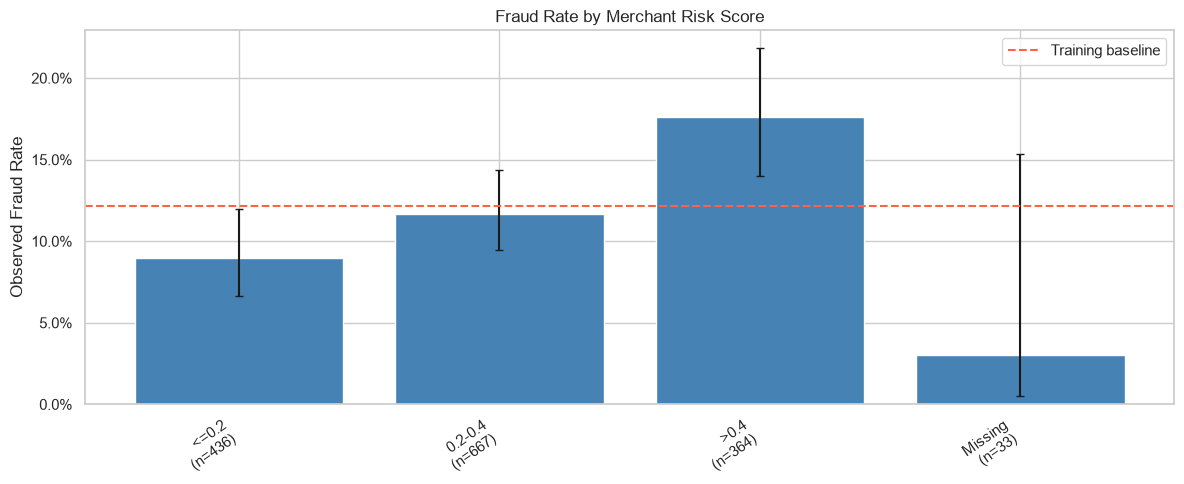


Fraud Analysis: IP Risk Score


,transactions,fraud_count,fraud_rate,ci_lower,ci_upper,risk_lift,low_support
group,,,,,,,
<=0.2,738,81,0.1098,0.0892,0.1344,0.9046,False
0.2-0.4,568,71,0.1250,0.1003,0.1547,1.0302,False
>0.4,173,28,0.1618,0.1144,0.2240,1.3339,False
Missing,21,2,0.0952,0.0265,0.2891,0.7849,True


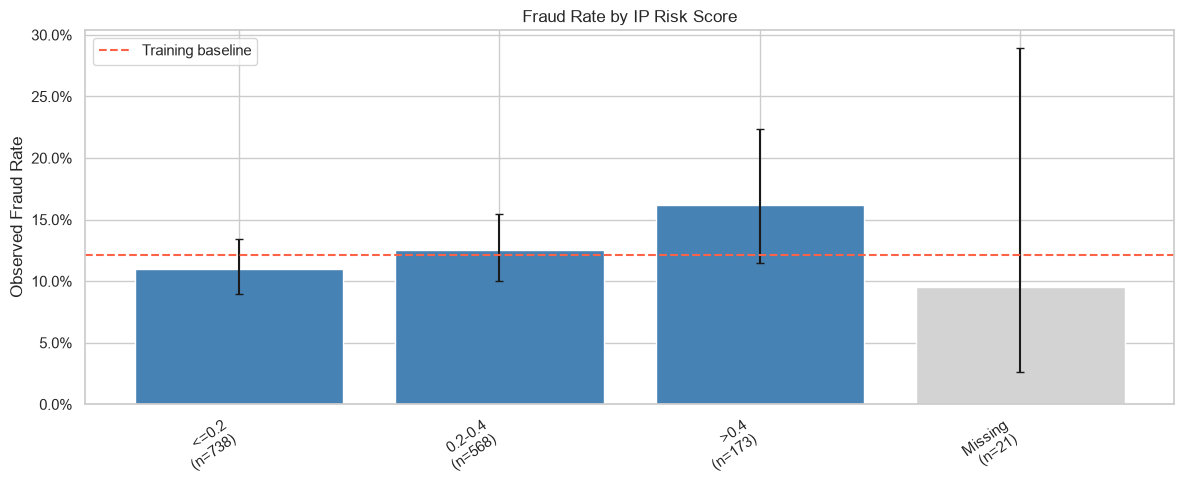

In [34]:
numerical_eda_config = [
    (
        "transaction_amount",
        "amount_band",
        "Transaction Amount",
        [-np.inf, 50, 150, 500, np.inf],
        ["<=50", "50-150", "150-500", ">500"]
    ),
    (
        "distance_from_usual_location_km",
        "distance_band",
        "Distance from Usual Location",
        [-np.inf, 20, 50, 100, np.inf],
        ["<=20", "20-50", "50-100", ">100"]
    ),
    (
        "transactions_last_1h",
        "velocity_1h_band",
        "Transactions in Last Hour",
        [-np.inf, 1, 3, 5, np.inf],
        ["0-1", "2-3", "4-5", "6+"]
    ),
    (
        "transactions_last_24h",
        "velocity_24h_band",
        "Transactions in Last 24 Hours",
        [-np.inf, 5, 10, 20, np.inf],
        ["0-5", "6-10", "11-20", "21+"]
    ),
    (
        "account_age_days",
        "account_age_band",
        "Account Age",
        [-np.inf, 90, 365, 730, np.inf],
        ["<=90", "91-365", "366-730", "731+"]
    ),
    (
        "merchant_risk_score",
        "merchant_risk_band",
        "Merchant Risk Score",
        [-np.inf, 0.2, 0.4, np.inf],
        ["<=0.2", "0.2-0.4", ">0.4"]
    ),
    (
        "ip_risk_score",
        "ip_risk_band",
        "IP Risk Score",
        [-np.inf, 0.2, 0.4, np.inf],
        ["<=0.2", "0.2-0.4", ">0.4"]
    )
]

# Temporary dataset for EDA bins
eda_binned_df = eda_df.copy()

for number, config in enumerate(
    numerical_eda_config,
    start=9
):

    feature, band, title, edges, labels = config

    eda_binned_df[band] = create_bins(
        eda_binned_df[feature],
        edges,
        labels
    )

    summary = fraud_rate_table(
        eda_binned_df,
        band,
        target=TARGET,
        order=labels + ["Missing"]
    )

    eda_results[band] = summary

    print(f"\nFraud Analysis: {title}")

    display(summary)

    summary.to_csv(
        METRICS_DIR / f"eda_{band}.csv"
    )

    plot_fraud_rates(
        summary,
        f"Fraud Rate by {title}",
        BASELINE_FRAUD_RATE,
        FIGURES_DIR / f"eda_{number:02d}_{band}.png"
    )

### 3.5 Feature Interaction Analysis

Investigate joint fraud-risk patterns involving:

1. New device and geographical distance.
2. Transaction amount and merchant risk.
3. Authentication level and transaction channel.

Heatmaps display observed fraud rates and sample sizes.
Groups with fewer than 30 transactions are flagged as
low-support observations.

Observed interaction patterns are treated as exploratory
evidence rather than confirmed causal relationships.

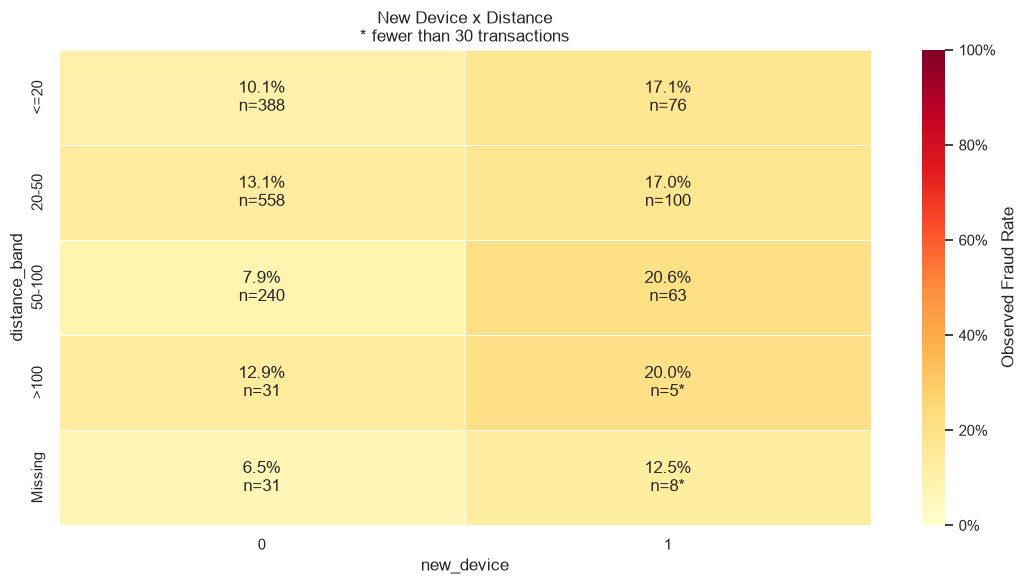


Fraud rates (%)


new_device,0,1
distance_band,,
<=20,10.0515,17.1053
20-50,13.0824,17.0000
50-100,7.9167,20.6349
>100,12.9032,20.0000
Missing,6.4516,12.5000



Transaction counts


new_device,0,1
distance_band,,
<=20,388,76
20-50,558,100
50-100,240,63
>100,31,5
Missing,31,8


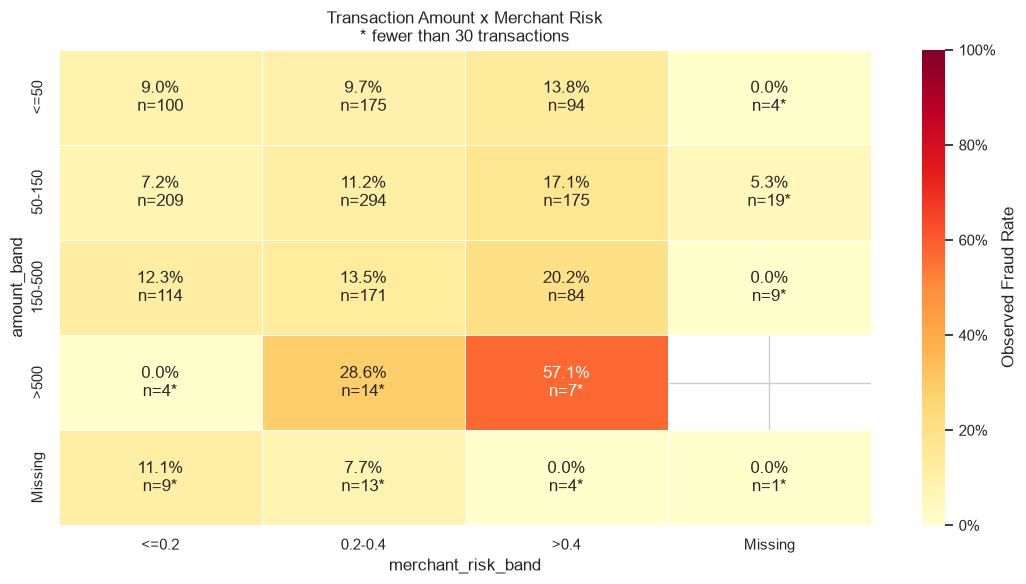


Fraud rates (%)


merchant_risk_band,<=0.2,0.2-0.4,>0.4,Missing
amount_band,,,,
<=50,9.0000,9.7143,13.8298,0.0000
50-150,7.1770,11.2245,17.1429,5.2632
150-500,12.2807,13.4503,20.2381,0.0000
>500,0.0000,28.5714,57.1429,NaN
Missing,11.1111,7.6923,0.0000,0.0000



Transaction counts


merchant_risk_band,<=0.2,0.2-0.4,>0.4,Missing
amount_band,,,,
<=50,100,175,94,4
50-150,209,294,175,19
150-500,114,171,84,9
>500,4,14,7,0
Missing,9,13,4,1


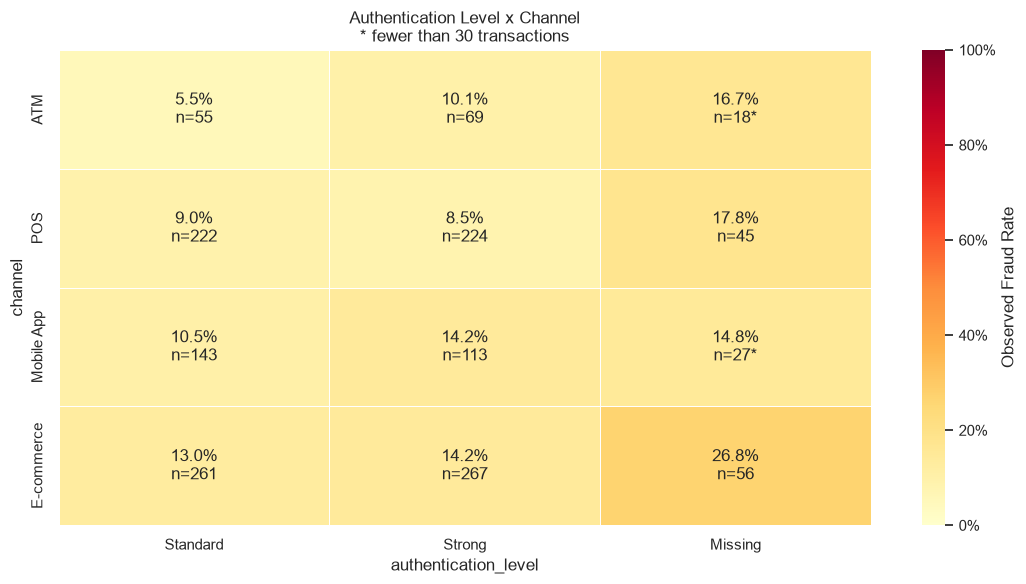


Fraud rates (%)


authentication_level,Standard,Strong,Missing
channel,,,
ATM,5.4545,10.1449,16.6667
POS,9.0090,8.4821,17.7778
Mobile App,10.4895,14.1593,14.8148
E-commerce,13.0268,14.2322,26.7857



Transaction counts


authentication_level,Standard,Strong,Missing
channel,,,
ATM,55,69,18
POS,222,224,45
Mobile App,143,113,27
E-commerce,261,267,56


In [35]:
interaction_configs = [
    {
        "name": "new_device_distance",
        "row": "distance_band",
        "col": "new_device",
        "title": "New Device x Distance",
        "row_order": [
            "<=20",
            "20-50",
            "50-100",
            ">100",
            "Missing"
        ],
        "col_order": [0, 1]
    },
    {
        "name": "amount_merchant_risk",
        "row": "amount_band",
        "col": "merchant_risk_band",
        "title": "Transaction Amount x Merchant Risk",
        "row_order": [
            "<=50",
            "50-150",
            "150-500",
            ">500",
            "Missing"
        ],
        "col_order": [
            "<=0.2",
            "0.2-0.4",
            ">0.4",
            "Missing"
        ]
    },
    {
        "name": "authentication_channel",
        "row": "channel",
        "col": "authentication_level",
        "title": "Authentication Level x Channel",
        "row_order": [
            "ATM",
            "POS",
            "Mobile App",
            "E-commerce"
        ],
        "col_order": [
            "Standard",
            "Strong",
            "Missing"
        ]
    }
]

interaction_results = {}

for number, config in enumerate(
    interaction_configs,
    start=16
):

    name = config["name"]

    rates, counts = plot_interaction(
        df=eda_binned_df,
        row=config["row"],
        col=config["col"],
        title=config["title"],
        path=FIGURES_DIR / (
            f"eda_{number:02d}_{name}.png"
        ),
        target=TARGET,
        row_order=config["row_order"],
        col_order=config["col_order"]
    )

    interaction_results[name] = {
        "fraud_rates": rates,
        "transaction_counts": counts
    }

    print("\nFraud rates (%)")
    display(rates * 100)

    print("\nTransaction counts")
    display(counts)

    rates.to_csv(
        METRICS_DIR / f"eda_{name}_rates.csv"
    )

    counts.to_csv(
        METRICS_DIR / f"eda_{name}_counts.csv"
    )

### 3.6 Key EDA Findings

The training dataset contains an overall fraud rate of 12.13%.

The exploratory analysis identifies transaction velocity,
transaction amount, account age, merchant risk, IP risk,
authentication missingness and device-related behavior
as potential predictors.

Feature interaction analysis reveals elevated observed risk
for new devices at unusual distances, high-value transactions
with elevated merchant risk, and e-commerce transactions
with missing authentication.

These relationships are observational and must be validated
through cross-validation and feature ablation experiments.

Small groups and extreme fraud rates are interpreted cautiously.
No observations are removed based solely on these results.

In [36]:
eda_figures = sorted(
    FIGURES_DIR.glob("eda_*.png")
)

print("Total EDA visualizations:", len(eda_figures))

for file in eda_figures:
    print(file.name)

assert len(eda_figures) == 18

assert len(interaction_results) == 3

print("\nEDA visualization requirements satisfied!")

Total EDA visualizations: 18
eda_01_class_distribution.png
eda_02_channel.png
eda_03_merchant_category.png
eda_04_authentication_level.png
eda_05_customer_tier.png
eda_06_device_type.png
eda_07_hour.png
eda_08_day_of_week.png
eda_09_amount_band.png
eda_10_distance_band.png
eda_11_velocity_1h_band.png
eda_12_velocity_24h_band.png
eda_13_account_age_band.png
eda_14_merchant_risk_band.png
eda_15_ip_risk_band.png
eda_16_new_device_distance.png
eda_17_amount_merchant_risk.png
eda_18_authentication_channel.png

EDA visualization requirements satisfied!


## 4. Feature Engineering

Develop defensible transaction-level features based on
exploratory analysis and financial fraud-risk knowledge.

The engineered features capture transaction velocity,
amount normalization, behavioral deviations, combined
risk factors, cyclical time patterns and interactions.

All learned feature transformations are fitted exclusively
on the appropriate training data or cross-validation fold.

In [37]:
from src.feature_engineering import (
    FraudFeatureEngineer,
    ENGINEERED_FEATURES
)

feature_engineer = FraudFeatureEngineer()

# Fit only on training predictors
X_train_engineered = feature_engineer.fit_transform(
    X_train
)

print("Original shape:", X_train.shape)

print(
    "Engineered shape:",
    X_train_engineered.shape
)

print(
    "New features:",
    len(ENGINEERED_FEATURES)
)

display(
    X_train_engineered[
        ENGINEERED_FEATURES
    ].head()
)

Original shape: (1500, 23)
Engineered shape: (1500, 41)
New features: 18


,velocity_share,velocity_excess,log_amount,amount_to_merchant_median,log_distance,combined_risk_mean,risk_product,hour_sin,hour_cos,is_night,day_sin,day_cos,is_young_account,new_device_distance,amount_merchant_risk,ecommerce_missing_auth,failed_login_velocity,new_device_billing_mismatch
1609,0.5000,2.9130,6.0012,4.8070,3.3697,0.1385,0.0078,0.8660,0.5000,1.0000,0.9749,-0.2225,0.0000,0.0000,1.4703,0.0000,0,0
292,0.2500,2.6522,4.5847,1.0200,4.2270,0.3440,0.0998,0.2588,0.9659,1.0000,-0.4339,-0.9010,0.0000,0.0000,2.2006,0.0000,3,0
1187,0.1250,0.7391,4.2966,0.7271,3.2473,0.2405,0.0577,0.9659,0.2588,1.0000,0.4339,-0.9010,0.0000,0.0000,0.9882,0.0000,1,0
2286,0.1429,0.7826,5.1743,1.9438,3.0374,0.3185,0.0993,-0.2588,0.9659,0.0000,0.7818,0.6235,0.0000,0.0000,1.8886,0.0000,0,0
9,0.0000,-0.3478,3.3400,0.3247,3.6211,0.4500,0.1859,0.8660,-0.5000,0.0000,-0.9749,-0.2225,0.0000,0.0000,1.9339,0.0000,0,0


In [38]:
print(
    "Global training amount median:",
    feature_engineer.global_amount_median_
)

merchant_medians = pd.Series(
    feature_engineer.merchant_amount_medians_,
    name="median_transaction_amount"
).sort_values(ascending=False)

display(merchant_medians)

merchant_medians.to_csv(
    METRICS_DIR / "merchant_amount_medians.csv"
)

Global training amount median: 91.06


Jewelry            99.6400
Restaurants        97.9800
Fuel               96.8700
Grocery            95.0700
Gaming             92.6200
Fashion            91.0600
Travel             90.3800
Digital Services   86.5300
Electronics        83.8200
Healthcare         81.9650
Name: median_transaction_amount, dtype: float64

In [39]:
# Verify dimensions
assert len(X_train_engineered) == len(X_train)

assert X_train_engineered.shape[1] == (
    X_train.shape[1] + len(ENGINEERED_FEATURES)
)

# Verify original features are preserved
pd.testing.assert_frame_equal(
    X_train_engineered[X_train.columns],
    X_train
)

assert X_train_engineered.columns.is_unique

# Verify index alignment
assert X_train_engineered.index.equals(
    X_train.index
)

# Verify no forbidden columns
assert TARGET not in X_train_engineered.columns
assert ID_COLUMN not in X_train_engineered.columns

# Verify no infinite values
assert not np.isinf(
    X_train_engineered[ENGINEERED_FEATURES]
    .to_numpy(dtype=float)
).any()

# Verify velocity share
assert X_train_engineered[
    "velocity_share"
].between(0, 1).all()

print(
    "All feature engineering validation checks passed!"
)

All feature engineering validation checks passed!


In [40]:
engineered_summary = create_schema_report(
    X_train_engineered[ENGINEERED_FEATURES]
)

display(engineered_summary)

engineered_summary.to_csv(
    METRICS_DIR / "engineered_feature_quality.csv"
)

display(
    X_train_engineered[
        ENGINEERED_FEATURES
    ].describe().T
)

,data_type,non_null_count,missing_count,missing_percentage,unique_count,cardinality_percentage
feature,,,,,,
velocity_share,float64,1500,0,0.0000,59,3.9333
velocity_excess,float64,1500,0,0.0000,96,6.4000
log_amount,float64,1473,27,1.8000,1428,95.2000
amount_to_merchant_median,float64,1473,27,1.8000,1462,97.4667
log_distance,float64,1461,39,2.6000,1307,87.1333
combined_risk_mean,float64,1447,53,3.5333,803,53.5333
risk_product,float64,1447,53,3.5333,1423,94.8667
hour_sin,float64,1500,0,0.0000,21,1.4000
hour_cos,float64,1500,0,0.0000,22,1.4667


,count,mean,std,min,25%,50%,75%,max
velocity_share,1500.0000,0.2477,0.1480,0.0000,0.1429,0.2500,0.3333,0.7000
velocity_excess,1500.0000,1.9393,1.4879,-2.0870,0.7826,1.7826,2.7826,9.7391
log_amount,1473.0000,4.4955,0.8524,2.0176,3.9269,4.5224,5.0742,8.6196
amount_to_merchant_median,1473.0000,1.4707,2.9206,0.0670,0.5490,1.0000,1.7241,61.2763
log_distance,1461.0000,3.3491,0.7700,0.5878,2.8633,3.4353,3.8943,7.0310
combined_risk_mean,1447.0000,0.2602,0.1036,0.0205,0.1855,0.2500,0.3273,0.6245
risk_product,1447.0000,0.0658,0.0578,0.0001,0.0239,0.0495,0.0914,0.3755
hour_sin,1500.0000,-0.0287,0.7140,-1.0000,-0.7071,0.0000,0.7071,1.0000
hour_cos,1500.0000,-0.0167,0.6998,-1.0000,-0.7071,-0.0000,0.7071,1.0000
is_night,1500.0000,0.2313,0.4218,0.0000,0.0000,0.0000,0.0000,1.0000


In [41]:
# Create a simulated transaction
sample_transaction = X_train.iloc[[0]].copy()

sample_transaction["merchant_category"] = (
    "Unknown_Merchant"
)

sample_transaction["transaction_amount"] = (
    feature_engineer.global_amount_median_ * 2
)

sample_engineered = feature_engineer.transform(
    sample_transaction
)

display(
    sample_engineered[
        [
            "merchant_category",
            "transaction_amount",
            "amount_to_merchant_median"
        ]
    ]
)

assert np.isclose(
    sample_engineered[
        "amount_to_merchant_median"
    ].iloc[0],
    2.0
)

print("Unknown merchant fallback test passed!")

,merchant_category,transaction_amount,amount_to_merchant_median
1609,Unknown_Merchant,182.1200,2.0000


Unknown merchant fallback test passed!


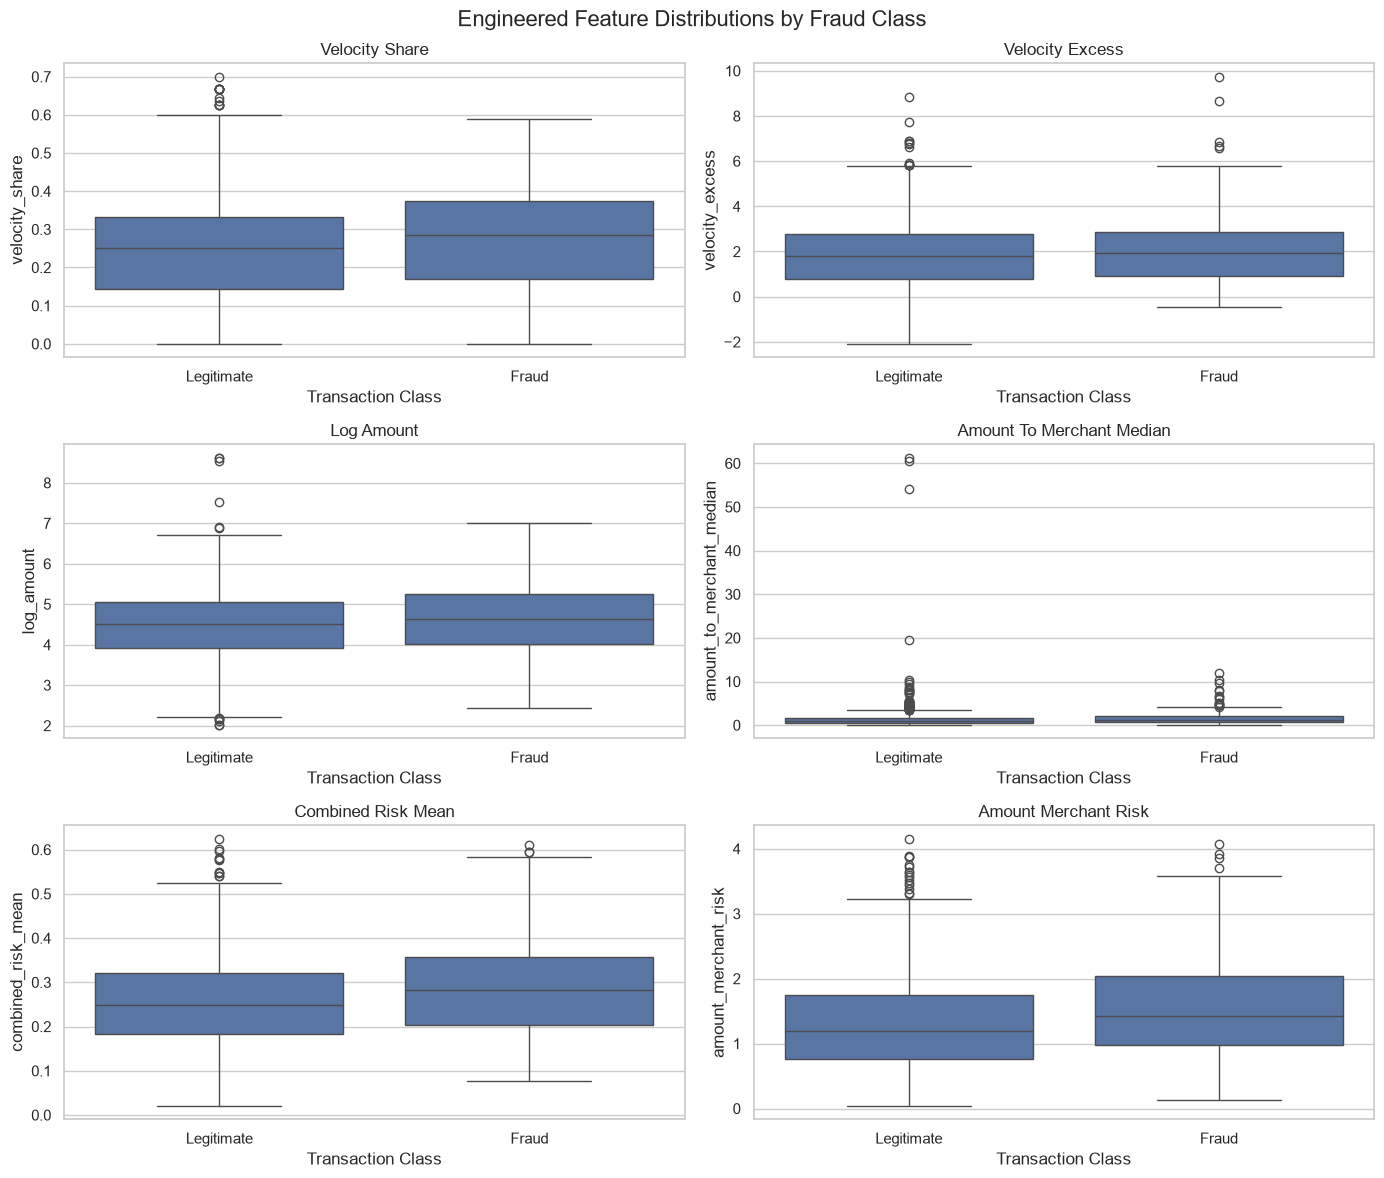

In [42]:
selected_engineered_features = [
    "velocity_share",
    "velocity_excess",
    "log_amount",
    "amount_to_merchant_median",
    "combined_risk_mean",
    "amount_merchant_risk"
]

engineered_eda_df = X_train_engineered.copy()

engineered_eda_df[TARGET] = y_train

fig, axes = plt.subplots(
    3, 2,
    figsize=(14, 12)
)

for feature, ax in zip(
    selected_engineered_features,
    axes.flatten()
):

    sns.boxplot(
        data=engineered_eda_df,
        x=TARGET,
        y=feature,
        ax=ax
    )

    ax.set_title(
        feature.replace("_", " ").title()
    )

    ax.set_xticks(
        [0, 1],
        labels=["Legitimate", "Fraud"]
    )

    ax.set_xlabel("Transaction Class")

plt.suptitle(
    "Engineered Feature Distributions by Fraud Class",
    fontsize=16
)

plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "engineered_feature_distributions.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### 4.1 Preliminary Feature Ablation Experiment

Compare the predictive performance of Logistic Regression
using original predictors against original and engineered
predictors.

Both experiments use identical stratified five-fold
cross-validation and preprocessing configurations.

Feature engineering and all learned preprocessing operations
are fitted separately inside each training fold.

No calibration, threshold validation or final test data is
used for this experiment.

In [43]:
from sklearn.compose import (
    ColumnTransformer,
    make_column_selector
)

from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

from sklearn.preprocessing import (
    StandardScaler,
    OneHotEncoder
)

from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_validate


def create_ablation_pipeline(use_engineered):

    numerical_pipeline = Pipeline([
        (
            "imputer",
            SimpleImputer(
                strategy="median",
                add_indicator=True
            )
        ),
        (
            "scaler",
            StandardScaler()
        )
    ])

    categorical_pipeline = Pipeline([
        (
            "imputer",
            SimpleImputer(
                strategy="constant",
                fill_value="Missing"
            )
        ),
        (
            "encoder",
            OneHotEncoder(
                handle_unknown="ignore"
            )
        )
    ])

    preprocessing = ColumnTransformer([
        (
            "numerical",
            numerical_pipeline,
            make_column_selector(
                dtype_include=np.number
            )
        ),
        (
            "categorical",
            categorical_pipeline,
            make_column_selector(
                dtype_exclude=np.number
            )
        )
    ])

    return Pipeline([
        (
            "features",
            FraudFeatureEngineer()
            if use_engineered
            else "passthrough"
        ),
        (
            "preprocessing",
            preprocessing
        ),
        (
            "model",
            LogisticRegression(
                max_iter=2000,
                random_state=RANDOM_STATE
            )
        )
    ])

In [44]:
ablation_records = []

ablation_experiments = {
    "Original Features": False,
    "Engineered Features": True
}

for experiment, use_engineered in (
    ablation_experiments.items()
):

    pipeline = create_ablation_pipeline(
        use_engineered
    )

    scores = cross_validate(
        pipeline,
        X_train,
        y_train,
        cv=cv,
        scoring={
            "pr_auc": "average_precision",
            "roc_auc": "roc_auc"
        },
        error_score="raise"
    )

    ablation_records.append({
        "experiment": experiment,
        "predictors": (
            41 if use_engineered else 23
        ),
        "mean_pr_auc": (
            scores["test_pr_auc"].mean()
        ),
        "std_pr_auc": (
            scores["test_pr_auc"].std(ddof=1)
        ),
        "mean_roc_auc": (
            scores["test_roc_auc"].mean()
        ),
        "std_roc_auc": (
            scores["test_roc_auc"].std(ddof=1)
        )
    })

ablation_results = pd.DataFrame(
    ablation_records
)

display(ablation_results)

ablation_results.to_csv(
    METRICS_DIR / "preliminary_feature_ablation.csv",
    index=False
)

,experiment,predictors,mean_pr_auc,std_pr_auc,mean_roc_auc,std_roc_auc
0,Original Features,23,0.2372,0.0251,0.6402,0.0383
1,Engineered Features,41,0.2298,0.0321,0.6320,0.0466


In [45]:
PROCESSED_DIR = (
    PROJECT_ROOT / "data" / "processed"
)

PROCESSED_DIR.mkdir(
    parents=True,
    exist_ok=True
)

processed_partitions = []

for name, dataset in datasets.items():

    # Transform using the already-fitted training transformer
    transformed = feature_engineer.transform(
        dataset[feature_columns]
    )

    # Add metadata for reporting only
    transformed.insert(
        0,
        ID_COLUMN,
        dataset[ID_COLUMN]
    )

    transformed[TARGET] = dataset[TARGET]

    transformed["dataset"] = name

    processed_partitions.append(
        transformed
    )

processed_df = pd.concat(
    processed_partitions,
    ignore_index=True
)

processed_df = processed_df.sort_values(
    ID_COLUMN
).reset_index(drop=True)

assert len(processed_df) == len(df)

assert processed_df[ID_COLUMN].is_unique

assert processed_df.shape[1] == 44

processed_path = (
    PROCESSED_DIR / "02_processed_dataset.csv"
)

processed_df.to_csv(
    processed_path,
    index=False
)

print("Processed dataset saved successfully.")

print("Dataset shape:", processed_df.shape)

print("Saved location:", processed_path)

Processed dataset saved successfully.
Dataset shape: (3000, 44)
Saved location: d:\Internship Tasks\Task - 2026.10.22\fraud-risk-intelligence-engine\data\processed\02_processed_dataset.csv


## 5. Preprocessing and Imbalanced Learning

Develop reusable preprocessing pipelines for numerical,
categorical and engineered features.

Compare standard learning, class weighting and controlled
Random Oversampling using identical stratified five-fold
cross-validation.

All learned preprocessing and resampling operations are
restricted to the corresponding training folds.

In [46]:
from src.preprocessing import (
    build_preprocessor,
    build_model_pipeline
)

# Fit for inspection purposes only
preprocessor = build_preprocessor()

X_train_preprocessed = preprocessor.fit_transform(
    X_train
)

processed_feature_names = (
    preprocessor.get_feature_names_out()
)

print("Original shape:", X_train.shape)

print(
    "Preprocessed shape:",
    X_train_preprocessed.shape
)

print(
    "Missing values:",
    np.isnan(X_train_preprocessed).sum()
)

print(
    "Infinite values:",
    np.isinf(X_train_preprocessed).sum()
)

assert np.isfinite(X_train_preprocessed).all()

display(
    pd.DataFrame(
        X_train_preprocessed,
        columns=processed_feature_names,
        index=X_train.index
    ).head()
)

Original shape: (1500, 23)
Preprocessed shape: (1500, 56)
Missing values: 0
Infinite values: 0


,numerical__hour,numerical__day_of_week,numerical__transaction_amount,numerical__distance_from_usual_location_km,numerical__transactions_last_1h,numerical__transactions_last_24h,numerical__account_age_days,numerical__failed_logins_24h,numerical__prior_chargebacks,numerical__device_age_days,numerical__merchant_risk_score,numerical__ip_risk_score,numerical__email_age_days,numerical__login_to_transaction_minutes,numerical__new_device,numerical__billing_address_mismatch,numerical__missingindicator_transaction_amount,numerical__missingindicator_distance_from_usual_location_km,numerical__missingindicator_merchant_risk_score,numerical__missingindicator_ip_risk_score,numerical__missingindicator_login_to_transaction_minutes,categorical__card_presence_Not present,categorical__card_presence_Present,categorical__channel_ATM,categorical__channel_E-commerce,categorical__channel_Mobile App,categorical__channel_POS,categorical__country_Australia,categorical__country_India,categorical__country_Singapore,categorical__country_Sri Lanka,categorical__country_UAE,categorical__country_UK,categorical__country_USA,categorical__device_type_Android,categorical__device_type_Other,categorical__device_type_Windows,categorical__device_type_iOS,categorical__device_type_macOS,categorical__merchant_category_Digital Services,categorical__merchant_category_Electronics,categorical__merchant_category_Fashion,categorical__merchant_category_Fuel,categorical__merchant_category_Gaming,categorical__merchant_category_Grocery,categorical__merchant_category_Healthcare,categorical__merchant_category_Jewelry,categorical__merchant_category_Restaurants,categorical__merchant_category_Travel,categorical__authentication_level_Missing,categorical__authentication_level_Standard,categorical__authentication_level_Strong,categorical__customer_tier_Basic,categorical__customer_tier_Gold,categorical__customer_tier_Platinum,categorical__customer_tier_Silver
1609,-1.1233,-0.5014,1.0102,-0.1929,0.5526,-0.6147,1.2853,-0.5749,-0.3602,0.6707,-0.3322,-1.3719,0.1228,0.2158,-0.4494,-0.3333,-0.1354,-0.1634,-0.1500,-0.1192,-0.1429,1.0000,0.0000,0.0000,0.0000,0.0000,1.0000,0.0000,0.0000,0.0000,0.0000,0.0000,1.0000,0.0000,0.0000,0.0000,1.0000,0.0000,0.0000,0.0000,1.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,1.0000,1.0000,0.0000,0.0000,0.0000
292,-1.5609,0.5191,-0.1390,0.6957,0.5526,0.7194,-0.6283,1.1814,-0.3602,-1.6276,1.1920,-0.1200,0.5083,-0.7413,-0.4494,-0.3333,-0.1354,-0.1634,-0.1500,-0.1192,-0.1429,0.0000,1.0000,0.0000,1.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,1.0000,0.0000,0.0000,0.0000,1.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,1.0000,0.0000,0.0000,0.0000,0.0000,0.0000,1.0000,0.0000,0.0000,0.0000,0.0000,1.0000
1187,-0.9774,0.0088,-0.2311,-0.2684,-0.7984,-0.1700,-0.0937,1.1814,-0.3602,0.5763,-0.4295,0.1859,0.7954,1.3109,-0.4494,-0.3333,-0.1354,-0.1634,-0.1500,-0.1192,-0.1429,1.0000,0.0000,0.0000,1.0000,0.0000,0.0000,0.0000,0.0000,0.0000,1.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,1.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,1.0000,0.0000,0.0000,0.0000,0.0000,1.0000,1.0000,0.0000,0.0000,0.0000
2286,1.6484,-1.0116,0.1566,-0.3781,-0.7984,-0.3924,-0.5992,-0.5749,2.4538,0.3188,0.4461,0.3352,-1.2206,-0.7558,-0.4494,-0.3333,-0.1354,-0.1634,-0.1500,-0.1192,-0.1429,0.0000,1.0000,0.0000,0.0000,1.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,1.0000,0.0000,0.0000,0.0000,1.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,1.0000,0.0000,1.0000,0.0000,0.0000,0.0000,1.0000,0.0000
9,-0.5398,1.0293,-0.4010,-0.0057,-1.4739,0.0523,0.3053,-0.5749,-0.3602,1.7148,1.8340,0.6838,0.0833,-1.0148,-0.4494,-0.3333,-0.1354,-0.1634,-0.1500,-0.1192,-0.1429,1.0000,0.0000,0.0000,0.0000,0.0000,1.0000,0.0000,0.0000,0.0000,1.0000,0.0000,0.0000,0.0000,0.0000,0.0000,1.0000,0.0000,0.0000,0.0000,1.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,1.0000,0.0000,1.0000,0.0000,0.0000,0.0000


In [47]:
from sklearn.linear_model import LogisticRegression

engineered_check_pipeline = build_model_pipeline(
    model=LogisticRegression(
        max_iter=2000,
        random_state=RANDOM_STATE
    ),
    use_engineered=True,
    random_state=RANDOM_STATE
)

engineered_check_pipeline.fit(
    X_train,
    y_train
)

engineered_names = (
    engineered_check_pipeline
    .named_steps["preprocessing"]
    .get_feature_names_out()
)

print(
    "Features after engineering and preprocessing:",
    len(engineered_names)
)

# Check predictions on training examples
sample_probabilities = (
    engineered_check_pipeline.predict_proba(
        X_train.iloc[:5]
    )
)

assert sample_probabilities.shape == (5, 2)

assert np.isfinite(sample_probabilities).all()

assert np.allclose(
    sample_probabilities.sum(axis=1),
    1
)

print("Engineered pipeline compatibility check passed.")

Features after engineering and preprocessing: 81
Engineered pipeline compatibility check passed.


In [48]:
simulated_transaction = X_train.iloc[[0]].copy()

simulated_transaction["transaction_amount"] = np.nan

simulated_transaction["authentication_level"] = np.nan

simulated_transaction["merchant_category"] = (
    "Unknown_Merchant"
)

transformed_sample = preprocessor.transform(
    simulated_transaction
)

assert transformed_sample.shape == (1, 56)

assert np.isfinite(transformed_sample).all()

print("Missing value handling: Passed")

print("Unknown category handling: Passed")

print(
    "Transformed sample shape:",
    transformed_sample.shape
)

Missing value handling: Passed
Unknown category handling: Passed
Transformed sample shape: (1, 56)


### 5.1 Imbalanced Learning Experiments

Compare three Logistic Regression configurations:

1. Standard learning without imbalance correction.
2. Balanced class weighting.
3. Controlled Random Oversampling with a 0.5 ratio.

Original predictors are used to isolate the effect of
class imbalance handling from feature engineering.

All experiments use the same training data,
preprocessing and cross-validation folds.

In [49]:
imbalance_configs = {
    "Standard": {
        "class_weight": None,
        "sampling_ratio": None
    },

    "Class Weighting": {
        "class_weight": "balanced",
        "sampling_ratio": None
    },

    "Random Oversampling": {
        "class_weight": None,
        "sampling_ratio": 0.5
    }
}

imbalance_pipelines = {}

for name, config in imbalance_configs.items():

    model = LogisticRegression(
        max_iter=2000,
        class_weight=config["class_weight"],
        random_state=RANDOM_STATE
    )

    imbalance_pipelines[name] = (
        build_model_pipeline(
            model=model,
            use_engineered=False,
            sampling_ratio=config["sampling_ratio"],
            random_state=RANDOM_STATE
        )
    )

print(
    "Configured experiments:",
    list(imbalance_pipelines)
)

Configured experiments: ['Standard', 'Class Weighting', 'Random Oversampling']


In [50]:
from sklearn.base import clone

from src.evaluation import (
    evaluate_binary_predictions
)

imbalance_fold_records = []
resampling_records = []

for name, template in imbalance_pipelines.items():

    print(f"\nRunning experiment: {name}")

    for fold, (train_index, val_index) in enumerate(
        cv.split(X_train, y_train),
        start=1
    ):

        # Create a fresh pipeline for every fold
        pipeline = clone(template)

        # Training fold
        X_fold_train = X_train.iloc[train_index]
        y_fold_train = y_train.iloc[train_index]

        # Validation fold
        X_fold_val = X_train.iloc[val_index]
        y_fold_val = y_train.iloc[val_index]

        # All learned operations happen here
        pipeline.fit(
            X_fold_train,
            y_fold_train
        )

        # Validation data is never resampled
        probabilities = pipeline.predict_proba(
            X_fold_val
        )[:, 1]

        assert len(probabilities) == len(y_fold_val)

        metrics = evaluate_binary_predictions(
            y_fold_val,
            probabilities,
            threshold=0.50
        )

        imbalance_fold_records.append({
            "strategy": name,
            "fold": fold,
            "validation_count": len(y_fold_val),
            **metrics
        })

        # Audit actual training resampling
        if name == "Random Oversampling":

            sampler = pipeline.named_steps["sampler"]

            y_resampled = y_fold_train.iloc[
                sampler.sample_indices_
            ]

            resampling_records.append({
                "fold": fold,

                "original_training_count": len(
                    y_fold_train
                ),

                "original_fraud_count": int(
                    y_fold_train.sum()
                ),

                "resampled_training_count": len(
                    y_resampled
                ),

                "resampled_fraud_count": int(
                    y_resampled.sum()
                ),

                "validation_count": len(
                    y_fold_val
                )
            })

        print(
            f"Fold {fold}: "
            f"PR-AUC={metrics['pr_auc']:.4f}, "
            f"Recall={metrics['recall']:.4f}, "
            f"F1={metrics['f1']:.4f}"
        )

imbalance_fold_results = pd.DataFrame(
    imbalance_fold_records
)

assert len(imbalance_fold_results) == 15

imbalance_fold_results.to_csv(
    METRICS_DIR / "imbalance_cv_fold_results.csv",
    index=False
)

display(imbalance_fold_results)


Running experiment: Standard
Fold 1: PR-AUC=0.2031, Recall=0.0556, F1=0.0909
Fold 2: PR-AUC=0.2179, Recall=0.0556, F1=0.1000
Fold 3: PR-AUC=0.2515, Recall=0.0278, F1=0.0513
Fold 4: PR-AUC=0.2569, Recall=0.0541, F1=0.1000
Fold 5: PR-AUC=0.2570, Recall=0.0541, F1=0.1000

Running experiment: Class Weighting
Fold 1: PR-AUC=0.2085, Recall=0.5000, F1=0.2432
Fold 2: PR-AUC=0.2206, Recall=0.4444, F1=0.2254
Fold 3: PR-AUC=0.2454, Recall=0.6111, F1=0.2876
Fold 4: PR-AUC=0.2639, Recall=0.5405, F1=0.2817
Fold 5: PR-AUC=0.2548, Recall=0.5946, F1=0.3143

Running experiment: Random Oversampling
Fold 1: PR-AUC=0.2050, Recall=0.3056, F1=0.2619
Fold 2: PR-AUC=0.2155, Recall=0.2500, F1=0.2118
Fold 3: PR-AUC=0.2084, Recall=0.2778, F1=0.2469
Fold 4: PR-AUC=0.2930, Recall=0.3243, F1=0.3000
Fold 5: PR-AUC=0.2807, Recall=0.2973, F1=0.2895


,strategy,fold,validation_count,pr_auc,roc_auc,precision,recall,f1,fpr,brier,tn,fp,fn,tp
0,Standard,1,300,0.2031,0.5977,0.2500,0.0556,0.0909,0.0227,0.1146,258,6,34,2
1,Standard,2,300,0.2179,0.6186,0.5000,0.0556,0.1000,0.0076,0.1058,262,2,34,2
2,Standard,3,300,0.2515,0.6498,0.3333,0.0278,0.0513,0.0076,0.1024,262,2,35,1
3,Standard,4,300,0.2569,0.6356,0.6667,0.0541,0.1000,0.0038,0.1049,262,1,35,2
4,Standard,5,300,0.2570,0.6993,0.6667,0.0541,0.1000,0.0038,0.1025,262,1,35,2
5,Class Weighting,1,300,0.2085,0.5996,0.1607,0.5000,0.2432,0.3561,0.2381,170,94,18,18
6,Class Weighting,2,300,0.2206,0.6116,0.1509,0.4444,0.2254,0.3409,0.2248,174,90,20,16
7,Class Weighting,3,300,0.2454,0.6519,0.1880,0.6111,0.2876,0.3598,0.2254,169,95,14,22
8,Class Weighting,4,300,0.2639,0.6435,0.1905,0.5405,0.2817,0.3232,0.2215,178,85,17,20
9,Class Weighting,5,300,0.2548,0.7079,0.2136,0.5946,0.3143,0.3080,0.2023,182,81,15,22


In [51]:
resampling_report = pd.DataFrame(
    resampling_records
)

display(resampling_report)

assert (
    resampling_report["validation_count"] == 300
).all()

assert (
    resampling_report["original_training_count"] == 1200
).all()

assert (
    resampling_report["resampled_training_count"]
    > resampling_report["original_training_count"]
).all()

resampling_report.to_csv(
    METRICS_DIR / "resampling_audit.csv",
    index=False
)

print("Training-only resampling checks passed!")

,fold,original_training_count,original_fraud_count,resampled_training_count,resampled_fraud_count,validation_count
0,1,1200,146,1581,527,300
1,2,1200,146,1581,527,300
2,3,1200,146,1581,527,300
3,4,1200,145,1582,527,300
4,5,1200,145,1582,527,300


Training-only resampling checks passed!


In [52]:
comparison_metrics = [
    "pr_auc",
    "roc_auc",
    "precision",
    "recall",
    "f1",
    "fpr",
    "brier"
]

imbalance_summary = (
    imbalance_fold_results
    .groupby("strategy", sort=False)[comparison_metrics]
    .agg(["mean", "std"])
)

imbalance_summary.columns = [
    f"{metric}_{stat}"
    for metric, stat in imbalance_summary.columns
]

imbalance_summary = (
    imbalance_summary.reset_index()
)

display(imbalance_summary)

imbalance_summary.to_csv(
    METRICS_DIR / "imbalance_comparison.csv",
    index=False
)

,strategy,pr_auc_mean,pr_auc_std,roc_auc_mean,roc_auc_std,precision_mean,precision_std,recall_mean,recall_std,f1_mean,f1_std,fpr_mean,fpr_std,brier_mean,brier_std
0,Standard,0.2372,0.0251,0.6402,0.0383,0.4833,0.1900,0.0494,0.0121,0.0884,0.0211,0.0091,0.0078,0.1061,0.0050
1,Class Weighting,0.2386,0.0234,0.6429,0.0423,0.1808,0.0251,0.5381,0.0685,0.2704,0.0358,0.3376,0.0220,0.2224,0.0129
2,Random Oversampling,0.2405,0.0427,0.6337,0.0392,0.2392,0.0415,0.2910,0.0284,0.2620,0.0352,0.1297,0.0178,0.1502,0.0115


In [53]:
imbalance_confusion = (
    imbalance_fold_results
    .groupby("strategy", sort=False)[
        ["tn", "fp", "fn", "tp"]
    ]
    .sum()
    .reset_index()
)

display(imbalance_confusion)

imbalance_confusion.to_csv(
    METRICS_DIR / "imbalance_confusion_summary.csv",
    index=False
)

,strategy,tn,fp,fn,tp
0,Standard,1306,12,173,9
1,Class Weighting,873,445,84,98
2,Random Oversampling,1147,171,129,53


In [54]:
cost_scenarios = {
    "Low fraud loss": 5,
    "Moderate fraud loss": 10,
    "High fraud loss": 20
}

cost_records = []

for scenario, fn_cost in cost_scenarios.items():

    fp_cost = 1

    for _, row in imbalance_confusion.iterrows():

        total_cost = (
            row["fp"] * fp_cost
            + row["fn"] * fn_cost
        )

        baseline_cost = (
            y_train.sum() * fn_cost
        )

        cost_records.append({
            "scenario": scenario,
            "strategy": row["strategy"],
            "fp_unit_cost": fp_cost,
            "fn_unit_cost": fn_cost,
            "false_positives": row["fp"],
            "false_negatives": row["fn"],
            "total_cost": total_cost,

            "cost_per_transaction": (
                total_cost / len(y_train)
            ),

            "approve_all_cost": baseline_cost,

            "cost_saving_percentage": (
                (baseline_cost - total_cost)
                / baseline_cost * 100
            )
        })

imbalance_cost_results = pd.DataFrame(
    cost_records
)

display(imbalance_cost_results)

imbalance_cost_results.to_csv(
    METRICS_DIR / "imbalance_cost_comparison.csv",
    index=False
)

,scenario,strategy,fp_unit_cost,fn_unit_cost,false_positives,false_negatives,total_cost,cost_per_transaction,approve_all_cost,cost_saving_percentage
0,Low fraud loss,Standard,1,5,12,173,877,0.5847,910,3.6264
1,Low fraud loss,Class Weighting,1,5,445,84,865,0.5767,910,4.9451
2,Low fraud loss,Random Oversampling,1,5,171,129,816,0.5440,910,10.3297
3,Moderate fraud loss,Standard,1,10,12,173,1742,1.1613,1820,4.2857
4,Moderate fraud loss,Class Weighting,1,10,445,84,1285,0.8567,1820,29.3956
5,Moderate fraud loss,Random Oversampling,1,10,171,129,1461,0.9740,1820,19.7253
6,High fraud loss,Standard,1,20,12,173,3472,2.3147,3640,4.6154
7,High fraud loss,Class Weighting,1,20,445,84,2125,1.4167,3640,41.6209
8,High fraud loss,Random Oversampling,1,20,171,129,2751,1.8340,3640,24.4231


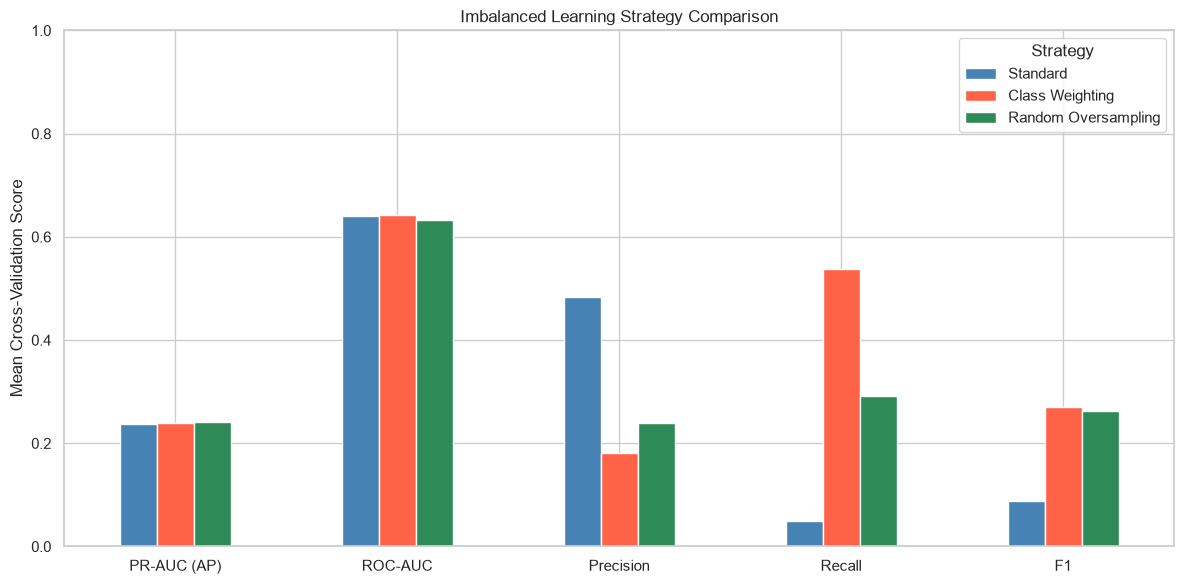

In [55]:
plot_metrics = [
    "pr_auc_mean",
    "roc_auc_mean",
    "precision_mean",
    "recall_mean",
    "f1_mean"
]

plot_data = (
    imbalance_summary
    .set_index("strategy")[plot_metrics]
    .T
)

plot_data.index = [
    "PR-AUC (AP)",
    "ROC-AUC",
    "Precision",
    "Recall",
    "F1"
]

ax = plot_data.plot(
    kind="bar",
    figsize=(12, 6),
    color=[
        "steelblue",
        "tomato",
        "seagreen"
    ]
)

ax.set_title(
    "Imbalanced Learning Strategy Comparison"
)

ax.set_ylabel("Mean Cross-Validation Score")

ax.set_ylim(0, 1)

plt.xticks(rotation=0)

plt.legend(title="Strategy")

plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "imbalance_model_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

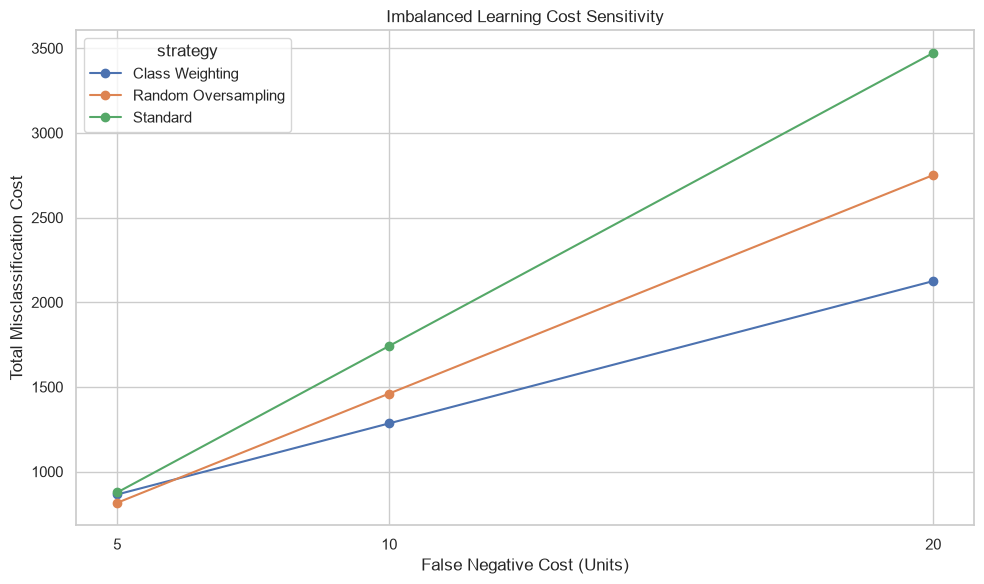

In [56]:
cost_plot = imbalance_cost_results.pivot(
    index="fn_unit_cost",
    columns="strategy",
    values="total_cost"
)

ax = cost_plot.plot(
    kind="line",
    marker="o",
    figsize=(10, 6)
)

ax.set_title(
    "Imbalanced Learning Cost Sensitivity"
)

ax.set_xlabel("False Negative Cost (Units)")

ax.set_ylabel("Total Misclassification Cost")

ax.set_xticks([5, 10, 20])

plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "imbalance_cost_sensitivity.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## 6. Baseline and Advanced Model Development

Develop Logistic Regression, Random Forest and XGBoost
classification models.

Perform hyperparameter optimization using RandomizedSearchCV
with stratified five-fold cross-validation.

Compare original and engineered feature configurations
using consistent evaluation metrics and search budgets.

Investigate model overfitting and sensitivity to potentially
leaking predictors.

The calibration, threshold validation and final test datasets
are excluded from model training and hyperparameter tuning.

In [57]:
from src.model_training import (
    create_model_search,
    make_scoring
)

from sklearn.base import clone
from sklearn.model_selection import cross_validate

import time
import joblib

MODELS_DIR = (
    PROJECT_ROOT / "outputs" / "models"
)

MODELS_DIR.mkdir(
    parents=True,
    exist_ok=True
)

model_names = [
    "Logistic Regression",
    "Random Forest",
    "XGBoost"
]

model_searches = {}
candidate_models = {}

model_records = []
model_fold_records = []

print("Model training configuration initialized.")

Model training configuration initialized.


In [58]:
for name in model_names:

    for use_engineered in [False, True]:

        feature_set = (
            "Engineered"
            if use_engineered
            else "Original"
        )

        candidate = f"{name} | {feature_set}"

        print(f"\nTraining: {candidate}")

        start_time = time.perf_counter()

        search = create_model_search(
            name=name,
            use_engineered=use_engineered,
            cv=cv,
            random_state=RANDOM_STATE,
            n_iter=12,
            n_jobs=2
        )

        search.fit(
            X_train,
            y_train
        )

        elapsed = time.perf_counter() - start_time

        model_searches[candidate] = search

        candidate_models[candidate] = (
            search.best_estimator_
        )

        i = search.best_index_
        results = search.cv_results_

        record = {
            "candidate": candidate,
            "model": name,
            "feature_set": feature_set,

            "predictors": (
                41 if use_engineered else 23
            ),

            "best_params": str(
                search.best_params_
            ),

            "training_seconds": elapsed,

            "train_pr_auc_mean": results[
                "mean_train_pr_auc"
            ][i]
        }

        for metric in make_scoring():

            sign = (
                -1 if metric.startswith("neg_")
                else 1
            )

            clean = metric.removeprefix("neg_")

            record[f"{clean}_mean"] = (
                sign * results[
                    f"mean_test_{metric}"
                ][i]
            )

            record[f"{clean}_std"] = results[
                f"std_test_{metric}"
            ][i]

        model_records.append(record)

        # Save best configuration's fold-level results
        for fold in range(cv.get_n_splits()):

            fold_record = {
                "candidate": candidate,
                "fold": fold + 1
            }

            for metric in make_scoring():

                sign = (
                    -1 if metric.startswith("neg_")
                    else 1
                )

                clean = metric.removeprefix("neg_")

                fold_record[clean] = (
                    sign * results[
                        f"split{fold}_test_{metric}"
                    ][i]
                )

            model_fold_records.append(
                fold_record
            )

        # Save complete tuning history
        file_name = (
            candidate.lower()
            .replace(" | ", "_")
            .replace(" ", "_")
        )

        pd.DataFrame(results).to_csv(
            METRICS_DIR / (
                f"tuning_{file_name}.csv"
            ),
            index=False
        )

        print(
            f"Best PR-AUC: "
            f"{search.best_score_:.4f}"
        )

        print("Best parameters:", search.best_params_)

        print(f"Training time: {elapsed:.2f} seconds")

print("\nAll model configurations trained successfully.")


Training: Logistic Regression | Original
Best PR-AUC: 0.2473
Best parameters: {'sampler': RandomOverSampler(random_state=42, sampling_strategy=0.5), 'model__class_weight': None, 'model__C': 0.1}
Training time: 10.59 seconds

Training: Logistic Regression | Engineered
Best PR-AUC: 0.2520
Best parameters: {'sampler': 'passthrough', 'model__class_weight': 'balanced', 'model__C': 0.01}
Training time: 4.40 seconds

Training: Random Forest | Original
Best PR-AUC: 0.2414
Best parameters: {'sampler': 'passthrough', 'model__n_estimators': 100, 'model__min_samples_leaf': 2, 'model__max_features': 'sqrt', 'model__max_depth': 5, 'model__class_weight': None}
Training time: 15.12 seconds

Training: Random Forest | Engineered
Best PR-AUC: 0.2651
Best parameters: {'sampler': 'passthrough', 'model__n_estimators': 100, 'model__min_samples_leaf': 5, 'model__max_features': 'sqrt', 'model__max_depth': 5, 'model__class_weight': None}
Training time: 22.08 seconds

Training: XGBoost | Original
Best PR-AUC: 0

In [59]:
model_comparison = pd.DataFrame(
    model_records
).sort_values(
    "pr_auc_mean",
    ascending=False
).reset_index(drop=True)

model_fold_results = pd.DataFrame(
    model_fold_records
)

display(
    model_comparison[
        [
            "candidate",
            "predictors",
            "pr_auc_mean",
            "pr_auc_std",
            "roc_auc_mean",
            "precision_mean",
            "recall_mean",
            "f1_mean",
            "fpr_mean",
            "brier_mean"
        ]
    ]
)

model_comparison.to_csv(
    METRICS_DIR / "tuned_model_comparison.csv",
    index=False
)

model_fold_results.to_csv(
    METRICS_DIR / "tuned_model_fold_results.csv",
    index=False
)

,candidate,predictors,pr_auc_mean,pr_auc_std,roc_auc_mean,precision_mean,recall_mean,f1_mean,fpr_mean,brier_mean
0,Random Forest | Engineered,41,0.2651,0.0385,0.6649,0.0000,0.0000,0.0000,-0.0000,0.1014
1,XGBoost | Engineered,41,0.2647,0.0463,0.6462,0.0000,0.0000,0.0000,-0.0000,0.1019
2,Logistic Regression | Engineered,41,0.2520,0.0271,0.6509,0.1781,0.5167,0.2643,0.3315,0.2184
3,XGBoost | Original,23,0.2519,0.0498,0.6376,0.0000,0.0000,0.0000,-0.0000,0.1026
4,Logistic Regression | Original,23,0.2473,0.0374,0.6394,0.2530,0.2800,0.2647,0.1168,0.1469
5,Random Forest | Original,23,0.2414,0.0326,0.6693,0.0000,0.0000,0.0000,-0.0000,0.1032


In [60]:
for candidate, search in model_searches.items():

    print(f"\n{candidate}")

    print("-" * 50)

    for parameter, value in (
        search.best_params_.items()
    ):

        print(f"{parameter}: {value}")


Logistic Regression | Original
--------------------------------------------------
sampler: RandomOverSampler(random_state=42, sampling_strategy=0.5)
model__class_weight: None
model__C: 0.1

Logistic Regression | Engineered
--------------------------------------------------
sampler: passthrough
model__class_weight: balanced
model__C: 0.01

Random Forest | Original
--------------------------------------------------
sampler: passthrough
model__n_estimators: 100
model__min_samples_leaf: 2
model__max_features: sqrt
model__max_depth: 5
model__class_weight: None

Random Forest | Engineered
--------------------------------------------------
sampler: passthrough
model__n_estimators: 100
model__min_samples_leaf: 5
model__max_features: sqrt
model__max_depth: 5
model__class_weight: None

XGBoost | Original
--------------------------------------------------
sampler: passthrough
model__subsample: 0.8
model__scale_pos_weight: 1.0
model__reg_lambda: 5
model__n_estimators: 100
model__min_child_weight:

### 6.1 Tuned Feature Ablation Analysis

Compare original and engineered feature configurations
across Logistic Regression, Random Forest and XGBoost.

Both configurations use identical cross-validation folds,
hyperparameter search spaces and search budgets.

The comparison evaluates the incremental predictive value
of engineered features after hyperparameter optimization.

In [61]:
feature_ablation = model_comparison.pivot(
    index="model",
    columns="feature_set",
    values="pr_auc_mean"
)

feature_ablation = feature_ablation[
    ["Original", "Engineered"]
]

feature_ablation["absolute_improvement"] = (
    feature_ablation["Engineered"]
    - feature_ablation["Original"]
)

feature_ablation["relative_improvement_pct"] = (
    feature_ablation["absolute_improvement"]
    / feature_ablation["Original"] * 100
)

display(feature_ablation)

feature_ablation.to_csv(
    METRICS_DIR / "advanced_feature_ablation.csv"
)

feature_set,Original,Engineered,absolute_improvement,relative_improvement_pct
model,,,,
Logistic Regression,0.2473,0.2520,0.0046,1.8743
Random Forest,0.2414,0.2651,0.0237,9.8350
XGBoost,0.2519,0.2647,0.0128,5.0901


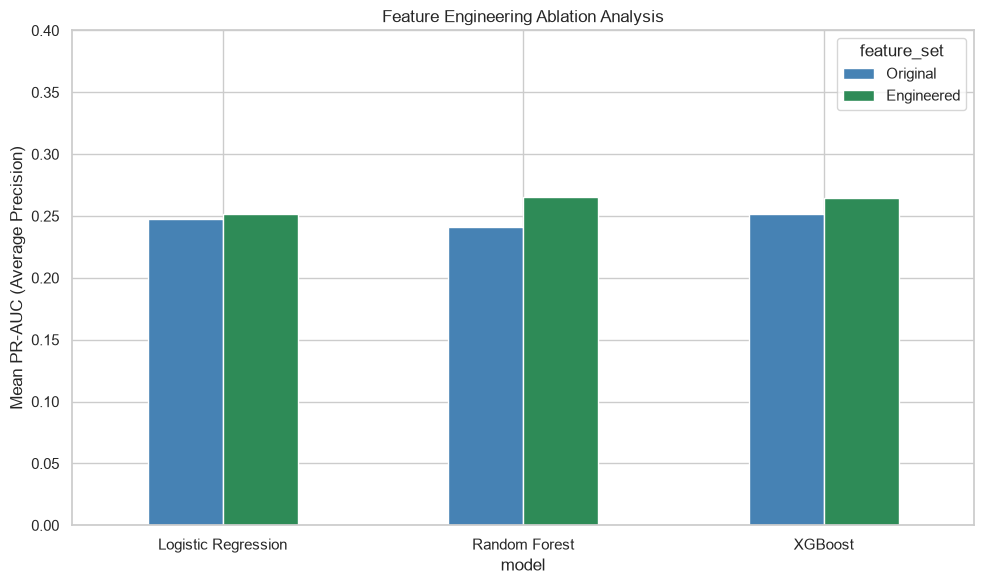

In [62]:
ax = feature_ablation[
    ["Original", "Engineered"]
].plot(
    kind="bar",
    figsize=(10, 6),
    color=["steelblue", "seagreen"]
)

ax.set_title(
    "Feature Engineering Ablation Analysis"
)

ax.set_ylabel(
    "Mean PR-AUC (Average Precision)"
)

ax.set_ylim(0, 0.4)

plt.xticks(rotation=0)

plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "advanced_feature_ablation.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [63]:
overfitting_report = model_comparison[
    [
        "candidate",
        "train_pr_auc_mean",
        "pr_auc_mean"
    ]
].copy()

overfitting_report["generalization_gap"] = (
    overfitting_report["train_pr_auc_mean"]
    - overfitting_report["pr_auc_mean"]
)

display(overfitting_report)

overfitting_report.to_csv(
    METRICS_DIR / "model_overfitting_analysis.csv",
    index=False
)

,candidate,train_pr_auc_mean,pr_auc_mean,generalization_gap
0,Random Forest | Engineered,0.6216,0.2651,0.3565
1,XGBoost | Engineered,0.5240,0.2647,0.2593
2,Logistic Regression | Engineered,0.3247,0.2520,0.0727
3,XGBoost | Original,0.5054,0.2519,0.2535
4,Logistic Regression | Original,0.3131,0.2473,0.0658
5,Random Forest | Original,0.7797,0.2414,0.5383


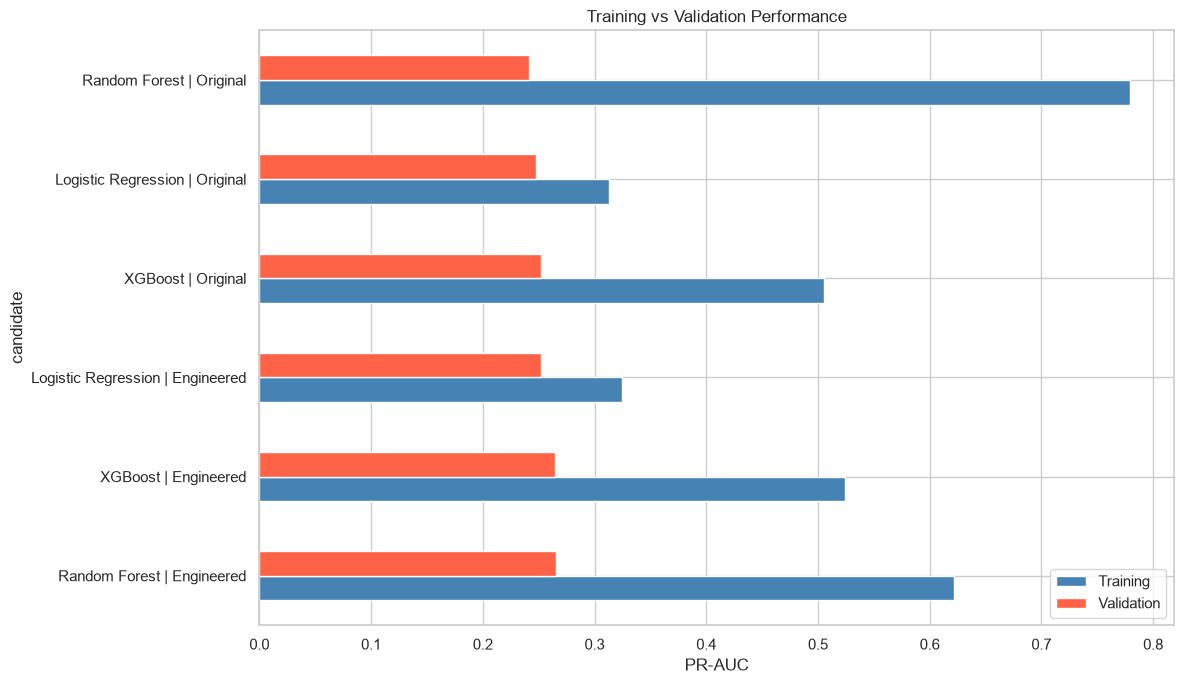

In [64]:
ax = overfitting_report.set_index(
    "candidate"
)[
    ["train_pr_auc_mean", "pr_auc_mean"]
].plot(
    kind="barh",
    figsize=(12, 7),
    color=["steelblue", "tomato"]
)

ax.set_title(
    "Training vs Validation Performance"
)

ax.set_xlabel("PR-AUC")

ax.legend(["Training", "Validation"])

plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "model_overfitting_analysis.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [65]:
stability_report = (
    model_comparison[
        [
            "candidate",
            "pr_auc_mean",
            "pr_auc_std",
            "roc_auc_mean",
            "roc_auc_std"
        ]
    ]
    .sort_values(
        "pr_auc_mean",
        ascending=False
    )
)

display(stability_report)

stability_report.to_csv(
    METRICS_DIR / "model_stability_report.csv",
    index=False
)

,candidate,pr_auc_mean,pr_auc_std,roc_auc_mean,roc_auc_std
0,Random Forest | Engineered,0.2651,0.0385,0.6649,0.0385
1,XGBoost | Engineered,0.2647,0.0463,0.6462,0.0559
2,Logistic Regression | Engineered,0.2520,0.0271,0.6509,0.0378
3,XGBoost | Original,0.2519,0.0498,0.6376,0.0398
4,Logistic Regression | Original,0.2473,0.0374,0.6394,0.0331
5,Random Forest | Original,0.2414,0.0326,0.6693,0.0293


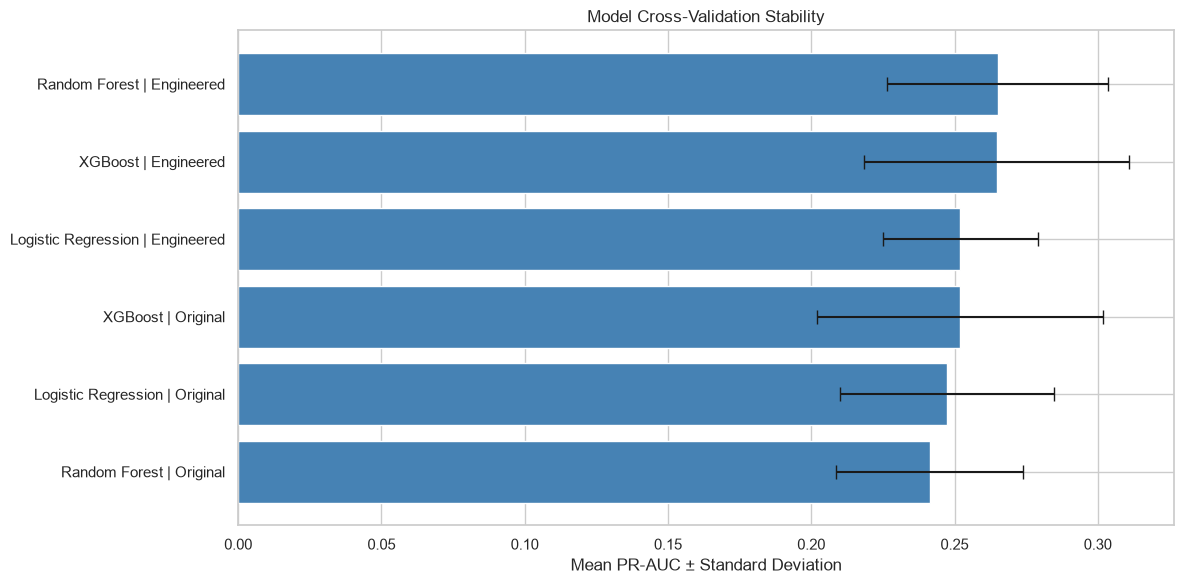

In [66]:
fig, ax = plt.subplots(
    figsize=(12, 6)
)

ax.barh(
    stability_report["candidate"],
    stability_report["pr_auc_mean"],
    xerr=stability_report["pr_auc_std"],
    color="steelblue",
    capsize=5
)

ax.set_title(
    "Model Cross-Validation Stability"
)

ax.set_xlabel(
    "Mean PR-AUC ± Standard Deviation"
)

ax.invert_yaxis()

fig.tight_layout()

fig.savefig(
    FIGURES_DIR / "model_cv_stability.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### 6.2 Potential Leakage Feature Sensitivity

Evaluate model performance after excluding predictors
whose point-in-time availability cannot be verified.

A fixed, tuned original-feature model is evaluated using
the complete predictor set and a restricted predictor set.

This experiment measures predictive dependence on these
variables. It does not prove that actual leakage exists.

In [67]:
potential_leakage_features = [
    "prior_chargebacks",
    "merchant_risk_score",
    "ip_risk_score",
    "authentication_level",
    "transactions_last_1h",
    "transactions_last_24h",
    "distance_from_usual_location_km",
    "failed_logins_24h",
    "login_to_transaction_minutes",
    "new_device",
    "billing_address_mismatch",
    "account_age_days",
    "device_age_days",
    "email_age_days"
]

X_train_restricted = X_train.drop(
    columns=potential_leakage_features
)

print(
    "Full predictors:",
    X_train.shape[1]
)

print(
    "Restricted predictors:",
    X_train_restricted.shape[1]
)

print("\nRemaining predictors:")

print(
    X_train_restricted.columns.tolist()
)

Full predictors: 23
Restricted predictors: 9

Remaining predictors:
['hour', 'day_of_week', 'transaction_amount', 'card_presence', 'channel', 'country', 'device_type', 'merchant_category', 'customer_tier']


In [68]:
best_original_candidate = model_comparison.loc[
    model_comparison["feature_set"] == "Original"
].iloc[0]["candidate"]

print(
    "Sensitivity experiment model:",
    best_original_candidate
)

reference_model = candidate_models[
    best_original_candidate
]

leakage_records = []

leakage_experiments = {
    "Full Predictor Set": X_train,
    "Restricted Predictor Set": X_train_restricted
}

for name, X_subset in (
    leakage_experiments.items()
):

    scores = cross_validate(
        clone(reference_model),
        X_subset,
        y_train,
        cv=cv,
        scoring=make_scoring(),
        n_jobs=2,
        error_score="raise"
    )

    leakage_records.append({
        "configuration": name,

        "predictors": X_subset.shape[1],

        "pr_auc_mean": scores[
            "test_pr_auc"
        ].mean(),

        "pr_auc_std": scores[
            "test_pr_auc"
        ].std(),

        "roc_auc_mean": scores[
            "test_roc_auc"
        ].mean(),

        "recall_mean": scores[
            "test_recall"
        ].mean(),

        "f1_mean": scores[
            "test_f1"
        ].mean()
    })

leakage_sensitivity_results = pd.DataFrame(
    leakage_records
)

display(leakage_sensitivity_results)

leakage_sensitivity_results.to_csv(
    METRICS_DIR / "leakage_feature_sensitivity.csv",
    index=False
)

Sensitivity experiment model: XGBoost | Original


,configuration,predictors,pr_auc_mean,pr_auc_std,roc_auc_mean,recall_mean,f1_mean
0,Full Predictor Set,23,0.2519,0.0498,0.6376,0.0000,0.0000
1,Restricted Predictor Set,9,0.2040,0.0350,0.5538,0.0000,0.0000


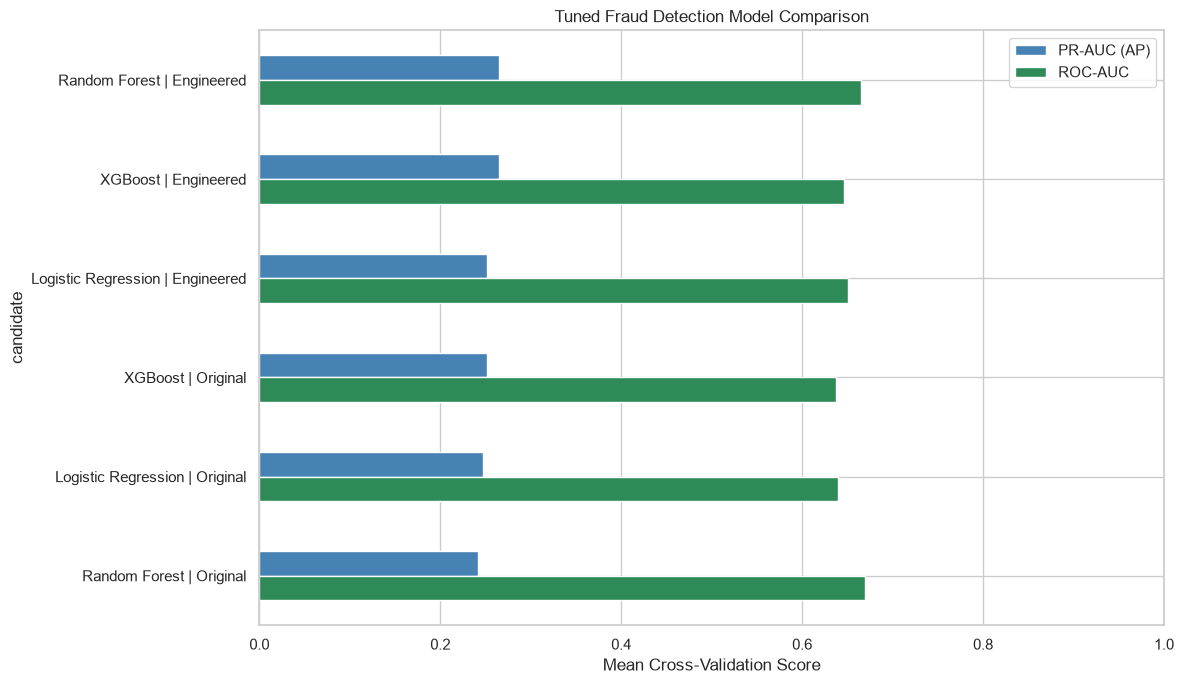

In [69]:
model_plot_data = (
    model_comparison.set_index(
        "candidate"
    )[
        ["pr_auc_mean", "roc_auc_mean"]
    ]
)

ax = model_plot_data.plot(
    kind="barh",
    figsize=(12, 7),
    color=["steelblue", "seagreen"]
)

ax.set_title(
    "Tuned Fraud Detection Model Comparison"
)

ax.set_xlabel(
    "Mean Cross-Validation Score"
)

ax.set_xlim(0, 1)

ax.invert_yaxis()

ax.legend(
    ["PR-AUC (AP)", "ROC-AUC"]
)

plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "tuned_model_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [70]:
best_candidate_name = (
    model_comparison.iloc[0]["candidate"]
)

best_predictive_pipeline = candidate_models[
    best_candidate_name
]

print(
    "Leading predictive candidate:",
    best_candidate_name
)

print(
    "Mean CV PR-AUC:",
    model_comparison.iloc[0]["pr_auc_mean"]
)

print(
    "Number of retained candidates:",
    len(candidate_models)
)

assert len(candidate_models) == 6

Leading predictive candidate: Random Forest | Engineered
Mean CV PR-AUC: 0.26511350846233445
Number of retained candidates: 6


In [71]:
candidate_models_path = (
    MODELS_DIR / "candidate_models.joblib"
)

joblib.dump(
    candidate_models,
    candidate_models_path
)

print(
    "Candidate model pipelines saved successfully."
)

print(
    "Saved location:",
    candidate_models_path
)

Candidate model pipelines saved successfully.
Saved location: d:\Internship Tasks\Task - 2026.10.22\fraud-risk-intelligence-engine\outputs\models\candidate_models.joblib


In [72]:
loaded_candidates = joblib.load(
    candidate_models_path
)

sample_X = X_train.iloc[:10]

for name in candidate_models:

    original_proba = (
        candidate_models[name]
        .predict_proba(sample_X)
    )

    loaded_proba = (
        loaded_candidates[name]
        .predict_proba(sample_X)
    )

    np.testing.assert_allclose(
        original_proba,
        loaded_proba
    )

    print(
        f"{name}: Serialization passed"
    )

print(
    "\nAll model serialization checks passed."
)

Logistic Regression | Original: Serialization passed
Logistic Regression | Engineered: Serialization passed
Random Forest | Original: Serialization passed
Random Forest | Engineered: Serialization passed
XGBoost | Original: Serialization passed
XGBoost | Engineered: Serialization passed

All model serialization checks passed.


## 7. Probability Calibration

Evaluate the reliability of predicted fraud probabilities
using Brier score, log loss and calibration curves.

Compare uncalibrated probabilities, Platt scaling and
isotonic calibration across all six tuned model candidates.

The original classifiers remain frozen during calibration.
Calibrators are fitted using the calibration dataset and
evaluated using the threshold validation dataset.

The final test dataset remains excluded from this analysis.

In [73]:
from src.calibration import (
    fit_calibrator,
    reliability_table,
    evaluate_calibration,
    plot_calibration_curves
)

import joblib
import sklearn

print("Scikit-learn version:", sklearn.__version__)

candidate_models = joblib.load(
    MODELS_DIR / "candidate_models.joblib"
)

assert len(candidate_models) == 6

print("\nAvailable model candidates:")

for name in candidate_models:
    print(name)

print("\nCalibration samples:", len(X_calibration))
print("Calibration fraud cases:", y_calibration.sum())

print("\nThreshold samples:", len(X_threshold))
print("Threshold fraud cases:", y_threshold.sum())

print(
    "Calibration fraud rate:",
    f"{y_calibration.mean():.2%}"
)

print(
    "Threshold fraud rate:",
    f"{y_threshold.mean():.2%}"
)

Scikit-learn version: 1.9.1

Available model candidates:
Logistic Regression | Original
Logistic Regression | Engineered
Random Forest | Original
Random Forest | Engineered
XGBoost | Original
XGBoost | Engineered

Calibration samples: 450
Calibration fraud cases: 55

Threshold samples: 450
Threshold fraud cases: 54
Calibration fraud rate: 12.22%
Threshold fraud rate: 12.00%


In [74]:
baseline_probability = y_train.mean()

baseline_probabilities = np.full(
    len(y_threshold),
    baseline_probability
)

baseline_calibration_metrics = (
    evaluate_calibration(
        y_threshold,
        baseline_probabilities
    )
)

display(
    pd.Series(baseline_calibration_metrics)
)

print(
    f"Baseline probability: "
    f"{baseline_probability:.4f}"
)

print(
    f"Baseline Brier score: "
    f"{baseline_calibration_metrics['brier']:.4f}"
)

brier                 0.1056
log_loss              0.3669
ece                   0.0013
pr_auc                0.1200
roc_auc               0.5000
mean_probability      0.1213
observed_fraud_rate   0.1200
min_probability       0.1213
max_probability       0.1213
dtype: float64

Baseline probability: 0.1213
Baseline Brier score: 0.1056


In [75]:
calibrated_candidates = {}

calibration_probabilities = {}

calibration_records = []

reliability_records = []

for candidate, pipeline in candidate_models.items():

    print(f"\nCalibrating: {candidate}")

    calibrated_candidates[candidate] = {}

    calibration_probabilities[candidate] = {}

    probability_models = {
        "uncalibrated": pipeline
    }

    # Fit both calibration methods
    for method in ["sigmoid", "isotonic"]:

        calibrated_model = fit_calibrator(
            fitted_pipeline=pipeline,
            X_calibration=X_calibration,
            y_calibration=y_calibration,
            method=method
        )

        calibrated_candidates[candidate][method] = (
            calibrated_model
        )

        probability_models[method] = (
            calibrated_model
        )

    # Evaluate on separate threshold validation data
    for method, model in probability_models.items():

        probabilities = model.predict_proba(
            X_threshold
        )[:, 1]

        assert len(probabilities) == len(y_threshold)

        assert np.isfinite(probabilities).all()

        assert (
            (probabilities >= 0)
            & (probabilities <= 1)
        ).all()

        calibration_probabilities[candidate][method] = (
            probabilities
        )

        metrics = evaluate_calibration(
            y_threshold,
            probabilities
        )

        calibration_records.append({
            "candidate": candidate,
            "method": method,
            **metrics
        })

        table = reliability_table(
            y_threshold,
            probabilities
        )

        table["candidate"] = candidate
        table["method"] = method

        reliability_records.append(table)

        print(
            f"{method}: "
            f"Brier={metrics['brier']:.4f}, "
            f"Log Loss={metrics['log_loss']:.4f}"
        )

print("\nAll calibration experiments completed.")


Calibrating: Logistic Regression | Original
uncalibrated: Brier=0.1464, Log Loss=0.4614
sigmoid: Brier=0.1024, Log Loss=0.3508
isotonic: Brier=0.1035, Log Loss=0.4239

Calibrating: Logistic Regression | Engineered
uncalibrated: Brier=0.2207, Log Loss=0.6351
sigmoid: Brier=0.1019, Log Loss=0.3478
isotonic: Brier=0.1056, Log Loss=0.5054

Calibrating: Random Forest | Original
uncalibrated: Brier=0.1044, Log Loss=0.3596
sigmoid: Brier=0.1053, Log Loss=0.3621
isotonic: Brier=0.1042, Log Loss=0.3577

Calibrating: Random Forest | Engineered
uncalibrated: Brier=0.1069, Log Loss=0.3662
sigmoid: Brier=0.1065, Log Loss=0.3675
isotonic: Brier=0.1064, Log Loss=0.3662

Calibrating: XGBoost | Original
uncalibrated: Brier=0.1045, Log Loss=0.3553
sigmoid: Brier=0.1055, Log Loss=0.3607
isotonic: Brier=0.1045, Log Loss=0.3547

Calibrating: XGBoost | Engineered
uncalibrated: Brier=0.1050, Log Loss=0.3566
sigmoid: Brier=0.1067, Log Loss=0.3630
isotonic: Brier=0.1104, Log Loss=0.5201

All calibration exper

In [76]:
calibration_results = pd.DataFrame(
    calibration_records
)

assert len(calibration_results) == 18

calibration_results["brier_skill_score"] = (
    1 - calibration_results["brier"]
    / baseline_calibration_metrics["brier"]
)

calibration_results = (
    calibration_results.sort_values(
        "brier"
    ).reset_index(drop=True)
)

display(calibration_results)

calibration_results.to_csv(
    METRICS_DIR / "calibration_comparison.csv",
    index=False
)

reliability_results = pd.concat(
    reliability_records,
    ignore_index=True
)

reliability_results.to_csv(
    METRICS_DIR / "calibration_reliability_bins.csv",
    index=False
)

,candidate,method,brier,log_loss,ece,pr_auc,roc_auc,mean_probability,observed_fraud_rate,min_probability,max_probability,brier_skill_score
0,Logistic Regression | Engineered,sigmoid,0.1019,0.3478,0.0238,0.2141,0.6877,0.1212,0.1200,0.0280,0.4593,0.0355
1,Logistic Regression | Original,sigmoid,0.1024,0.3508,0.0267,0.2091,0.6781,0.1212,0.1200,0.0240,0.4585,0.0303
2,Logistic Regression | Original,isotonic,0.1035,0.4239,0.0106,0.1786,0.6660,0.1254,0.1200,0.0000,1.0000,0.0197
3,Random Forest | Original,isotonic,0.1042,0.3577,0.0212,0.1710,0.6288,0.1137,0.1200,0.0000,0.4286,0.0134
4,Random Forest | Original,uncalibrated,0.1044,0.3596,0.0277,0.1641,0.6418,0.1184,0.1200,0.0710,0.2529,0.0116
5,XGBoost | Original,isotonic,0.1045,0.3547,0.0346,0.1817,0.6797,0.1220,0.1200,0.0000,0.3636,0.0109
6,XGBoost | Original,uncalibrated,0.1045,0.3553,0.0407,0.1745,0.6706,0.1218,0.1200,0.0453,0.4607,0.0108
7,XGBoost | Engineered,uncalibrated,0.1050,0.3566,0.0322,0.1764,0.6658,0.1225,0.1200,0.0445,0.5804,0.0058
8,Random Forest | Original,sigmoid,0.1053,0.3621,0.0237,0.1641,0.6418,0.1143,0.1200,0.0678,0.3488,0.0025
9,XGBoost | Original,sigmoid,0.1055,0.3607,0.0445,0.1745,0.6706,0.1212,0.1200,0.0743,0.5251,0.0012


In [77]:
brier_comparison = calibration_results.pivot(
    index="candidate",
    columns="method",
    values="brier"
)

log_loss_comparison = calibration_results.pivot(
    index="candidate",
    columns="method",
    values="log_loss"
)

method_order = [
    "uncalibrated",
    "sigmoid",
    "isotonic"
]

brier_comparison = brier_comparison[
    method_order
]

log_loss_comparison = log_loss_comparison[
    method_order
]

print("Brier Score Comparison")
display(brier_comparison)

print("\nLog Loss Comparison")
display(log_loss_comparison)

brier_comparison.to_csv(
    METRICS_DIR / "brier_score_comparison.csv"
)

log_loss_comparison.to_csv(
    METRICS_DIR / "log_loss_comparison.csv"
)

Brier Score Comparison


method,uncalibrated,sigmoid,isotonic
candidate,,,
Logistic Regression | Engineered,0.2207,0.1019,0.1056
Logistic Regression | Original,0.1464,0.1024,0.1035
Random Forest | Engineered,0.1069,0.1065,0.1064
Random Forest | Original,0.1044,0.1053,0.1042
XGBoost | Engineered,0.1050,0.1067,0.1104
XGBoost | Original,0.1045,0.1055,0.1045



Log Loss Comparison


method,uncalibrated,sigmoid,isotonic
candidate,,,
Logistic Regression | Engineered,0.6351,0.3478,0.5054
Logistic Regression | Original,0.4614,0.3508,0.4239
Random Forest | Engineered,0.3662,0.3675,0.3662
Random Forest | Original,0.3596,0.3621,0.3577
XGBoost | Engineered,0.3566,0.3630,0.5201
XGBoost | Original,0.3553,0.3607,0.3547


### 7.1 Reliability Diagram Analysis

Calibration curves compare mean predicted probabilities
with observed fraud rates using five quantile-based bins.

The comparison evaluates whether calibration reduces
systematic overestimation or underestimation of fraud risk.

Bin sample sizes are retained for interpretation.

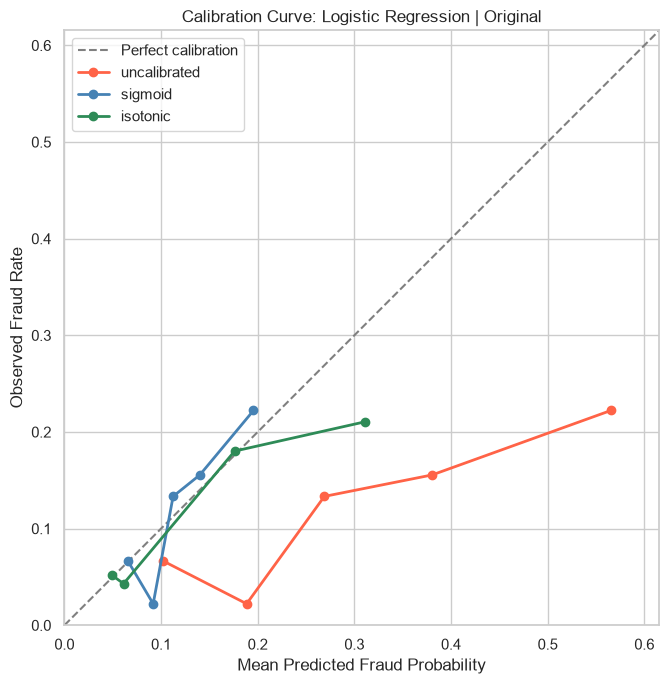

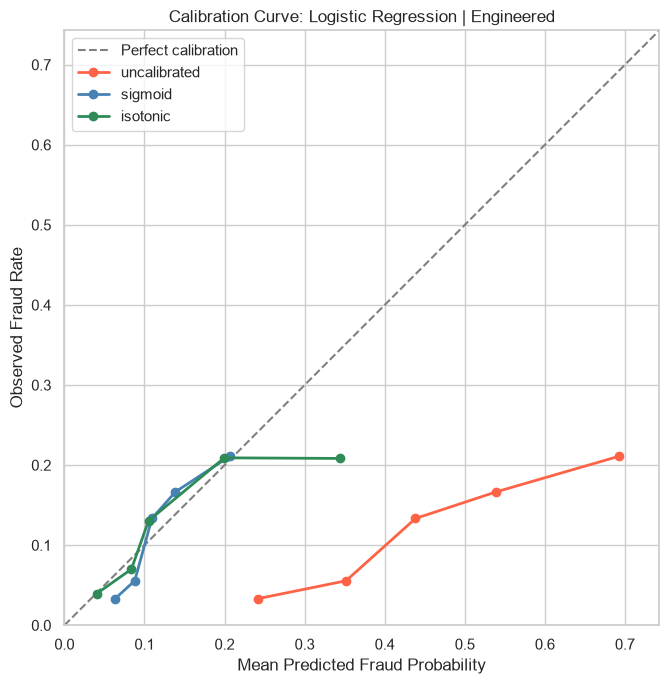

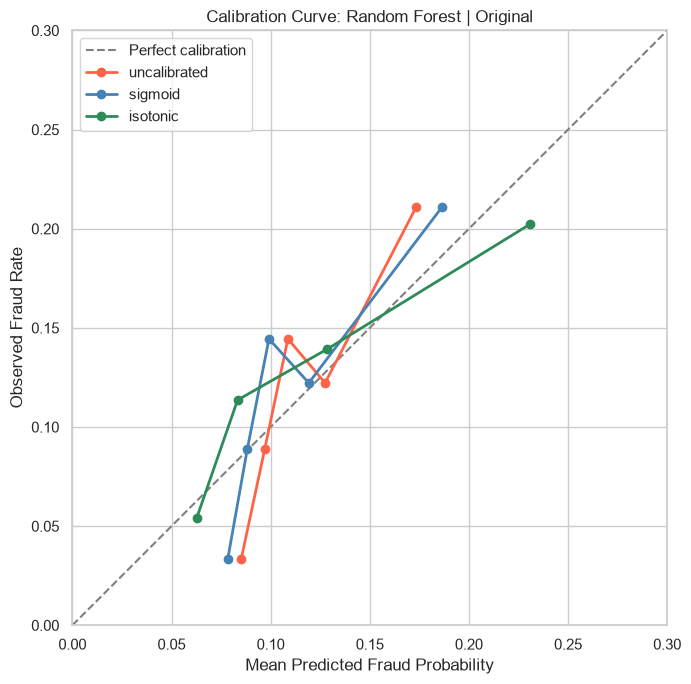

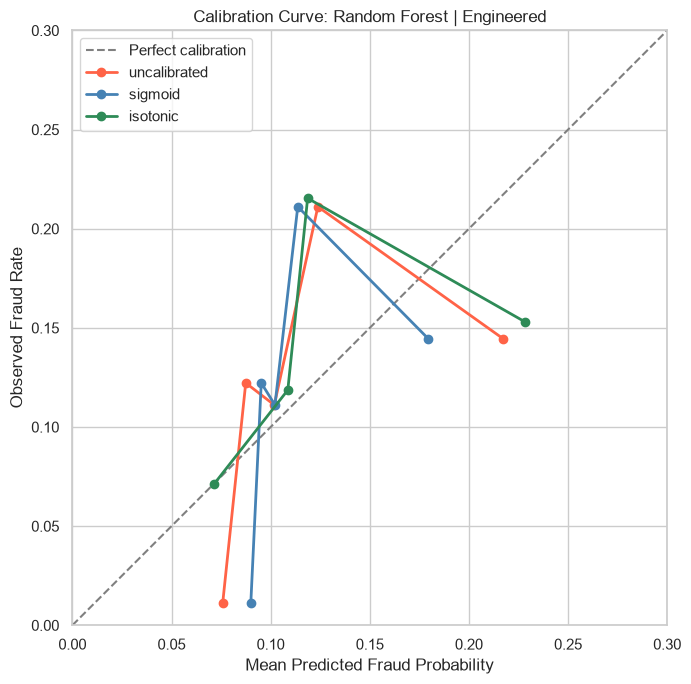

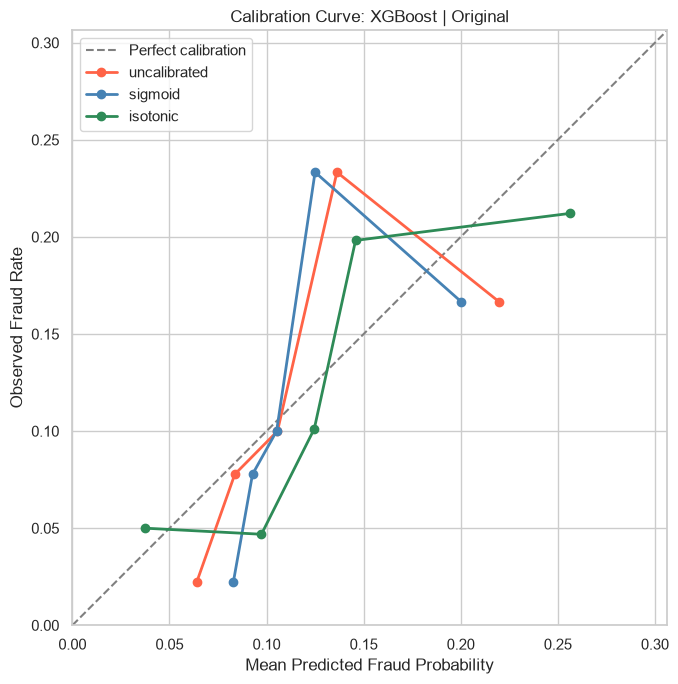

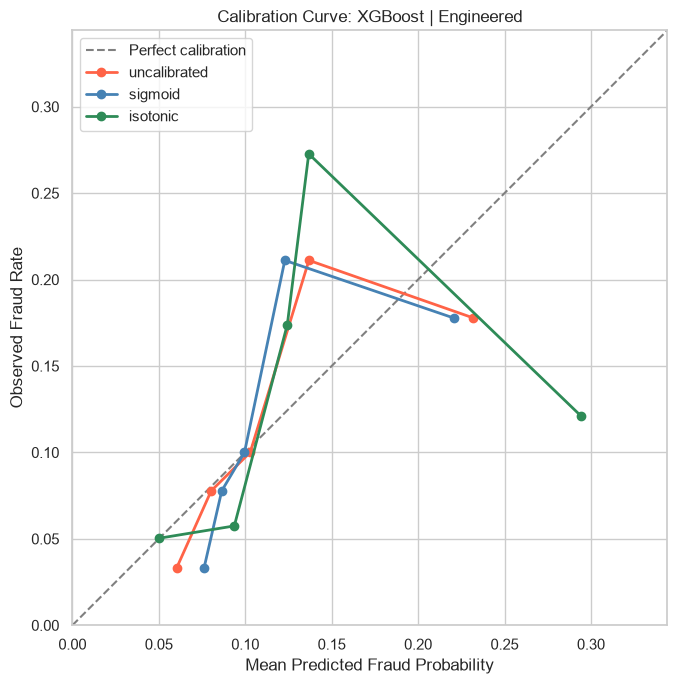

In [78]:
for candidate, probabilities in (
    calibration_probabilities.items()
):

    file_name = (
        candidate.lower()
        .replace(" | ", "_")
        .replace(" ", "_")
    )

    plot_calibration_curves(
        y_true=y_threshold,
        probability_sets=probabilities,
        title=f"Calibration Curve: {candidate}",
        save_path=FIGURES_DIR / (
            f"calibration_curve_{file_name}.png"
        ),
        n_bins=5
    )

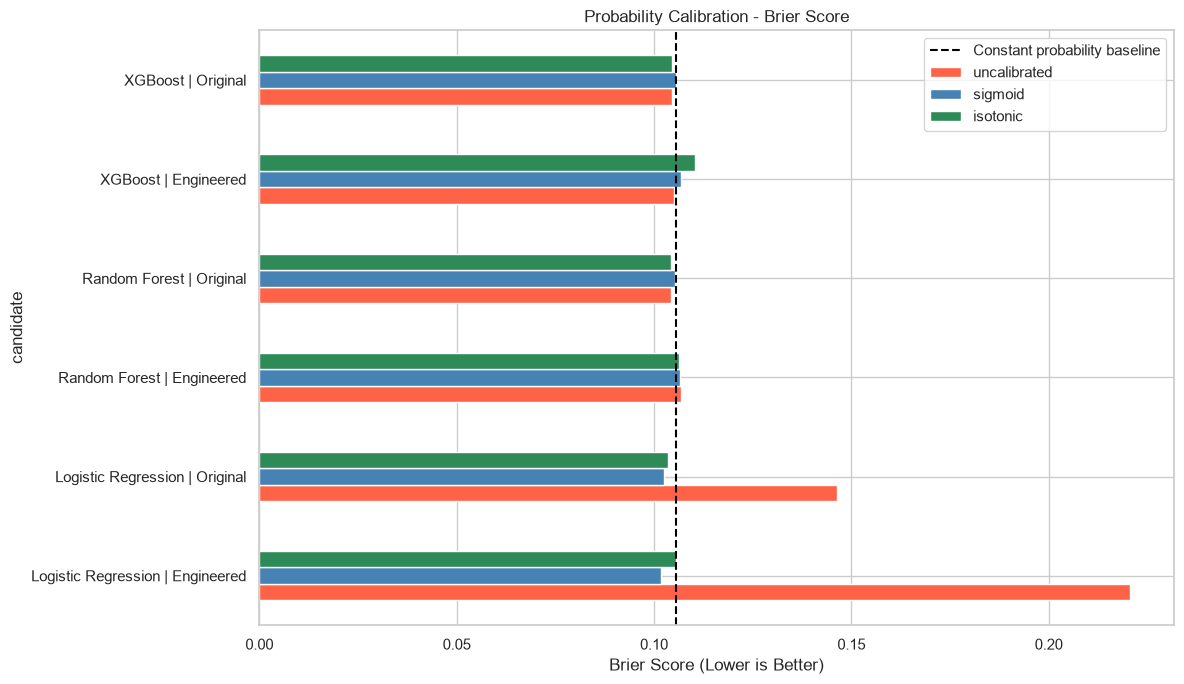

In [79]:
ax = brier_comparison.plot(
    kind="barh",
    figsize=(12, 7),
    color=[
        "tomato",
        "steelblue",
        "seagreen"
    ]
)

ax.axvline(
    baseline_calibration_metrics["brier"],
    color="black",
    linestyle="--",
    label="Constant probability baseline"
)

ax.set_title(
    "Probability Calibration - Brier Score"
)

ax.set_xlabel(
    "Brier Score (Lower is Better)"
)

ax.legend()

plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "calibration_brier_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

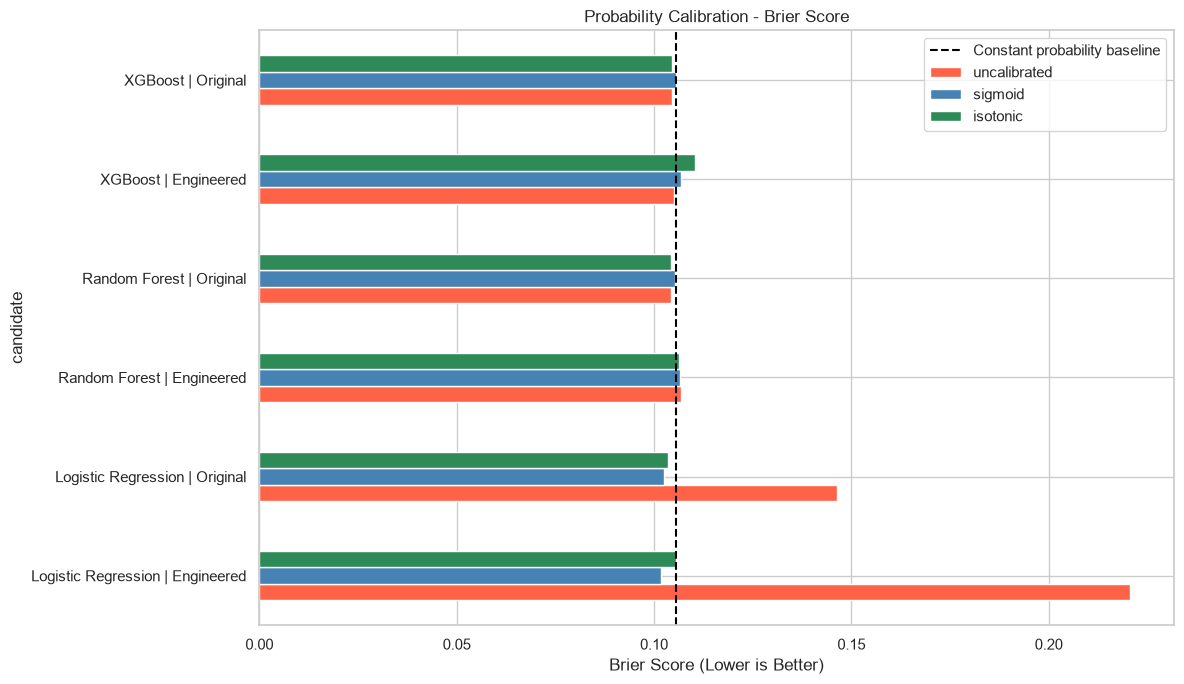

In [80]:
ax = brier_comparison.plot(
    kind="barh",
    figsize=(12, 7),
    color=[
        "tomato",
        "steelblue",
        "seagreen"
    ]
)

ax.axvline(
    baseline_calibration_metrics["brier"],
    color="black",
    linestyle="--",
    label="Constant probability baseline"
)

ax.set_title(
    "Probability Calibration - Brier Score"
)

ax.set_xlabel(
    "Brier Score (Lower is Better)"
)

ax.legend()

plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "calibration_brier_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

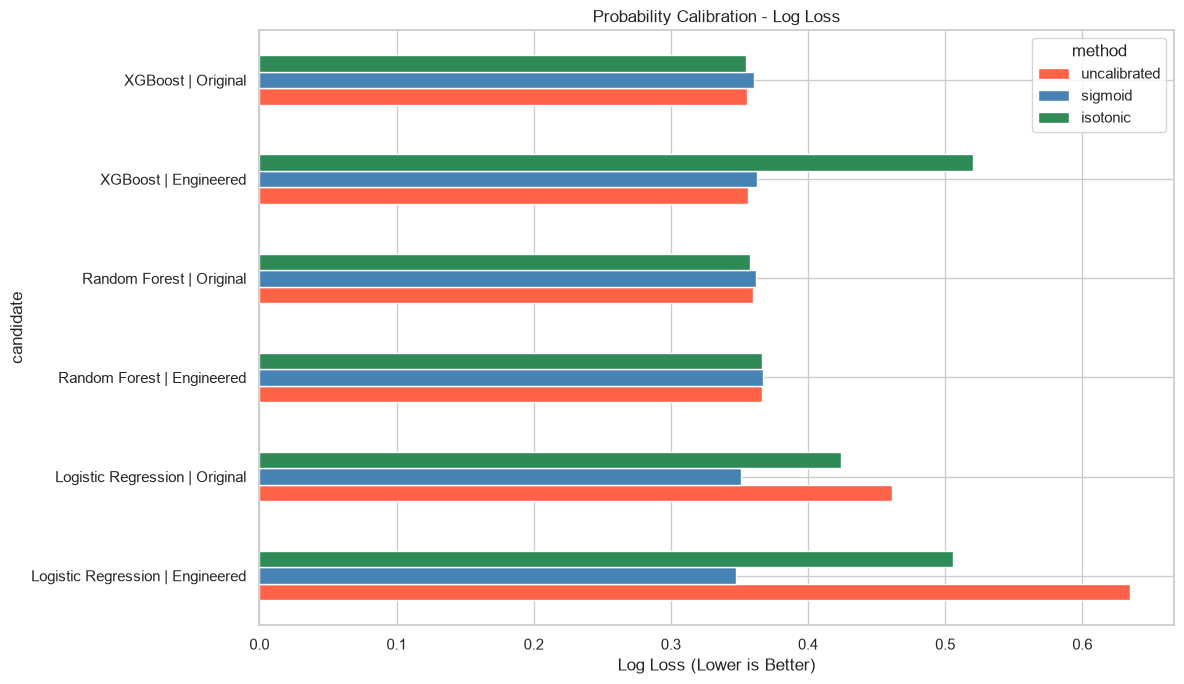

In [81]:
ax = log_loss_comparison.plot(
    kind="barh",
    figsize=(12, 7),
    color=[
        "tomato",
        "steelblue",
        "seagreen"
    ]
)

ax.set_title(
    "Probability Calibration - Log Loss"
)

ax.set_xlabel(
    "Log Loss (Lower is Better)"
)

plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "calibration_log_loss_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [82]:
analysis_candidate = (
    "Logistic Regression | Engineered"
)

probability_summary = (
    calibration_results.loc[
        calibration_results["candidate"]
        == analysis_candidate,
        [
            "method",
            "mean_probability",
            "observed_fraud_rate",
            "min_probability",
            "max_probability",
            "brier",
            "pr_auc",
            "roc_auc"
        ]
    ]
)

display(probability_summary)

,method,mean_probability,observed_fraud_rate,min_probability,max_probability,brier,pr_auc,roc_auc
0,sigmoid,0.1212,0.1200,0.0280,0.4593,0.1019,0.2141,0.6877
10,isotonic,0.1217,0.1200,0.0395,1.0000,0.1056,0.1867,0.6766
17,uncalibrated,0.4529,0.1200,0.0812,0.9349,0.2207,0.2141,0.6877


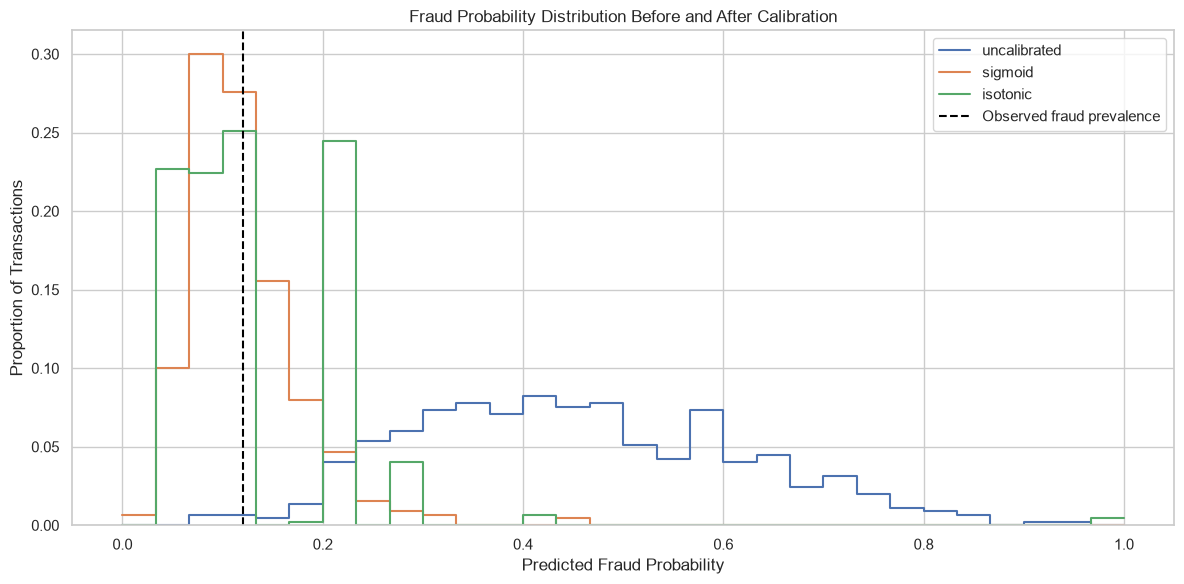

In [83]:
probability_plot_df = pd.DataFrame(
    calibration_probabilities[
        analysis_candidate
    ]
)

fig, ax = plt.subplots(
    figsize=(12, 6)
)

for method in probability_plot_df.columns:

    sns.histplot(
        probability_plot_df[method],
        bins=np.linspace(0, 1, 31),
        stat="probability",
        element="step",
        fill=False,
        label=method,
        ax=ax
    )

ax.axvline(
    y_threshold.mean(),
    color="black",
    linestyle="--",
    label="Observed fraud prevalence"
)

ax.set_title(
    "Fraud Probability Distribution Before and After Calibration"
)

ax.set_xlabel(
    "Predicted Fraud Probability"
)

ax.set_ylabel(
    "Proportion of Transactions"
)

ax.legend()

plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "calibration_probability_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [84]:
calibrated_only_results = (
    calibration_results.loc[
        calibration_results["method"].isin(
            ["sigmoid", "isotonic"]
        )
    ].copy()
)

selected_calibration = (
    calibrated_only_results.sort_values(
        ["brier", "log_loss"]
    )
    .drop_duplicates(
        subset="candidate",
        keep="first"
    )
    .reset_index(drop=True)
)

selected_calibrated_models = {}

for _, row in selected_calibration.iterrows():

    candidate = row["candidate"]
    method = row["method"]

    selected_calibrated_models[candidate] = (
        calibrated_candidates[candidate][method]
    )

assert len(selected_calibrated_models) == 6

display(
    selected_calibration[
        [
            "candidate",
            "method",
            "brier",
            "log_loss",
            "pr_auc",
            "roc_auc"
        ]
    ]
)

selected_calibration.to_csv(
    METRICS_DIR / "selected_calibration_methods.csv",
    index=False
)

,candidate,method,brier,log_loss,pr_auc,roc_auc
0,Logistic Regression | Engineered,sigmoid,0.1019,0.3478,0.2141,0.6877
1,Logistic Regression | Original,sigmoid,0.1024,0.3508,0.2091,0.6781
2,Random Forest | Original,isotonic,0.1042,0.3577,0.1710,0.6288
3,XGBoost | Original,isotonic,0.1045,0.3547,0.1817,0.6797
4,Random Forest | Engineered,isotonic,0.1064,0.3662,0.1533,0.6095
5,XGBoost | Engineered,sigmoid,0.1067,0.3630,0.1764,0.6658


In [85]:
calibrated_candidates_path = (
    MODELS_DIR / "calibrated_candidates.joblib"
)

selected_calibrated_models_path = (
    MODELS_DIR / "selected_calibrated_models.joblib"
)

joblib.dump(
    calibrated_candidates,
    calibrated_candidates_path
)

joblib.dump(
    selected_calibrated_models,
    selected_calibrated_models_path
)

print(
    "All calibrated candidates saved successfully."
)

print(
    "Selected calibrated models saved successfully."
)

All calibrated candidates saved successfully.
Selected calibrated models saved successfully.


In [86]:
loaded_calibrated_models = joblib.load(
    selected_calibrated_models_path
)

sample_X = X_threshold.iloc[:10]

for candidate in selected_calibrated_models:

    original_probabilities = (
        selected_calibrated_models[candidate]
        .predict_proba(sample_X)
    )

    loaded_probabilities = (
        loaded_calibrated_models[candidate]
        .predict_proba(sample_X)
    )

    np.testing.assert_allclose(
        original_probabilities,
        loaded_probabilities
    )

    assert np.allclose(
        loaded_probabilities.sum(axis=1),
        1
    )

    print(
        f"{candidate}: Serialization passed"
    )

print("\nAll serialization checks passed!")

Logistic Regression | Engineered: Serialization passed
Logistic Regression | Original: Serialization passed
Random Forest | Original: Serialization passed
XGBoost | Original: Serialization passed
Random Forest | Engineered: Serialization passed
XGBoost | Engineered: Serialization passed

All serialization checks passed!


## 8. Cost-Sensitive Learning and Threshold Optimization

Develop a financial cost framework for approving, reviewing
and blocking transactions.

Optimize decision thresholds using the threshold validation
dataset while considering fraud losses, false-positive costs,
manual review expenses and operational capacity constraints.

Compare alternative classification policies and investigate
sensitivity to different business cost assumptions.

Select a calibrated production candidate based on measured
operational business cost.

The final test dataset remains excluded from model selection
and threshold optimization.

In [87]:
from src.cost_analysis import (
    BASE_COSTS,
    SCENARIOS,
    ACTIONS,
    NO_ACTION_THRESHOLD,
    create_cost_matrix,
    decision_codes,
    policy_metrics,
    optimize_thresholds
)

from sklearn.metrics import (
    brier_score_loss,
    average_precision_score,
    roc_auc_score
)

import joblib
import json

MAX_REVIEW_RATE = 0.25
MAX_BLOCK_RATE = 0.05

candidate_models = joblib.load(
    MODELS_DIR / "candidate_models.joblib"
)

calibrated_candidates = joblib.load(
    MODELS_DIR / "calibrated_candidates.joblib"
)

cost_matrix = pd.DataFrame(
    create_cost_matrix(BASE_COSTS),
    index=ACTIONS,
    columns=["Legitimate", "Fraud"]
)

display(cost_matrix)

assert len(candidate_models) == 6

assert X_threshold.index.equals(
    y_threshold.index
)

assert np.allclose(
    cost_matrix.values,
    [[0, 100], [5, 15], [25, 2]]
)

,Legitimate,Fraud
Approve,0.0000,100.0000
Review,5.0000,15.0000
Block,25.0000,2.0000


In [88]:
cost_assumptions = pd.DataFrame(
    SCENARIOS
).T

display(cost_assumptions)

cost_assumptions.to_csv(
    METRICS_DIR / "business_cost_assumptions.csv"
)

,fraud_loss,review_fee,review_effectiveness,block_fee,customer_friction
Base,100.0000,5.0000,0.9000,2.0000,23.0000
Low fraud loss,60.0000,5.0000,0.9000,2.0000,23.0000
High fraud loss,200.0000,5.0000,0.9000,2.0000,23.0000
High customer friction,100.0000,5.0000,0.9000,2.0000,60.0000
Expensive review,100.0000,10.0000,0.9000,2.0000,23.0000
Lower review effectiveness,100.0000,5.0000,0.6500,2.0000,23.0000


In [89]:
operational_probabilities = {}

for candidate, pipeline in candidate_models.items():

    probability_models = {
        "uncalibrated": pipeline,
        **calibrated_candidates[candidate]
    }

    operational_probabilities[candidate] = {}

    for method, model in probability_models.items():

        probabilities = model.predict_proba(
            X_threshold
        )[:, 1]

        assert len(probabilities) == len(y_threshold)

        assert np.isfinite(probabilities).all()

        operational_probabilities[candidate][method] = (
            probabilities
        )

print("Model candidates:", len(candidate_models))

print(
    "Probability configurations:",
    sum(
        len(methods)
        for methods in operational_probabilities.values()
    )
)

Model candidates: 6
Probability configurations: 18


In [90]:
threshold_cost_records = []

for candidate, methods in (
    operational_probabilities.items()
):

    print(f"\nEvaluating: {candidate}")

    for method, probabilities in methods.items():

        probability_metrics = {
            "brier": brier_score_loss(
                y_threshold, probabilities
            ),

            "pr_auc": average_precision_score(
                y_threshold, probabilities
            ),

            "roc_auc": roc_auc_score(
                y_threshold, probabilities
            )
        }

        for scenario, costs in SCENARIOS.items():

            policies = {
                "Default 0.50": policy_metrics(
                    y_threshold,
                    probabilities,
                    0.50,
                    0.50,
                    costs,
                    MAX_REVIEW_RATE,
                    MAX_BLOCK_RATE
                ),

                "Optimized binary": optimize_thresholds(
                    y_threshold,
                    probabilities,
                    costs,
                    MAX_REVIEW_RATE,
                    MAX_BLOCK_RATE,
                    binary_only=True
                ),

                "Optimized three-way": optimize_thresholds(
                    y_threshold,
                    probabilities,
                    costs,
                    MAX_REVIEW_RATE,
                    MAX_BLOCK_RATE
                ),

                "Approve all": policy_metrics(
                    y_threshold,
                    probabilities,
                    NO_ACTION_THRESHOLD,
                    NO_ACTION_THRESHOLD,
                    costs,
                    MAX_REVIEW_RATE,
                    MAX_BLOCK_RATE
                )
            }

            for policy, metrics in policies.items():

                threshold_cost_records.append({
                    "candidate": candidate,
                    "method": method,
                    "scenario": scenario,
                    "policy": policy,
                    **costs,
                    "max_review_rate": MAX_REVIEW_RATE,
                    "max_block_rate": MAX_BLOCK_RATE,
                    **probability_metrics,
                    **metrics
                })

threshold_cost_results = pd.DataFrame(
    threshold_cost_records
)

assert len(threshold_cost_results) == 432

threshold_cost_results.to_csv(
    METRICS_DIR / "05_threshold_cost_analysis.csv",
    index=False
)

display(threshold_cost_results.head())

print(
    "Total policy comparisons:",
    len(threshold_cost_results)
)


Evaluating: Logistic Regression | Original

Evaluating: Logistic Regression | Engineered

Evaluating: Random Forest | Original

Evaluating: Random Forest | Engineered

Evaluating: XGBoost | Original

Evaluating: XGBoost | Engineered


,candidate,method,scenario,policy,fraud_loss,review_fee,review_effectiveness,block_fee,customer_friction,max_review_rate,max_block_rate,brier,pr_auc,roc_auc,review_threshold,block_threshold,approve_count,review_count,block_count,fraud_approved,fraud_reviewed,fraud_blocked,legitimate_approved,legitimate_reviewed,legitimate_blocked,review_rate,block_rate,fraud_flag_rate,expected_fraud_prevented,expected_fraud_capture,legitimate_flag_rate,total_cost,cost_per_transaction,probability_expected_cost,approve_all_cost,cost_saving,saving_pct,capacity_feasible
0,Logistic Regression | Original,uncalibrated,Base,Default 0.50,100,5,0.9000,2,23,0.2500,0.0500,0.1464,0.2091,0.6781,0.5000,0.5000,389,0,61,40,0,14,349,0,47,0.0000,0.1356,0.2593,14.0000,0.2593,0.1187,5203.0000,11.5622,10464.0564,5400.0000,197.0000,3.6481,False
1,Logistic Regression | Original,uncalibrated,Base,Optimized binary,100,5,0.9000,2,23,0.2500,0.0500,0.1464,0.2091,0.6781,0.7600,0.7600,443,0,7,51,0,3,392,0,4,0.0000,0.0156,0.0556,3.0000,0.0556,0.0101,5206.0000,11.5689,13030.1418,5400.0000,194.0000,3.5926,True
2,Logistic Regression | Original,uncalibrated,Base,Optimized three-way,100,5,0.9000,2,23,0.2500,0.0500,0.1464,0.2091,0.6781,0.3950,0.7300,328,112,10,26,25,3,302,87,7,0.2489,0.0222,0.5185,25.5000,0.4722,0.2374,3591.0000,7.9800,8322.6628,5400.0000,1809.0000,33.5000,True
3,Logistic Regression | Original,uncalibrated,Base,Approve all,100,5,0.9000,2,23,0.2500,0.0500,0.1464,0.2091,0.6781,1.0100,1.0100,450,0,0,54,0,0,396,0,0,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,5400.0000,12.0000,13548.0497,5400.0000,0.0000,0.0000,True
4,Logistic Regression | Original,uncalibrated,Low fraud loss,Default 0.50,60,5,0.9000,2,23,0.2500,0.0500,0.1464,0.2091,0.6781,0.5000,0.5000,389,0,61,40,0,14,349,0,47,0.0000,0.1356,0.2593,14.0000,0.2593,0.1187,3603.0000,8.0067,6543.6962,3240.0000,-363.0000,-11.2037,False


Total policy comparisons: 432


In [91]:
calibrated_policy_results = (
    threshold_cost_results.loc[
        (
            threshold_cost_results["policy"]
            == "Optimized three-way"
        )
        & (
            threshold_cost_results["method"]
            != "uncalibrated"
        )
        & threshold_cost_results["capacity_feasible"]
    ].copy()
)

base_ranking = calibrated_policy_results.loc[
    calibrated_policy_results["scenario"] == "Base"
].sort_values([
    "total_cost",
    "legitimate_blocked",
    "brier",
    "candidate",
    "method"
]).reset_index(drop=True)

display(
    base_ranking[
        [
            "candidate",
            "method",
            "review_threshold",
            "block_threshold",
            "total_cost",
            "saving_pct",
            "review_rate",
            "expected_fraud_capture"
        ]
    ]
)

base_ranking.to_csv(
    METRICS_DIR / "operational_model_ranking.csv",
    index=False
)

,candidate,method,review_threshold,block_threshold,total_cost,saving_pct,review_rate,expected_fraud_capture
0,Logistic Regression | Original,sigmoid,0.1450,0.2650,3596.0000,33.4074,0.2444,0.4556
1,Logistic Regression | Engineered,sigmoid,0.1500,0.4550,3645.0000,32.5000,0.2489,0.4333
2,Random Forest | Original,sigmoid,0.1250,0.2850,3785.0000,29.9074,0.2489,0.4167
3,Random Forest | Original,isotonic,0.1400,1.0100,3860.0000,28.5185,0.2356,0.3833
4,XGBoost | Engineered,sigmoid,0.1300,0.3600,4015.0000,25.6481,0.2489,0.3833
5,XGBoost | Original,sigmoid,0.1350,1.0100,4030.0000,25.3704,0.2311,0.3500
6,Random Forest | Engineered,sigmoid,0.1150,0.2450,4315.0000,20.0926,0.2422,0.3667
7,Random Forest | Engineered,isotonic,0.2150,1.0100,4655.0000,13.7963,0.1889,0.2167
8,XGBoost | Original,isotonic,0.1600,1.0100,4775.0000,11.5741,0.1222,0.1667
9,XGBoost | Engineered,isotonic,0.1650,1.0100,4995.0000,7.5000,0.1400,0.1333


In [92]:
best_policy = base_ranking.iloc[0]

final_candidate_name = best_policy["candidate"]
final_calibration_method = best_policy["method"]

REVIEW_THRESHOLD = float(
    best_policy["review_threshold"]
)

BLOCK_THRESHOLD = float(
    best_policy["block_threshold"]
)

final_pipeline = candidate_models[
    final_candidate_name
]

final_calibrated_model = calibrated_candidates[
    final_candidate_name
][final_calibration_method]

final_threshold_probabilities = (
    final_calibrated_model.predict_proba(
        X_threshold
    )[:, 1]
)

print("Selected model:", final_candidate_name)

print(
    "Calibration method:",
    final_calibration_method
)

print("Review threshold:", REVIEW_THRESHOLD)

print("Block threshold:", BLOCK_THRESHOLD)

print(
    "Minimum validation cost:",
    best_policy["total_cost"]
)

Selected model: Logistic Regression | Original
Calibration method: sigmoid
Review threshold: 0.145
Block threshold: 0.265
Minimum validation cost: 3596.0


In [93]:
selected_policy_comparison = (
    threshold_cost_results.loc[
        (
            threshold_cost_results["candidate"]
            == final_candidate_name
        )
        & (
            threshold_cost_results["method"]
            == final_calibration_method
        )
        & (
            threshold_cost_results["scenario"]
            == "Base"
        )
    ].copy()
)

display(
    selected_policy_comparison[
        [
            "policy",
            "review_threshold",
            "block_threshold",
            "approve_count",
            "review_count",
            "block_count",
            "total_cost",
            "saving_pct",
            "capacity_feasible"
        ]
    ]
)

selected_policy_comparison.to_csv(
    METRICS_DIR / "selected_policy_comparison.csv",
    index=False
)

,policy,review_threshold,block_threshold,approve_count,review_count,block_count,total_cost,saving_pct,capacity_feasible
24,Default 0.50,0.5000,0.5000,450,0,0,5400.0000,0.0000,True
25,Optimized binary,0.2650,0.2650,443,0,7,5206.0000,3.5926,True
26,Optimized three-way,0.1450,0.2650,333,110,7,3596.0000,33.4074,True
27,Approve all,1.0100,1.0100,450,0,0,5400.0000,0.0000,True


In [94]:
selected_operational_metrics = policy_metrics(
    y_threshold,
    final_threshold_probabilities,
    REVIEW_THRESHOLD,
    BLOCK_THRESHOLD,
    BASE_COSTS,
    MAX_REVIEW_RATE,
    MAX_BLOCK_RATE
)

display(
    pd.Series(selected_operational_metrics)
)

decision_outcome_table = pd.DataFrame(
    {
        "Legitimate": [
            selected_operational_metrics[
                "legitimate_approved"
            ],
            selected_operational_metrics[
                "legitimate_reviewed"
            ],
            selected_operational_metrics[
                "legitimate_blocked"
            ]
        ],

        "Fraud": [
            selected_operational_metrics[
                "fraud_approved"
            ],
            selected_operational_metrics[
                "fraud_reviewed"
            ],
            selected_operational_metrics[
                "fraud_blocked"
            ]
        ]
    },
    index=ACTIONS
)

decision_cost_table = (
    decision_outcome_table * cost_matrix
)

display(decision_outcome_table)

display(decision_cost_table)

assert decision_outcome_table.values.sum() == len(
    y_threshold
)

assert np.isclose(
    decision_cost_table.values.sum(),
    selected_operational_metrics["total_cost"]
)

review_threshold               0.1450
block_threshold                0.2650
approve_count                     333
review_count                      110
block_count                         7
fraud_approved                     27
fraud_reviewed                     24
fraud_blocked                       3
legitimate_approved               306
legitimate_reviewed                86
legitimate_blocked                  4
review_rate                    0.2444
block_rate                     0.0156
fraud_flag_rate                0.5000
expected_fraud_prevented      24.6000
expected_fraud_capture         0.4556
legitimate_flag_rate           0.2273
total_cost                  3596.0000
cost_per_transaction           7.9911
probability_expected_cost   4158.1881
approve_all_cost            5400.0000
cost_saving                 1804.0000
saving_pct                    33.4074
capacity_feasible                True
dtype: object

,Legitimate,Fraud
Approve,306,27
Review,86,24
Block,4,3


,Legitimate,Fraud
Approve,0.0000,2700.0000
Review,430.0000,360.0000
Block,100.0000,6.0000


In [95]:
scenario_winners = (
    calibrated_policy_results.sort_values([
        "total_cost",
        "legitimate_blocked",
        "brier",
        "candidate",
        "method"
    ])
    .drop_duplicates("scenario")
    .set_index("scenario")
    .reindex(list(SCENARIOS))
    .reset_index()
)

display(
    scenario_winners[
        [
            "scenario",
            "candidate",
            "method",
            "review_threshold",
            "block_threshold",
            "total_cost",
            "saving_pct"
        ]
    ]
)

scenario_winners.to_csv(
    METRICS_DIR / "cost_scenario_winners.csv",
    index=False
)

,scenario,candidate,method,review_threshold,block_threshold,total_cost,saving_pct
0,Base,Logistic Regression | Original,sigmoid,0.1450,0.2650,3596.0000,33.4074
1,Low fraud loss,Logistic Regression | Original,sigmoid,0.1450,0.2650,2420.0000,25.3086
2,High fraud loss,Logistic Regression | Original,sigmoid,0.1450,0.2650,6536.0000,39.4815
3,High customer friction,Logistic Regression | Engineered,sigmoid,0.1500,0.4550,3682.0000,31.8148
4,Expensive review,Logistic Regression | Original,sigmoid,0.1450,0.2650,4146.0000,23.2222
5,Lower review effectiveness,Logistic Regression | Original,sigmoid,0.1450,0.2650,4196.0000,22.2963


In [96]:
fixed_policy_records = []

for scenario, costs in SCENARIOS.items():

    metrics = policy_metrics(
        y_threshold,
        final_threshold_probabilities,
        REVIEW_THRESHOLD,
        BLOCK_THRESHOLD,
        costs,
        MAX_REVIEW_RATE,
        MAX_BLOCK_RATE
    )

    winner = scenario_winners.loc[
        scenario_winners["scenario"] == scenario
    ].iloc[0]

    fixed_policy_records.append({
        "scenario": scenario,

        "fixed_policy_cost": metrics[
            "total_cost"
        ],

        "optimized_scenario_cost": winner[
            "total_cost"
        ],

        "additional_cost_fixed_policy": (
            metrics["total_cost"]
            - winner["total_cost"]
        )
    })

fixed_policy_sensitivity = pd.DataFrame(
    fixed_policy_records
)

display(fixed_policy_sensitivity)

fixed_policy_sensitivity.to_csv(
    METRICS_DIR / "fixed_policy_sensitivity.csv",
    index=False
)

,scenario,fixed_policy_cost,optimized_scenario_cost,additional_cost_fixed_policy
0,Base,3596.0000,3596.0000,0.0000
1,Low fraud loss,2420.0000,2420.0000,0.0000
2,High fraud loss,6536.0000,6536.0000,0.0000
3,High customer friction,3744.0000,3682.0000,62.0000
4,Expensive review,4146.0000,4146.0000,0.0000
5,Lower review effectiveness,4196.0000,4196.0000,0.0000


In [97]:
capacity_records = []

for review_capacity in [
    0.10, 0.15, 0.25, 0.40, 0.50
]:

    metrics = optimize_thresholds(
        y_threshold,
        final_threshold_probabilities,
        BASE_COSTS,
        max_review_rate=review_capacity,
        max_block_rate=MAX_BLOCK_RATE
    )

    capacity_records.append({
        "max_review_capacity": review_capacity,
        **metrics
    })

capacity_sensitivity = pd.DataFrame(
    capacity_records
)

display(
    capacity_sensitivity[
        [
            "max_review_capacity",
            "review_threshold",
            "block_threshold",
            "review_count",
            "block_count",
            "expected_fraud_capture",
            "total_cost"
        ]
    ]
)

capacity_sensitivity.to_csv(
    METRICS_DIR / "review_capacity_sensitivity.csv",
    index=False
)

,max_review_capacity,review_threshold,block_threshold,review_count,block_count,expected_fraud_capture,total_cost
0,0.1000,0.1650,0.2100,44,21,0.2741,4573.0000
1,0.1500,0.1650,1.0100,65,0,0.2667,4285.0000
2,0.2500,0.1450,0.2650,110,7,0.4556,3596.0000
3,0.4000,0.1250,0.3000,179,2,0.5852,3162.0000
4,0.5000,0.1100,0.2600,224,9,0.7222,2776.0000


In [98]:
review_grid = np.unique(
    np.r_[
        np.arange(201) / 200,
        REVIEW_THRESHOLD,
        BLOCK_THRESHOLD
    ]
)

review_grid = review_grid[
    review_grid <= BLOCK_THRESHOLD
]

review_sweep = pd.DataFrame([
    policy_metrics(
        y_threshold,
        final_threshold_probabilities,
        threshold,
        BLOCK_THRESHOLD,
        BASE_COSTS,
        MAX_REVIEW_RATE,
        MAX_BLOCK_RATE
    )
    for threshold in review_grid
])

display(review_sweep)

review_sweep.to_csv(
    METRICS_DIR / "review_threshold_sweep.csv",
    index=False
)

,review_threshold,block_threshold,approve_count,review_count,block_count,fraud_approved,fraud_reviewed,fraud_blocked,legitimate_approved,legitimate_reviewed,legitimate_blocked,review_rate,block_rate,fraud_flag_rate,expected_fraud_prevented,expected_fraud_capture,legitimate_flag_rate,total_cost,cost_per_transaction,probability_expected_cost,approve_all_cost,cost_saving,saving_pct,capacity_feasible
0,0.0000,0.2650,0,443,7,0,51,3,0,392,4,0.9844,0.0156,1.0000,48.9000,0.9056,1.0000,2831.0000,6.2911,2864.8600,5400.0000,2569.0000,47.5741,False
1,0.0050,0.2650,0,443,7,0,51,3,0,392,4,0.9844,0.0156,1.0000,48.9000,0.9056,1.0000,2831.0000,6.2911,2864.8600,5400.0000,2569.0000,47.5741,False
2,0.0100,0.2650,0,443,7,0,51,3,0,392,4,0.9844,0.0156,1.0000,48.9000,0.9056,1.0000,2831.0000,6.2911,2864.8600,5400.0000,2569.0000,47.5741,False
3,0.0150,0.2650,0,443,7,0,51,3,0,392,4,0.9844,0.0156,1.0000,48.9000,0.9056,1.0000,2831.0000,6.2911,2864.8600,5400.0000,2569.0000,47.5741,False
4,0.0200,0.2650,0,443,7,0,51,3,0,392,4,0.9844,0.0156,1.0000,48.9000,0.9056,1.0000,2831.0000,6.2911,2864.8600,5400.0000,2569.0000,47.5741,False
5,0.0250,0.2650,1,442,7,0,51,3,1,391,4,0.9822,0.0156,1.0000,48.9000,0.9056,0.9975,2826.0000,6.2800,2862.0240,5400.0000,2574.0000,47.6667,False
6,0.0300,0.2650,1,442,7,0,51,3,1,391,4,0.9822,0.0156,1.0000,48.9000,0.9056,0.9975,2826.0000,6.2800,2862.0240,5400.0000,2574.0000,47.6667,False
7,0.0350,0.2650,1,442,7,0,51,3,1,391,4,0.9822,0.0156,1.0000,48.9000,0.9056,0.9975,2826.0000,6.2800,2862.0240,5400.0000,2574.0000,47.6667,False
8,0.0400,0.2650,4,439,7,0,51,3,4,388,4,0.9756,0.0156,1.0000,48.9000,0.9056,0.9899,2811.0000,6.2467,2857.2898,5400.0000,2589.0000,47.9444,False
9,0.0450,0.2650,7,436,7,0,51,3,7,385,4,0.9689,0.0156,1.0000,48.9000,0.9056,0.9823,2796.0000,6.2133,2854.0767,5400.0000,2604.0000,48.2222,False


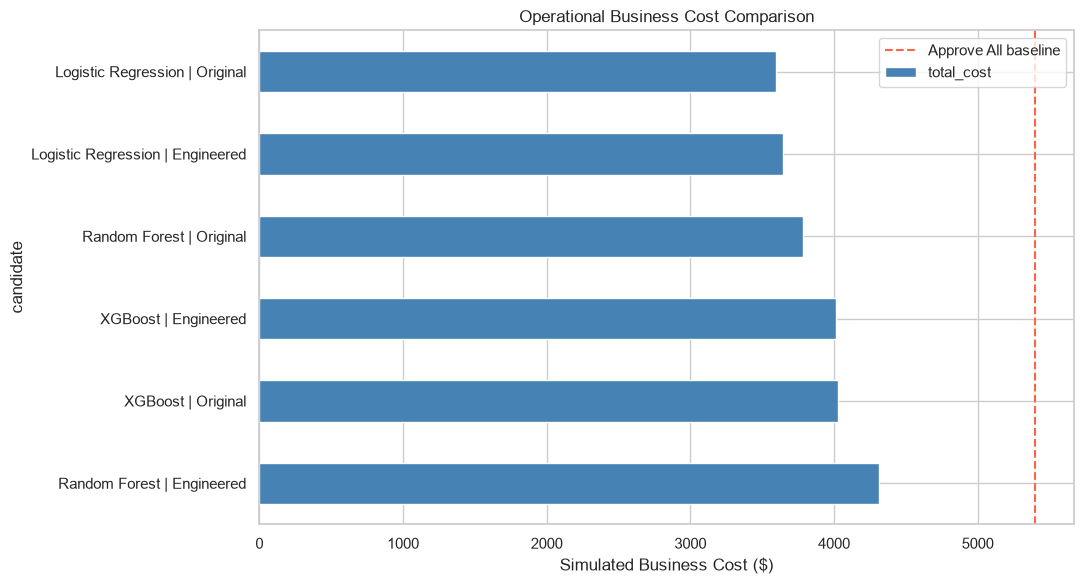

In [99]:
best_cost_by_candidate = (
    base_ranking
    .drop_duplicates("candidate")
    .sort_values("total_cost")
)

ax = best_cost_by_candidate.set_index(
    "candidate"
)["total_cost"].plot(
    kind="barh",
    figsize=(11, 6),
    color="steelblue"
)

ax.axvline(
    best_policy["approve_all_cost"],
    color="tomato",
    linestyle="--",
    label="Approve All baseline"
)

ax.set_title("Operational Business Cost Comparison")
ax.set_xlabel("Simulated Business Cost ($)")
ax.invert_yaxis()
ax.legend()

plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "operational_model_cost.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

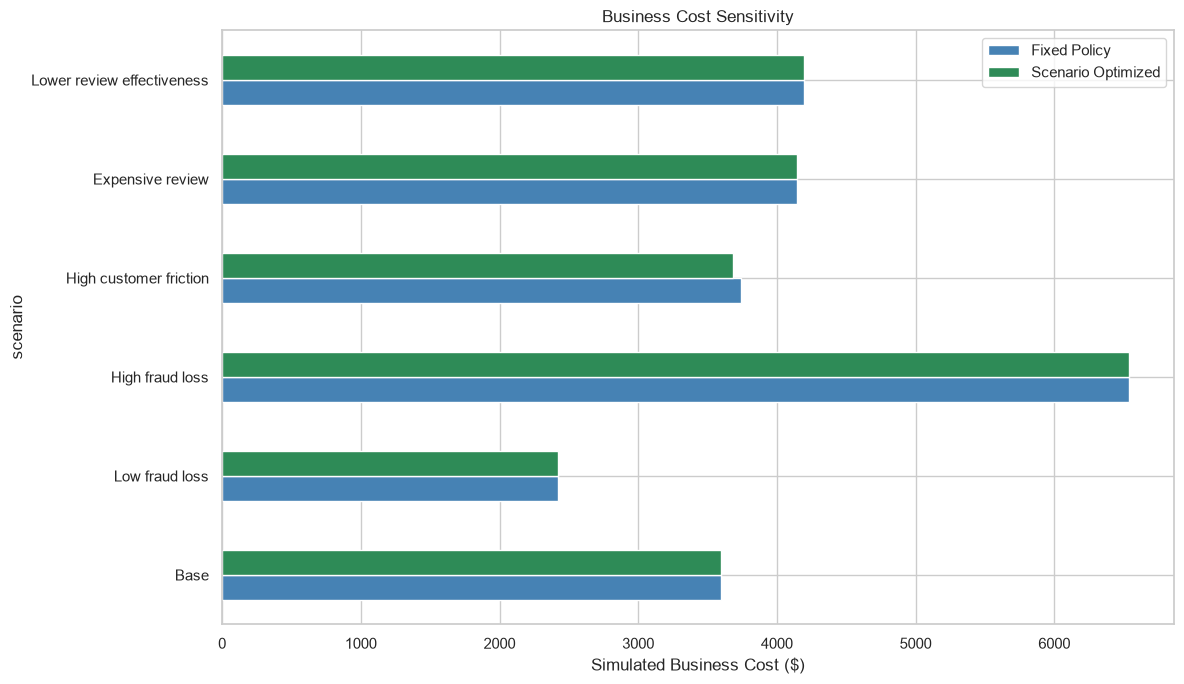

In [100]:
ax = fixed_policy_sensitivity.set_index(
    "scenario"
)[
    [
        "fixed_policy_cost",
        "optimized_scenario_cost"
    ]
].plot(
    kind="barh",
    figsize=(12, 7),
    color=["steelblue", "seagreen"]
)

ax.set_title("Business Cost Sensitivity")
ax.set_xlabel("Simulated Business Cost ($)")
ax.legend(["Fixed Policy", "Scenario Optimized"])

plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "financial_cost_sensitivity.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

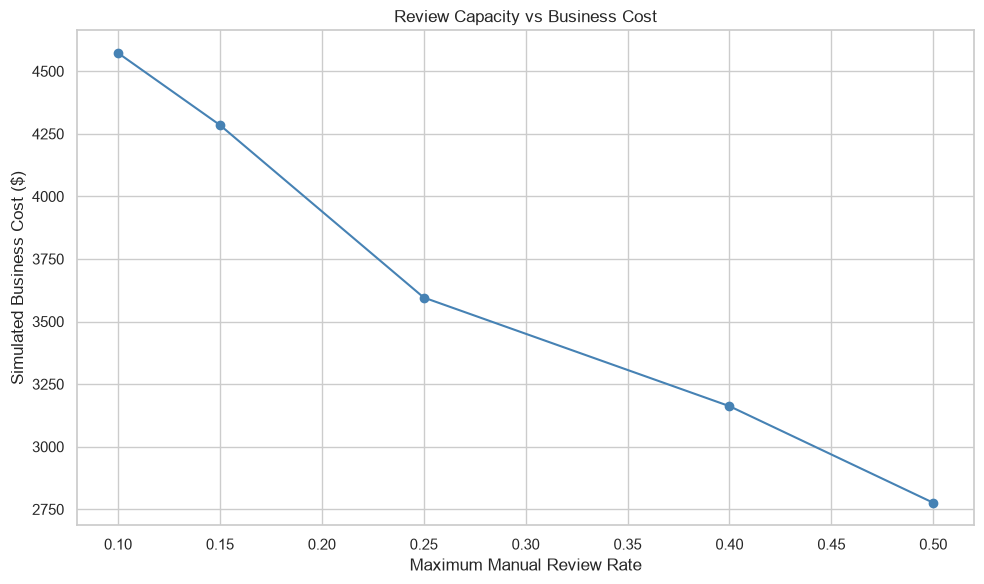

In [101]:
ax = capacity_sensitivity.plot(
    x="max_review_capacity",
    y="total_cost",
    marker="o",
    figsize=(10, 6),
    color="steelblue",
    legend=False
)

ax.set_title("Review Capacity vs Business Cost")
ax.set_xlabel("Maximum Manual Review Rate")
ax.set_ylabel("Simulated Business Cost ($)")

plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "review_capacity_sensitivity.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

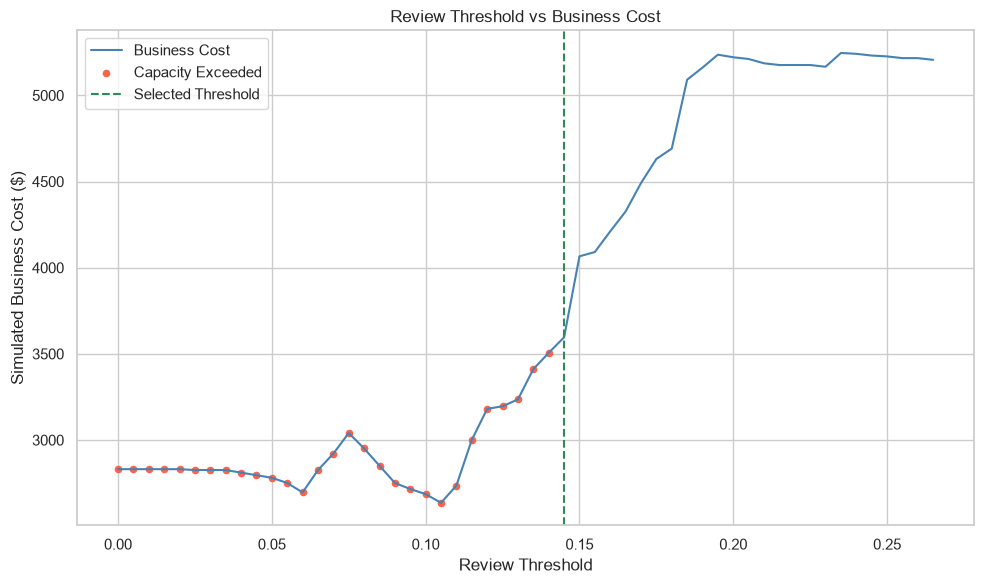

In [102]:
fig, ax = plt.subplots(figsize=(10, 6))

ax.plot(
    review_sweep["review_threshold"],
    review_sweep["total_cost"],
    label="Business Cost",
    color="steelblue"
)

infeasible = review_sweep.loc[
    ~review_sweep["capacity_feasible"]
]

ax.scatter(
    infeasible["review_threshold"],
    infeasible["total_cost"],
    color="tomato",
    s=20,
    label="Capacity Exceeded"
)

ax.axvline(
    REVIEW_THRESHOLD,
    color="seagreen",
    linestyle="--",
    label="Selected Threshold"
)

ax.set_title("Review Threshold vs Business Cost")
ax.set_xlabel("Review Threshold")
ax.set_ylabel("Simulated Business Cost ($)")
ax.legend()

fig.tight_layout()

fig.savefig(
    FIGURES_DIR / "threshold_cost_optimization.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [103]:
pipeline_path = (
    MODELS_DIR / "03_fraud_model_pipeline.joblib"
)

calibrated_model_path = (
    MODELS_DIR / "04_calibrated_model.joblib"
)

joblib.dump(
    final_pipeline,
    pipeline_path
)

joblib.dump(
    final_calibrated_model,
    calibrated_model_path
)

print("Original model pipeline saved.")

print("Calibrated production candidate saved.")

Original model pipeline saved.
Calibrated production candidate saved.


In [104]:
production_policy = {
    "model": str(final_candidate_name),

    "calibration_method": str(
        final_calibration_method
    ),

    "review_threshold": REVIEW_THRESHOLD,

    "block_threshold": BLOCK_THRESHOLD,

    "max_review_rate": MAX_REVIEW_RATE,

    "max_block_rate": MAX_BLOCK_RATE,

    "cost_assumptions": BASE_COSTS,

    "feature_columns": list(feature_columns),

    "random_state": RANDOM_STATE,

    "selection_dataset": "Threshold Validation",

    "status": "Pending final test evaluation"
}

policy_path = (
    MODELS_DIR / "decision_policy.json"
)

with open(
    policy_path,
    "w",
    encoding="utf-8"
) as file:

    json.dump(
        production_policy,
        file,
        indent=4
    )

print("Decision policy configuration saved.")

print(
    json.dumps(
        production_policy,
        indent=4
    )
)

Decision policy configuration saved.
{
    "model": "Logistic Regression | Original",
    "calibration_method": "sigmoid",
    "review_threshold": 0.145,
    "block_threshold": 0.265,
    "max_review_rate": 0.25,
    "max_block_rate": 0.05,
    "cost_assumptions": {
        "fraud_loss": 100,
        "review_fee": 5,
        "review_effectiveness": 0.9,
        "block_fee": 2,
        "customer_friction": 23
    },
    "feature_columns": [
        "hour",
        "day_of_week",
        "transaction_amount",
        "distance_from_usual_location_km",
        "transactions_last_1h",
        "transactions_last_24h",
        "account_age_days",
        "failed_logins_24h",
        "prior_chargebacks",
        "device_age_days",
        "merchant_risk_score",
        "ip_risk_score",
        "email_age_days",
        "login_to_transaction_minutes",
        "card_presence",
        "channel",
        "country",
        "device_type",
        "merchant_category",
        "authentication_level

In [105]:
loaded_pipeline = joblib.load(
    pipeline_path
)

loaded_calibrated_model = joblib.load(
    calibrated_model_path
)

sample_X = X_threshold.iloc[:10]

np.testing.assert_allclose(
    final_pipeline.predict_proba(sample_X),
    loaded_pipeline.predict_proba(sample_X)
)

np.testing.assert_allclose(
    final_calibrated_model.predict_proba(sample_X),
    loaded_calibrated_model.predict_proba(sample_X)
)

print(
    "Both production candidate artifacts "
    "passed serialization checks."
)

Both production candidate artifacts passed serialization checks.


## 9. Fraud Operations Simulation

Implement a reusable fraud decision engine using the selected
calibrated model and optimized operational thresholds.

Simulate transaction approval, manual review and automatic
blocking decisions.

Evaluate fraud capture, legitimate-customer disruption,
manual-review workload and expected financial impact.

Compare the selected policy against simpler operational policies.

All simulations use the threshold validation dataset.
The final test dataset remains reserved for final evaluation.

In [106]:
from src.decision_engine import (
    FraudDecisionEngine,
    DECISION_NAMES
)

from src.cost_analysis import policy_metrics

decision_engine = FraudDecisionEngine.load(
    MODELS_DIR
)

print("Fraud decision engine loaded successfully.")

print(
    "Model:",
    decision_engine.policy["model"]
)

print(
    "Calibration:",
    decision_engine.policy["calibration_method"]
)

print(
    "Review threshold:",
    decision_engine.review_threshold
)

print(
    "Block threshold:",
    decision_engine.block_threshold
)

Fraud decision engine loaded successfully.
Model: Logistic Regression | Original
Calibration: sigmoid
Review threshold: 0.145
Block threshold: 0.265


In [107]:
incoming_transactions = threshold_df[
    [ID_COLUMN] + feature_columns
].copy()

scored_transactions = (
    decision_engine.score_transactions(
        incoming_transactions
    )
)

display(scored_transactions.head(10))

assert len(scored_transactions) == len(
    incoming_transactions
)

np.testing.assert_allclose(
    scored_transactions["fraud_probability"],
    final_threshold_probabilities
)

assert TARGET not in scored_transactions.columns

scored_transactions.to_csv(
    METRICS_DIR / "fraud_decisions.csv",
    index=False
)

print("Transactions scored:", len(scored_transactions))

,transaction_id,fraud_probability,decision,decision_reason,expected_cost,missing_feature_count
1356,TXN5001357,0.0350,Approve,Below review threshold,3.5035,1
1960,TXN5001961,0.0628,Approve,Below review threshold,6.2808,2
2271,TXN5002272,0.1446,Approve,Below review threshold,14.4606,0
1662,TXN5001663,0.0826,Approve,Below review threshold,8.2630,0
284,TXN5000285,0.0766,Approve,Below review threshold,7.6557,1
2087,TXN5002088,0.0732,Approve,Below review threshold,7.3200,0
1823,TXN5001824,0.2287,Manual Review,Between review and block thresholds,7.2874,1
2405,TXN5002406,0.1816,Manual Review,Between review and block thresholds,6.8158,0
2629,TXN5002630,0.0813,Approve,Below review threshold,8.1345,0
1874,TXN5001875,0.0946,Approve,Below review threshold,9.4607,0


Transactions scored: 450


In [108]:
decision_distribution = (
    scored_transactions["decision"]
    .value_counts()
    .reindex(
        DECISION_NAMES,
        fill_value=0
    )
    .rename("transactions")
    .to_frame()
)

decision_distribution["percentage"] = (
    decision_distribution["transactions"]
    / len(scored_transactions) * 100
)

display(decision_distribution)

decision_distribution.to_csv(
    METRICS_DIR / "operational_decision_distribution.csv"
)

capacity_report = decision_engine.capacity_status(
    scored_transactions
)

display(pd.Series(capacity_report))

,transactions,percentage
decision,,
Approve,333,74.0000
Manual Review,110,24.4444
Block,7,1.5556


transactions                  450
review_rate                0.2444
block_rate                 0.0156
review_capacity_exceeded    False
block_capacity_exceeded     False
dtype: object

In [109]:
simulation_df = scored_transactions.merge(
    threshold_df[
        [
            ID_COLUMN,
            TARGET,
            "channel",
            "customer_tier"
        ]
    ],
    on=ID_COLUMN,
    how="left",
    validate="one_to_one"
)

assert len(simulation_df) == len(threshold_df)

assert simulation_df[TARGET].notna().all()

operational_outcomes = pd.crosstab(
    simulation_df["decision"],
    simulation_df[TARGET]
).reindex(
    index=DECISION_NAMES,
    columns=[0, 1],
    fill_value=0
)

operational_outcomes.columns = [
    "Legitimate", "Fraud"
]

display(operational_outcomes)

operational_outcomes.to_csv(
    METRICS_DIR / "operational_outcomes.csv"
)

,Legitimate,Fraud
decision,,
Approve,306,27
Manual Review,86,24
Block,4,3


In [110]:
operation_metrics = policy_metrics(
    simulation_df[TARGET],
    simulation_df["fraud_probability"],
    decision_engine.review_threshold,
    decision_engine.block_threshold,
    decision_engine.policy["cost_assumptions"],
    decision_engine.policy["max_review_rate"],
    decision_engine.policy["max_block_rate"]
)

reviewed = simulation_df[
    simulation_df["decision"] == "Manual Review"
]

blocked = simulation_df[
    simulation_df["decision"] == "Block"
]

flagged = simulation_df[
    simulation_df["decision"] != "Approve"
]

legitimate_count = (
    simulation_df[TARGET] == 0
).sum()

operation_metrics.update({

    "review_precision": (
        reviewed[TARGET].mean()
        if len(reviewed) else np.nan
    ),

    "block_precision": (
        blocked[TARGET].mean()
        if len(blocked) else np.nan
    ),

    "flagged_precision": (
        flagged[TARGET].mean()
        if len(flagged) else np.nan
    ),

    "legitimate_block_rate": (
        operation_metrics["legitimate_blocked"]
        / legitimate_count
    ),

    "expected_remaining_fraud": (
        simulation_df[TARGET].sum()
        - operation_metrics["expected_fraud_prevented"]
    )
})

operational_summary = pd.DataFrame(
    [operation_metrics]
)

display(operational_summary.T)

operational_summary.to_csv(
    METRICS_DIR / "fraud_operations_summary.csv",
    index=False
)

,0
review_threshold,0.1450
block_threshold,0.2650
approve_count,333
review_count,110
block_count,7
fraud_approved,27
fraud_reviewed,24
fraud_blocked,3
legitimate_approved,306
legitimate_reviewed,86


In [111]:
manual_review_queue = (
    decision_engine.create_review_queue(
        scored_transactions
    )
)

display(manual_review_queue.head(10))

assert len(manual_review_queue) == (
    operation_metrics["review_count"]
)

assert manual_review_queue[
    "fraud_probability"
].is_monotonic_decreasing

assert TARGET not in manual_review_queue.columns

manual_review_queue.to_csv(
    METRICS_DIR / "manual_review_queue.csv",
    index=False
)

print(
    "Transactions awaiting manual review:",
    len(manual_review_queue)
)

,review_priority,transaction_id,fraud_probability,decision,decision_reason,expected_cost,missing_feature_count
0,1,TXN5000245,0.2624,Manual Review,Between review and block thresholds,7.6239,0
1,2,TXN5001874,0.2603,Manual Review,Between review and block thresholds,7.6031,1
2,3,TXN5000076,0.2536,Manual Review,Between review and block thresholds,7.5362,0
3,4,TXN5002190,0.2507,Manual Review,Between review and block thresholds,7.5068,0
4,5,TXN5002033,0.2451,Manual Review,Between review and block thresholds,7.4511,1
5,6,TXN5000093,0.2438,Manual Review,Between review and block thresholds,7.4375,0
6,7,TXN5002535,0.2425,Manual Review,Between review and block thresholds,7.4253,0
7,8,TXN5001321,0.2363,Manual Review,Between review and block thresholds,7.3627,1
8,9,TXN5001037,0.2339,Manual Review,Between review and block thresholds,7.3391,0
9,10,TXN5000001,0.2302,Manual Review,Between review and block thresholds,7.3020,0


Transactions awaiting manual review: 110


In [112]:
block_queue = scored_transactions.loc[
    scored_transactions["decision"] == "Block"
].sort_values(
    "fraud_probability",
    ascending=False
)

display(block_queue)

block_queue.to_csv(
    METRICS_DIR / "blocked_transactions.csv",
    index=False
)

print(
    "Transactions recommended for blocking:",
    len(block_queue)
)

,transaction_id,fraud_probability,decision,decision_reason,expected_cost,missing_feature_count
1408,TXN5001409,0.4585,Block,At or above block threshold,14.4539,0
2182,TXN5002183,0.3018,Block,At or above block threshold,18.0585,0
2118,TXN5002119,0.2974,Block,At or above block threshold,18.1609,1
2220,TXN5002221,0.2708,Block,At or above block threshold,18.7711,0
2080,TXN5002081,0.2685,Block,At or above block threshold,18.8253,0
1148,TXN5001149,0.2683,Block,At or above block threshold,18.8299,1
1512,TXN5001513,0.2667,Block,At or above block threshold,18.8657,0


Transactions recommended for blocking: 7


In [113]:
financial_impact = pd.DataFrame({
    "metric": [
        "Approve All Cost",
        "Selected Policy Cost",
        "Probability Expected Cost",
        "Net Cost Savings",
        "Cost Saving Percentage",
        "Cost Per Transaction"
    ],

    "value": [
        operation_metrics["approve_all_cost"],
        operation_metrics["total_cost"],
        operation_metrics["probability_expected_cost"],
        operation_metrics["cost_saving"],
        operation_metrics["saving_pct"],
        operation_metrics["cost_per_transaction"]
    ]
})

display(financial_impact)

financial_impact.to_csv(
    METRICS_DIR / "operational_financial_impact.csv",
    index=False
)

assert np.isclose(
    scored_transactions["expected_cost"].sum(),
    operation_metrics["probability_expected_cost"]
)

,metric,value
0,Approve All Cost,5400.0000
1,Selected Policy Cost,3596.0000
2,Probability Expected Cost,4158.1881
3,Net Cost Savings,1804.0000
4,Cost Saving Percentage,33.4074
5,Cost Per Transaction,7.9911


In [114]:
previous_policies = pd.read_csv(
    METRICS_DIR / "selected_policy_comparison.csv"
)

operations_comparison_records = []

for _, row in previous_policies.iterrows():

    metrics = policy_metrics(
        simulation_df[TARGET],
        simulation_df["fraud_probability"],
        float(row["review_threshold"]),
        float(row["block_threshold"]),
        decision_engine.policy["cost_assumptions"],
        decision_engine.policy["max_review_rate"],
        decision_engine.policy["max_block_rate"]
    )

    operations_comparison_records.append({
        "policy": row["policy"],
        **metrics
    })

operations_comparison = pd.DataFrame(
    operations_comparison_records
)

display(
    operations_comparison[
        [
            "policy",
            "review_count",
            "block_count",
            "expected_fraud_prevented",
            "legitimate_blocked",
            "total_cost",
            "saving_pct"
        ]
    ]
)

operations_comparison.to_csv(
    METRICS_DIR / "fraud_operations_policy_comparison.csv",
    index=False
)

,policy,review_count,block_count,expected_fraud_prevented,legitimate_blocked,total_cost,saving_pct
0,Default 0.50,0,0,0.0000,0,5400.0000,0.0000
1,Optimized binary,0,7,3.0000,4,5206.0000,3.5926
2,Optimized three-way,110,7,24.6000,4,3596.0000,33.4074
3,Approve all,0,0,0.0000,0,5400.0000,0.0000


In [115]:
def summarize_segment_operations(data, feature):

    records = []

    for group, subset in data.groupby(
        feature,
        dropna=False
    ):

        legitimate = subset[
            subset[TARGET] == 0
        ]

        fraudulent = subset[
            subset[TARGET] == 1
        ]

        reviews = (
            subset["decision"] == "Manual Review"
        ).sum()

        blocks = (
            subset["decision"] == "Block"
        ).sum()

        legitimate_flagged = (
            legitimate["decision"] != "Approve"
        ).sum()

        legitimate_blocked = (
            legitimate["decision"] == "Block"
        ).sum()

        fraud_flagged = (
            fraudulent["decision"] != "Approve"
        ).sum()

        records.append({
            "feature": feature,
            "group": group,

            "transactions": len(subset),

            "fraud_count": len(fraudulent),

            "review_count": reviews,

            "block_count": blocks,

            "review_rate": reviews / len(subset),

            "legitimate_flag_rate": (
                legitimate_flagged / len(legitimate)
                if len(legitimate) else np.nan
            ),

            "legitimate_block_rate": (
                legitimate_blocked / len(legitimate)
                if len(legitimate) else np.nan
            ),

            "fraud_flag_rate": (
                fraud_flagged / len(fraudulent)
                if len(fraudulent) else np.nan
            ),

            "low_fraud_support": len(fraudulent) < 10
        })

    return pd.DataFrame(records)


channel_operations = summarize_segment_operations(
    simulation_df,
    "channel"
)

tier_operations = summarize_segment_operations(
    simulation_df,
    "customer_tier"
)

display(channel_operations)
display(tier_operations)

segment_operations = pd.concat(
    [channel_operations, tier_operations],
    ignore_index=True
)

segment_operations.to_csv(
    METRICS_DIR / "operational_segment_analysis.csv",
    index=False
)

,feature,group,transactions,fraud_count,review_count,block_count,review_rate,legitimate_flag_rate,legitimate_block_rate,fraud_flag_rate,low_fraud_support
0,channel,ATM,41,2,9,0,0.2195,0.2308,0.0000,0.0000,True
1,channel,E-commerce,187,30,56,6,0.2995,0.2803,0.0191,0.6000,False
2,channel,Mobile App,90,11,25,1,0.2778,0.2658,0.0127,0.4545,False
3,channel,POS,132,11,20,0,0.1515,0.1322,0.0000,0.3636,False


,feature,group,transactions,fraud_count,review_count,block_count,review_rate,legitimate_flag_rate,legitimate_block_rate,fraud_flag_rate,low_fraud_support
0,customer_tier,Basic,181,24,57,5,0.3149,0.2866,0.0127,0.7083,False
1,customer_tier,Gold,92,8,15,0,0.1630,0.1548,0.0000,0.2500,True
2,customer_tier,Platinum,37,2,14,0,0.3784,0.3714,0.0000,0.5000,True
3,customer_tier,Silver,140,20,24,2,0.1714,0.1583,0.0167,0.3500,False


In [116]:
import math

REVIEW_MINUTES = 5
ANALYST_HOURS = 8
UTILIZATION = 0.80

reviews_per_analyst = (
    ANALYST_HOURS
    * 60
    * UTILIZATION
    / REVIEW_MINUTES
)

volume_records = []

for daily_volume in [1000, 10000, 50000]:

    scale_factor = (
        daily_volume / len(simulation_df)
    )

    estimated_reviews = (
        operation_metrics["review_count"]
        * scale_factor
    )

    volume_records.append({

        "daily_transactions": daily_volume,

        "estimated_approvals": (
            operation_metrics["approve_count"]
            * scale_factor
        ),

        "estimated_reviews": estimated_reviews,

        "estimated_blocks": (
            operation_metrics["block_count"]
            * scale_factor
        ),

        "expected_fraud_prevented": (
            operation_metrics["expected_fraud_prevented"]
            * scale_factor
        ),

        "estimated_daily_cost": (
            operation_metrics["total_cost"]
            * scale_factor
        ),

        "estimated_daily_savings": (
            operation_metrics["cost_saving"]
            * scale_factor
        ),

        "required_analysts": math.ceil(
            estimated_reviews / reviews_per_analyst
        )
    })

volume_simulation = pd.DataFrame(
    volume_records
)

display(volume_simulation)

volume_simulation.to_csv(
    METRICS_DIR / "transaction_volume_simulation.csv",
    index=False
)

,daily_transactions,estimated_approvals,estimated_reviews,estimated_blocks,expected_fraud_prevented,estimated_daily_cost,estimated_daily_savings,required_analysts
0,1000,740.0000,244.4444,15.5556,54.6667,7991.1111,4008.8889,4
1,10000,7400.0000,2444.4444,155.5556,546.6667,79911.1111,40088.8889,32
2,50000,37000.0000,12222.2222,777.7778,2733.3333,399555.5556,200444.4444,160


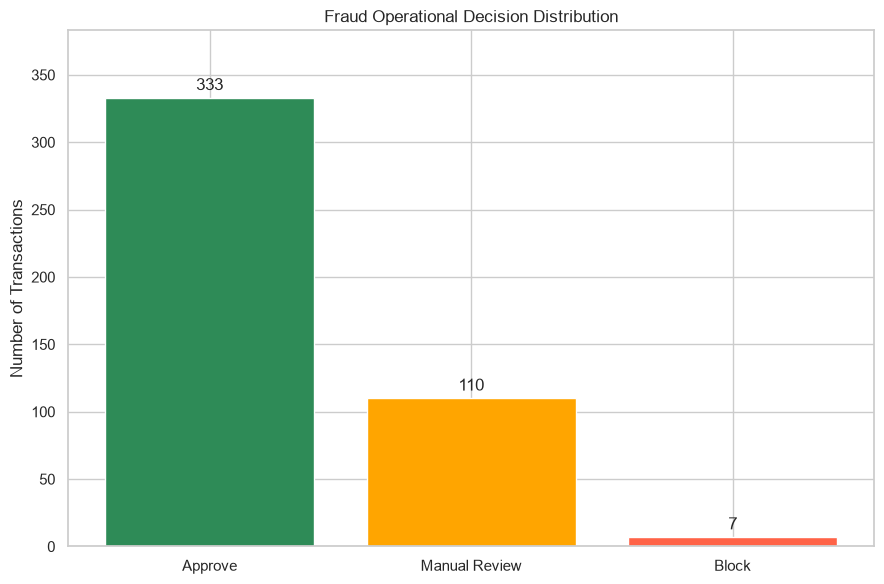

In [117]:
fig, ax = plt.subplots(figsize=(9, 6))

bars = ax.bar(
    decision_distribution.index,
    decision_distribution["transactions"],
    color=[
        "seagreen",
        "orange",
        "tomato"
    ]
)

ax.bar_label(bars, padding=3)

ax.set_title("Fraud Operational Decision Distribution")
ax.set_ylabel("Number of Transactions")

ax.set_ylim(
    0,
    decision_distribution["transactions"].max() * 1.15
)

plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "operational_decision_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

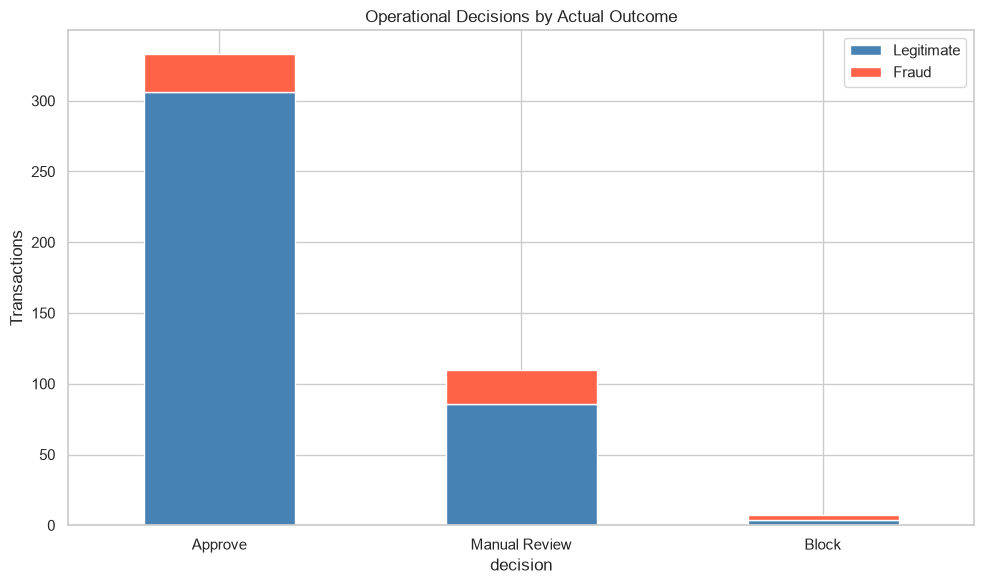

In [118]:
ax = operational_outcomes.plot(
    kind="bar",
    stacked=True,
    figsize=(10, 6),
    color=["steelblue", "tomato"]
)

ax.set_title("Operational Decisions by Actual Outcome")
ax.set_ylabel("Transactions")

plt.xticks(rotation=0)
plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "operational_decision_outcomes.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

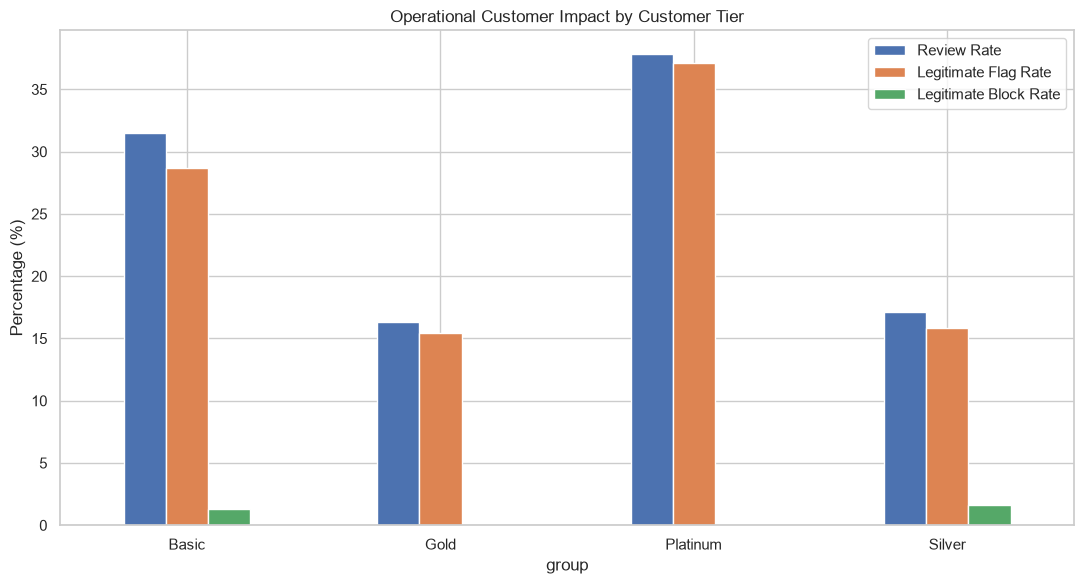

In [119]:
ax = tier_operations.set_index(
    "group"
)[
    [
        "review_rate",
        "legitimate_flag_rate",
        "legitimate_block_rate"
    ]
].mul(100).plot(
    kind="bar",
    figsize=(11, 6)
)

ax.set_title(
    "Operational Customer Impact by Customer Tier"
)

ax.set_ylabel("Percentage (%)")

plt.xticks(rotation=0)

plt.legend([
    "Review Rate",
    "Legitimate Flag Rate",
    "Legitimate Block Rate"
])

plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "operational_customer_impact.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

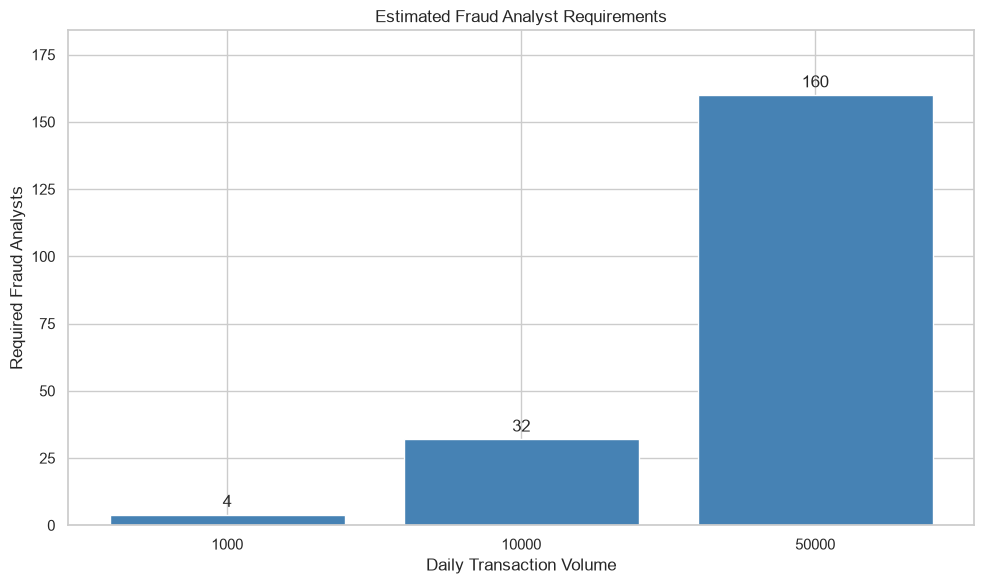

In [120]:
fig, ax = plt.subplots(figsize=(10, 6))

bars = ax.bar(
    volume_simulation[
        "daily_transactions"
    ].astype(str),

    volume_simulation[
        "required_analysts"
    ],

    color="steelblue"
)

ax.bar_label(bars, padding=3)

ax.set_title("Estimated Fraud Analyst Requirements")
ax.set_xlabel("Daily Transaction Volume")
ax.set_ylabel("Required Fraud Analysts")

ax.set_ylim(
    0,
    volume_simulation["required_analysts"].max() * 1.15
)

plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "operational_staffing_requirements.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [121]:
single_transaction = (
    incoming_transactions.iloc[[0]].copy()
)

single_result = (
    decision_engine.score_transactions(
        single_transaction
    )
)

display(single_result)

print(
    "Transaction ID:",
    single_result["transaction_id"].iloc[0]
)

print(
    "Fraud probability:",
    f"{single_result['fraud_probability'].iloc[0]:.2%}"
)

print(
    "Recommended decision:",
    single_result["decision"].iloc[0]
)

print(
    "Decision reason:",
    single_result["decision_reason"].iloc[0]
)

np.testing.assert_allclose(
    single_result["fraud_probability"].iloc[0],
    scored_transactions["fraud_probability"].iloc[0]
)

,transaction_id,fraud_probability,decision,decision_reason,expected_cost,missing_feature_count
1356,TXN5001357,0.0350,Approve,Below review threshold,3.5035,1


Transaction ID: TXN5001357
Fraud probability: 3.50%
Recommended decision: Approve
Decision reason: Below review threshold


## 10. Explainable AI

Implement SHAP-based explanations for the selected calibrated
fraud-risk model.

Investigate global feature importance, feature dependence,
feature interactions and individual transaction predictions.

Evaluate the stability of important predictors across
cross-validation folds and alternative SHAP reference samples.

Integrate explanations into the operational decision engine.

The final test dataset remains excluded from this analysis.
All explanations describe model behavior, not causal effects.

In [122]:
from src.explainability import (
    FraudSHAPExplainer,
    summarize_local_explanation,
    plot_local_explanation,
    pairwise_dependence
)

from src.decision_engine import FraudDecisionEngine

import shap
import joblib

decision_engine = FraudDecisionEngine.load(
    MODELS_DIR
)

final_pipeline = joblib.load(
    MODELS_DIR / "03_fraud_model_pipeline.joblib"
)

final_calibrated_model = decision_engine.model

fraud_explainer = FraudSHAPExplainer(
    model=final_calibrated_model,
    X_reference=X_train,
    background_size=24,
    random_state=RANDOM_STATE,
    permutations=3
)

print("SHAP version:", shap.__version__)

print(
    "Selected model:",
    decision_engine.policy["model"]
)

print(
    "Background transactions:",
    len(fraud_explainer.background)
)

print(
    "Original features:",
    len(fraud_explainer.columns)
)

SHAP version: 0.54.1
Selected model: Logistic Regression | Original
Background transactions: 24
Original features: 23


In [123]:
X_explain_global = X_threshold.sample(
    n=150,
    random_state=RANDOM_STATE
)

global_shap_values, global_baseline = (
    fraud_explainer.explain(
        X_explain_global
    )
)

global_probabilities = (
    final_calibrated_model.predict_proba(
        X_explain_global
    )[:, 1]
)

print(
    "SHAP matrix shape:",
    global_shap_values.shape
)

print(
    "Reference probability:",
    global_baseline.iloc[0]
)

reconstructed = (
    global_baseline
    + global_shap_values.sum(axis=1)
)

maximum_error = np.max(
    np.abs(
        reconstructed - global_probabilities
    )
)

print("Maximum reconstruction error:", maximum_error)

assert maximum_error < 1e-7

print("SHAP additivity check passed!")

SHAP matrix shape: (150, 23)
Reference probability: 0.1308866345544773
Maximum reconstruction error: 1.3877787807814457e-16
SHAP additivity check passed!


In [124]:
global_importance = pd.DataFrame({
    "feature": global_shap_values.columns,

    "mean_abs_shap": (
        global_shap_values.abs().mean().values
    ),

    "mean_signed_shap": (
        global_shap_values.mean().values
    )
})

global_importance = (
    global_importance.sort_values(
        "mean_abs_shap",
        ascending=False
    ).reset_index(drop=True)
)

global_importance["rank"] = (
    np.arange(1, len(global_importance) + 1)
)

global_importance["mean_abs_shap_pp"] = (
    global_importance["mean_abs_shap"] * 100
)

display(global_importance)

global_importance.to_csv(
    METRICS_DIR / "shap_global_importance.csv",
    index=False
)

,feature,mean_abs_shap,mean_signed_shap,rank,mean_abs_shap_pp
0,account_age_days,0.0165,-0.0013,1,1.6485
1,merchant_risk_score,0.0147,-0.0043,2,1.4665
2,channel,0.0122,0.0017,3,1.2165
3,merchant_category,0.0118,-0.0051,4,1.1751
4,transactions_last_1h,0.0112,-0.0006,5,1.1231
5,customer_tier,0.0106,-0.0038,6,1.0558
6,new_device,0.0091,-0.0020,7,0.9058
7,country,0.0089,-0.0036,8,0.8920
8,authentication_level,0.0081,-0.0024,9,0.8062
9,failed_logins_24h,0.0064,-0.0010,10,0.6394


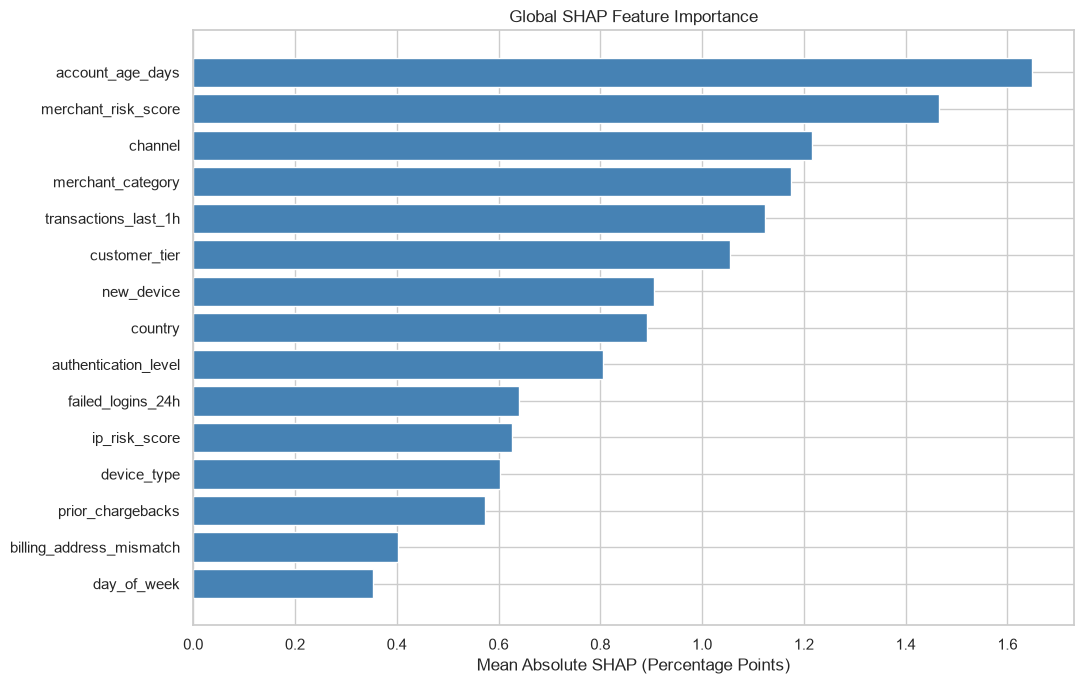

In [125]:
top_features = global_importance.head(15)

fig, ax = plt.subplots(figsize=(11, 7))

ax.barh(
    top_features["feature"],
    top_features["mean_abs_shap_pp"],
    color="steelblue"
)

ax.invert_yaxis()

ax.set_title(
    "Global SHAP Feature Importance"
)

ax.set_xlabel(
    "Mean Absolute SHAP (Percentage Points)"
)

plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "shap_global_importance.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

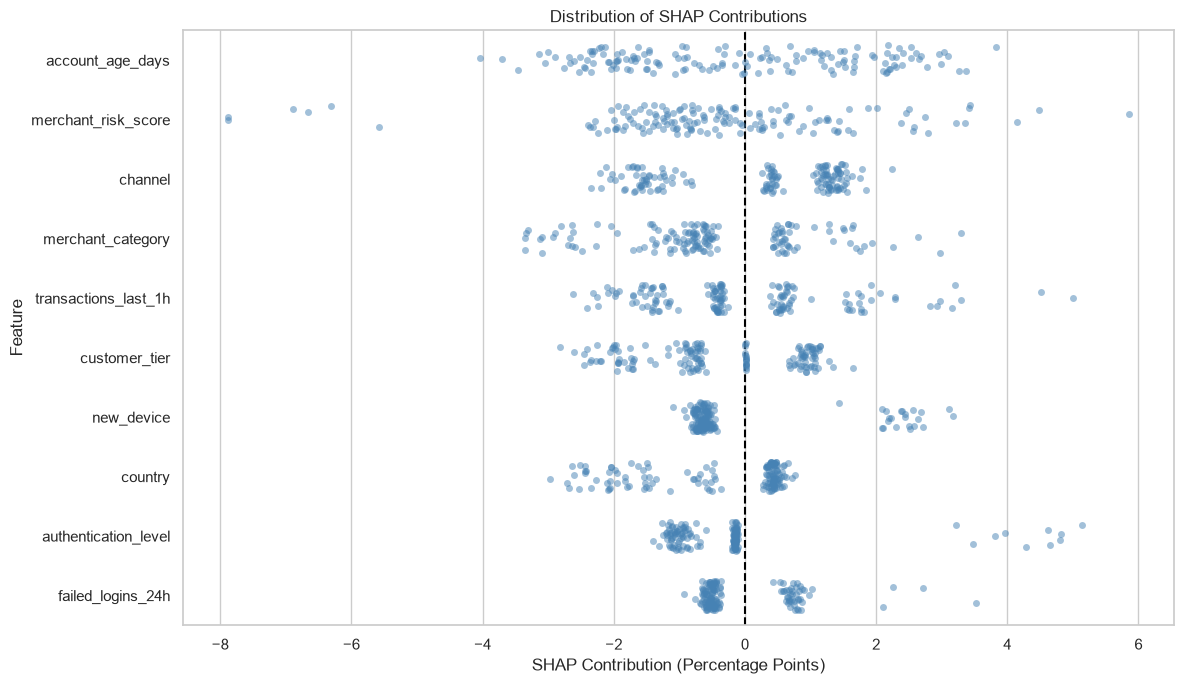

In [126]:
top_10_features = (
    global_importance.head(10)["feature"].tolist()
)

shap_plot_data = (
    global_shap_values[top_10_features]
    .mul(100)
    .melt(
        var_name="feature",
        value_name="shap_pp"
    )
)

plt.figure(figsize=(12, 7))

sns.stripplot(
    data=shap_plot_data,
    x="shap_pp",
    y="feature",
    order=top_10_features,
    alpha=0.5,
    jitter=0.25,
    color="steelblue"
)

plt.axvline(
    0,
    color="black",
    linestyle="--"
)

plt.title("Distribution of SHAP Contributions")

plt.xlabel(
    "SHAP Contribution (Percentage Points)"
)

plt.ylabel("Feature")

plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "shap_contribution_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### 10.1 Feature Dependence Analysis

Investigate how transaction feature values influence
their SHAP contributions to calibrated fraud probabilities.

Dependence plots describe the learned model behavior and
do not establish causal relationships.

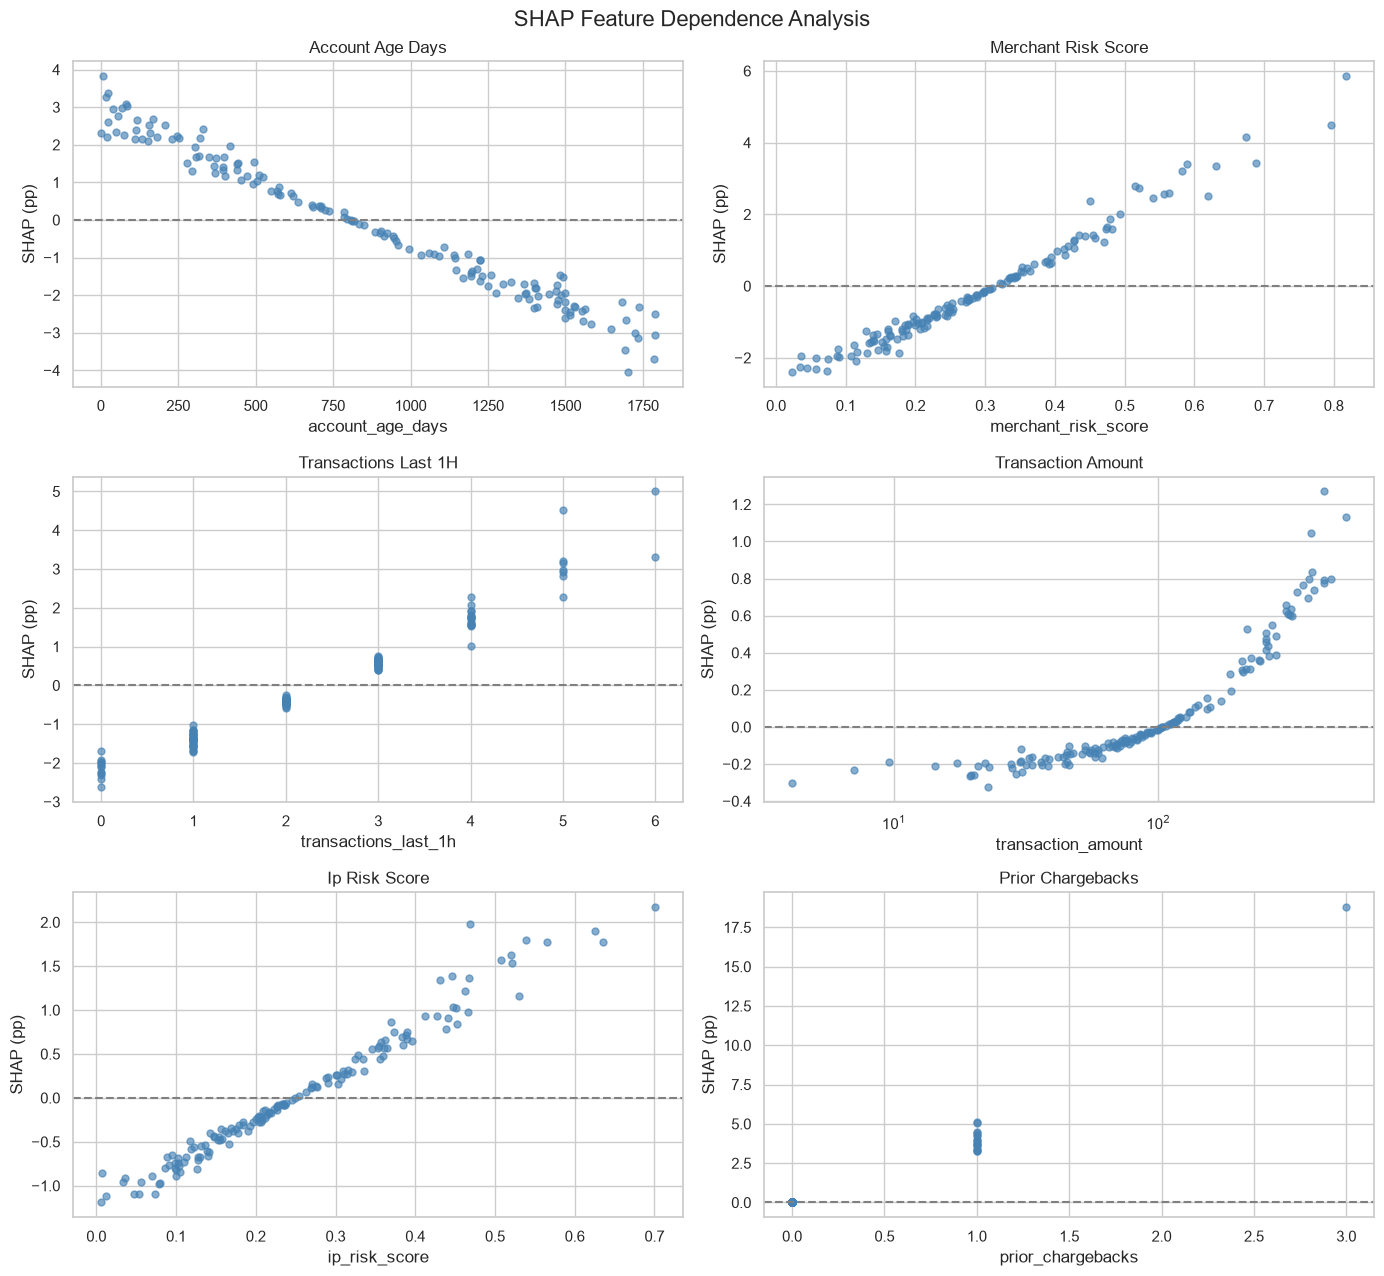

In [127]:
dependence_features = [
    "account_age_days",
    "merchant_risk_score",
    "transactions_last_1h",
    "transaction_amount",
    "ip_risk_score",
    "prior_chargebacks"
]

fig, axes = plt.subplots(
    3, 2,
    figsize=(14, 13)
)

for feature, ax in zip(
    dependence_features,
    axes.flatten()
):

    values = X_explain_global[feature]

    contributions = (
        global_shap_values[feature] * 100
    )

    valid = values.notna()

    ax.scatter(
        values[valid],
        contributions[valid],
        alpha=0.65,
        color="steelblue",
        s=25
    )

    ax.axhline(
        0,
        color="gray",
        linestyle="--"
    )

    ax.set_title(
        feature.replace("_", " ").title()
    )

    ax.set_xlabel(feature)

    ax.set_ylabel("SHAP (pp)")

    if feature == "transaction_amount":

        ax.set_xscale("log")

plt.suptitle(
    "SHAP Feature Dependence Analysis",
    fontsize=16
)

plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "shap_feature_dependence.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

,10,30,70,120
0,11.7402,11.6561,11.4894,11.2839
1,14.7560,14.6543,14.4525,14.2035


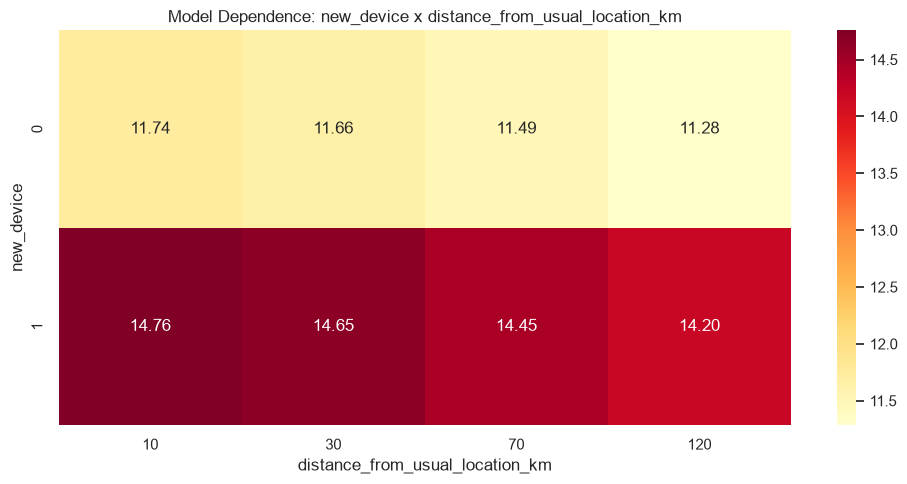

,0.1,0.3,0.6
50,10.2061,11.9451,15.0196
150,10.4431,12.2163,15.3473
500,11.3104,13.2069,16.5394


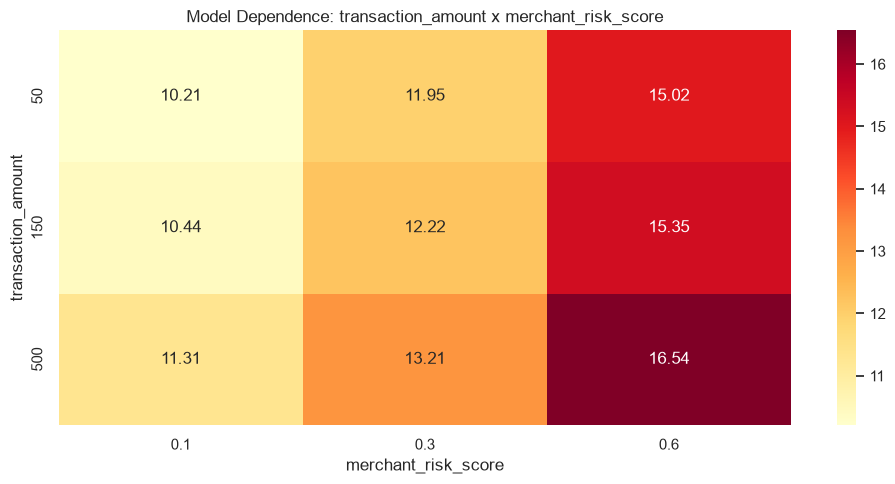

,ATM,POS,Mobile App,E-commerce
Standard,10.3236,9.7477,11.6902,12.5524
Strong,11.1000,10.4864,12.5532,13.4682
Missing,15.4328,14.6236,17.3313,18.5137


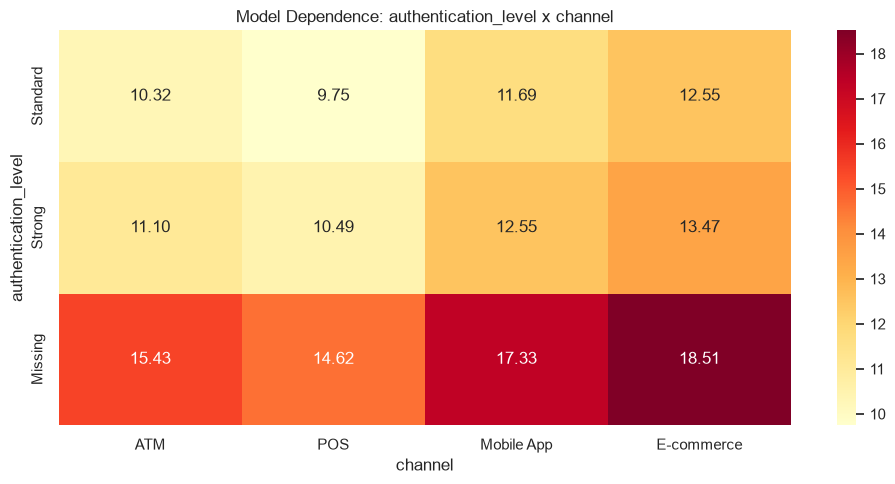

,interaction,maximum_absolute_interaction_pp,interaction_range_pp,predicted_risk_range_pp
2,authentication_channel,0.3455,0.6646,8.7661
1,amount_merchant_risk,0.1333,0.2468,6.3333
0,new_device_distance,0.0273,0.0546,3.4721


In [128]:
interaction_reference = X_train.sample(
    n=200,
    random_state=RANDOM_STATE
)

model_interaction_configs = [
    (
        "new_device_distance",
        "new_device",
        [0, 1],
        "distance_from_usual_location_km",
        [10, 30, 70, 120]
    ),

    (
        "amount_merchant_risk",
        "transaction_amount",
        [50, 150, 500],
        "merchant_risk_score",
        [0.1, 0.3, 0.6]
    ),

    (
        "authentication_channel",
        "authentication_level",
        ["Standard", "Strong", np.nan],
        "channel",
        ["ATM", "POS", "Mobile App", "E-commerce"]
    )
]

model_interaction_records = []

model_interaction_tables = {}

for config in model_interaction_configs:

    name, feature_a, values_a, feature_b, values_b = config

    dependence, interaction = pairwise_dependence(
        final_calibrated_model,
        interaction_reference,
        feature_a,
        values_a,
        feature_b,
        values_b
    )

    model_interaction_tables[name] = dependence

    model_interaction_records.append({

        "interaction": name,

        "maximum_absolute_interaction_pp": (
            interaction.abs().to_numpy().max() * 100
        ),

        "interaction_range_pp": (
            np.ptp(interaction.to_numpy()) * 100
        ),

        "predicted_risk_range_pp": (
            np.ptp(dependence.to_numpy()) * 100
        )
    })

    display(dependence * 100)

    dependence.to_csv(
        METRICS_DIR / f"model_dependence_{name}.csv"
    )

    interaction.to_csv(
        METRICS_DIR / f"model_interaction_{name}.csv"
    )

    plt.figure(figsize=(10, 5))

    sns.heatmap(
        dependence * 100,
        annot=True,
        fmt=".2f",
        cmap="YlOrRd"
    )

    plt.title(
        f"Model Dependence: {feature_a} x {feature_b}"
    )

    plt.xlabel(feature_b)
    plt.ylabel(feature_a)

    plt.tight_layout()

    plt.savefig(
        FIGURES_DIR / f"xai_interaction_{name}.png",
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()

model_interaction_summary = pd.DataFrame(
    model_interaction_records
).sort_values(
    "interaction_range_pp",
    ascending=False
)

display(model_interaction_summary)

model_interaction_summary.to_csv(
    METRICS_DIR / "model_interaction_summary.csv",
    index=False
)

In [129]:
from sklearn.inspection import permutation_importance
from sklearn.base import clone

importance_fold_records = []

for fold, (train_idx, val_idx) in enumerate(
    cv.split(X_train, y_train),
    start=1
):

    fold_model = clone(final_pipeline)

    fold_model.fit(
        X_train.iloc[train_idx],
        y_train.iloc[train_idx]
    )

    result = permutation_importance(
        fold_model,
        X_train.iloc[val_idx],
        y_train.iloc[val_idx],
        scoring="average_precision",
        n_repeats=5,
        random_state=RANDOM_STATE + fold - 1,
        n_jobs=1
    )

    for feature, importance in zip(
        X_train.columns,
        result.importances_mean
    ):

        importance_fold_records.append({
            "fold": fold,
            "feature": feature,
            "importance": importance
        })

    print(f"Fold {fold}: Completed")

importance_fold_results = pd.DataFrame(
    importance_fold_records
)

importance_fold_results.to_csv(
    METRICS_DIR / "feature_importance_cv_folds.csv",
    index=False
)

Fold 1: Completed
Fold 2: Completed
Fold 3: Completed
Fold 4: Completed
Fold 5: Completed


,mean_importance,std_importance,positive_folds,top_5_folds
feature,,,,
merchant_risk_score,0.0350,0.0199,5,4
prior_chargebacks,0.0261,0.0139,5,3
transactions_last_1h,0.0247,0.0172,5,3
authentication_level,0.0166,0.0136,5,2
channel,0.0145,0.0199,3,2
ip_risk_score,0.0142,0.0136,5,1
country,0.0135,0.0263,3,1
new_device,0.0128,0.0140,3,1
failed_logins_24h,0.0101,0.0149,4,1


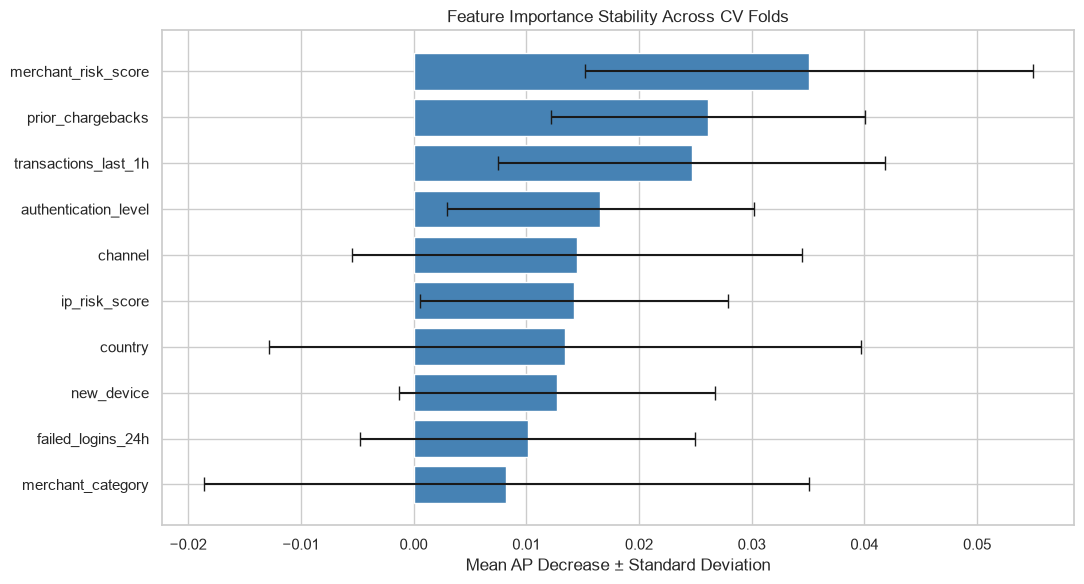

In [130]:
importance_matrix = importance_fold_results.pivot(
    index="fold",
    columns="feature",
    values="importance"
)

feature_stability = pd.DataFrame({

    "mean_importance": importance_matrix.mean(),

    "std_importance": importance_matrix.std(),

    "positive_folds": (
        importance_matrix > 0
    ).sum(),

    "top_5_folds": (
        importance_matrix.rank(
            axis=1,
            ascending=False,
            method="min"
        ) <= 5
    ).sum()

}).sort_values(
    "mean_importance",
    ascending=False
)

display(feature_stability)

feature_stability.to_csv(
    METRICS_DIR / "feature_importance_stability.csv"
)

top_stable = feature_stability.head(10)

fig, ax = plt.subplots(figsize=(11, 6))

ax.barh(
    top_stable.index,
    top_stable["mean_importance"],
    xerr=top_stable["std_importance"],
    color="steelblue",
    capsize=5
)

ax.invert_yaxis()

ax.set_title(
    "Feature Importance Stability Across CV Folds"
)

ax.set_xlabel(
    "Mean AP Decrease ± Standard Deviation"
)

plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "feature_importance_stability.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [131]:
alternative_explainer = FraudSHAPExplainer(
    final_calibrated_model,
    X_train,
    background_size=24,
    random_state=RANDOM_STATE + 1,
    permutations=3
)

alternative_shap, alternative_baseline = (
    alternative_explainer.explain(
        X_explain_global
    )
)

original_importance = (
    global_shap_values.abs().mean()
)

alternative_importance = (
    alternative_shap.abs().mean()
)

rank_correlation = original_importance.corr(
    alternative_importance,
    method="spearman"
)

original_top5 = set(
    original_importance.nlargest(5).index
)

alternative_top5 = set(
    alternative_importance.nlargest(5).index
)

top5_overlap = len(
    original_top5 & alternative_top5
)

shap_stability_report = pd.DataFrame({
    "original_importance": original_importance,
    "alternative_importance": alternative_importance
})

shap_stability_report["absolute_difference"] = (
    shap_stability_report["original_importance"]
    - shap_stability_report["alternative_importance"]
).abs()

display(shap_stability_report)

shap_stability_report.to_csv(
    METRICS_DIR / "shap_background_stability.csv"
)

print("Spearman rank correlation:", rank_correlation)
print("Top-five feature overlap:", top5_overlap)

print(
    "Original reference probability:",
    global_baseline.iloc[0]
)

print(
    "Alternative reference probability:",
    alternative_baseline.iloc[0]
)

,original_importance,alternative_importance,absolute_difference
hour,0.0002,0.0002,0.0000
day_of_week,0.0035,0.0033,0.0002
transaction_amount,0.0023,0.0024,0.0000
distance_from_usual_location_km,0.0013,0.0012,0.0000
transactions_last_1h,0.0112,0.0109,0.0003
transactions_last_24h,0.0007,0.0007,0.0000
account_age_days,0.0165,0.0160,0.0005
failed_logins_24h,0.0064,0.0053,0.0011
prior_chargebacks,0.0057,0.0102,0.0045
device_age_days,0.0015,0.0014,0.0001


Spearman rank correlation: 0.9673913043478262
Top-five feature overlap: 5
Original reference probability: 0.1308866345544773
Alternative reference probability: 0.11313732453333171


In [132]:
import importlib
import src.decision_engine as decision_module

importlib.reload(decision_module)

from src.decision_engine import FraudDecisionEngine

decision_engine = FraudDecisionEngine.load(
    MODELS_DIR
)

fraud_explainer = FraudSHAPExplainer(
    decision_engine.model,
    X_train,
    background_size=24,
    random_state=RANDOM_STATE,
    permutations=3
)

incoming_transactions = threshold_df[
    [ID_COLUMN] + feature_columns
].copy()

explained_transactions, high_risk_shap = (
    decision_engine.score_with_explanations(
        incoming_transactions,
        fraud_explainer
    )
)

high_risk_transactions = (
    explained_transactions.loc[
        explained_transactions["decision"] != "Approve"
    ].copy()
)

print(
    "Total scored transactions:",
    len(explained_transactions)
)

print(
    "High-risk transactions explained:",
    len(high_risk_transactions)
)

display(
    high_risk_transactions[
        [
            ID_COLUMN,
            "fraud_probability",
            "decision",
            "risk_increasing_factors",
            "risk_decreasing_factors"
        ]
    ].head()
)

assert len(high_risk_shap) == len(
    high_risk_transactions
)

assert high_risk_transactions[
    "shap_baseline"
].notna().all()

explained_transactions.to_csv(
    METRICS_DIR / "fraud_decisions_explained.csv",
    index=False
)

Total scored transactions: 450
High-risk transactions explained: 117


,transaction_id,fraud_probability,decision,risk_increasing_factors,risk_decreasing_factors
1823,TXN5001824,0.2287,Manual Review,authentication_level=Missing: +5.33 pp; transa...,country=USA: -3.40 pp; merchant_risk_score=0.1...
2405,TXN5002406,0.1816,Manual Review,merchant_risk_score=0.818: +5.86 pp; account_a...,customer_tier=Gold: -2.47 pp; transactions_las...
2308,TXN5002309,0.1779,Manual Review,authentication_level=Missing: +4.81 pp; new_de...,channel=POS: -2.19 pp; account_age_days=1.17e+...
328,TXN5000329,0.1715,Manual Review,merchant_risk_score=0.546: +2.63 pp; account_a...,transactions_last_1h=1: -1.69 pp; new_device=0...
2871,TXN5002872,0.1777,Manual Review,prior_chargebacks=1: +4.27 pp; merchant_catego...,authentication_level=Standard: -1.24 pp; merch...



Transaction Example 1
Probability: 45.85%
Decision: Block
Increasing factors: prior_chargebacks=3: +18.81 pp; transactions_last_1h=5: +4.60 pp; merchant_risk_score=0.45: +2.34 pp
Decreasing factors: new_device=0: -1.10 pp; merchant_category=Travel: -1.07 pp; failed_logins_24h=0: -0.91 pp


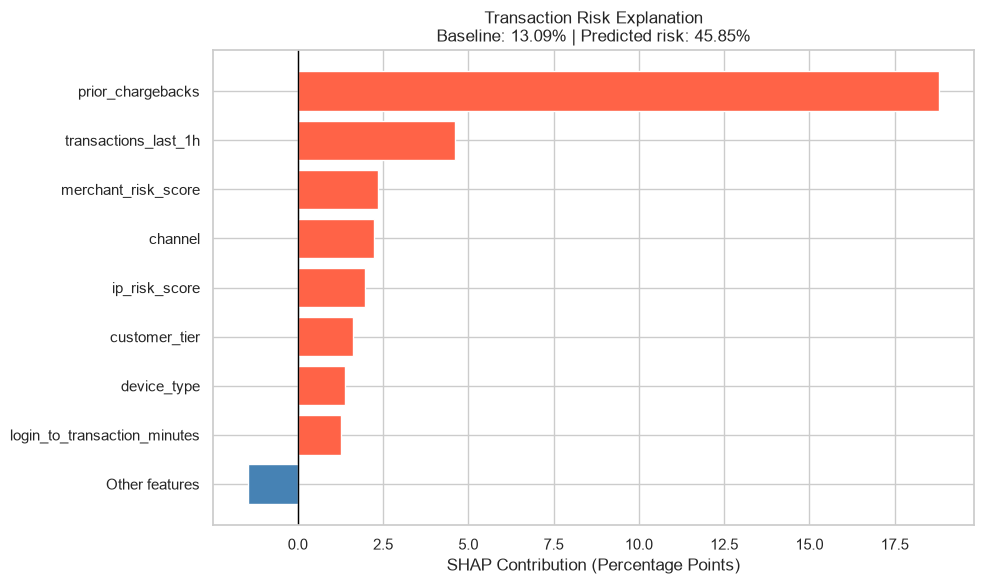


Transaction Example 2
Probability: 30.18%
Decision: Block
Increasing factors: prior_chargebacks=1: +5.34 pp; new_device=1: +3.35 pp; transactions_last_1h=4: +2.42 pp
Decreasing factors: account_age_days=1e+03: -1.01 pp; device_age_days=1.4e+03: -0.38 pp; billing_address_mismatch=0: -0.36 pp


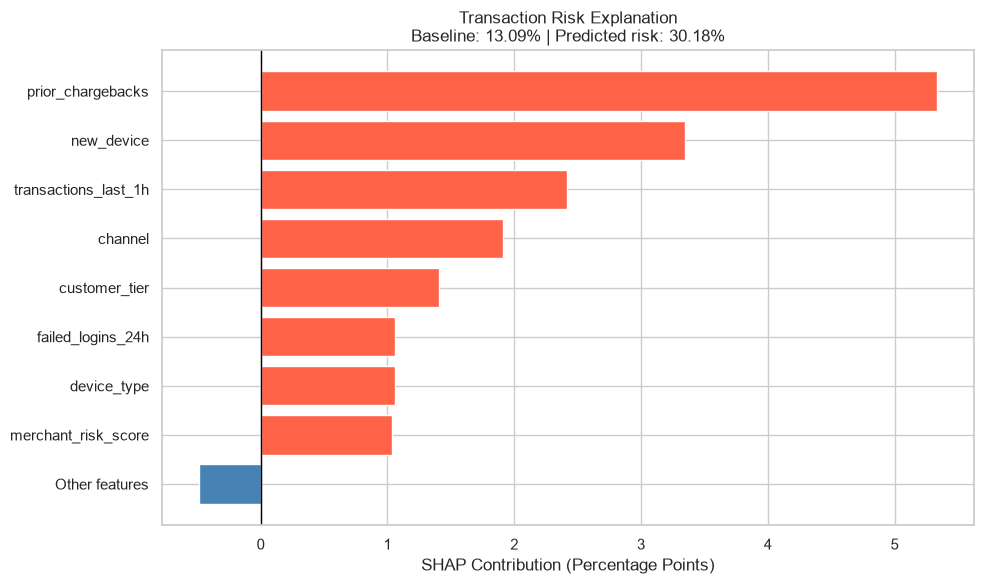


Transaction Example 3
Probability: 26.24%
Decision: Manual Review
Increasing factors: billing_address_mismatch=1: +3.46 pp; transactions_last_1h=4: +2.28 pp; ip_risk_score=0.538: +2.10 pp
Decreasing factors: device_type=iOS: -1.06 pp; new_device=0: -0.92 pp; transaction_amount=26.7: -0.31 pp


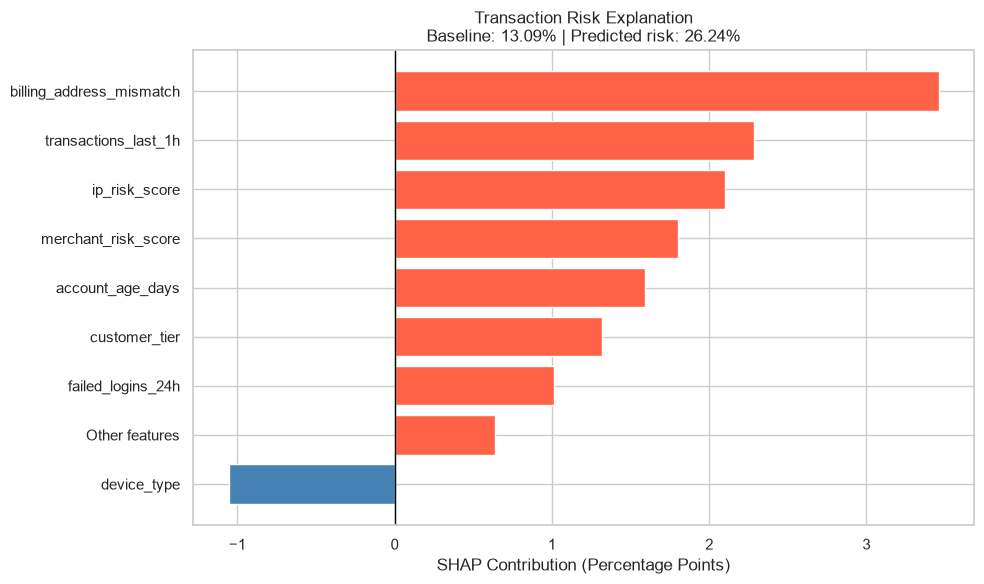


Transaction Example 4
Probability: 26.03%
Decision: Manual Review
Increasing factors: authentication_level=Missing: +5.65 pp; transactions_last_1h=5: +3.66 pp; merchant_category=Jewelry: +3.27 pp
Decreasing factors: account_age_days=1.32e+03: -2.51 pp; country=UK: -2.34 pp; day_of_week=6: -0.83 pp


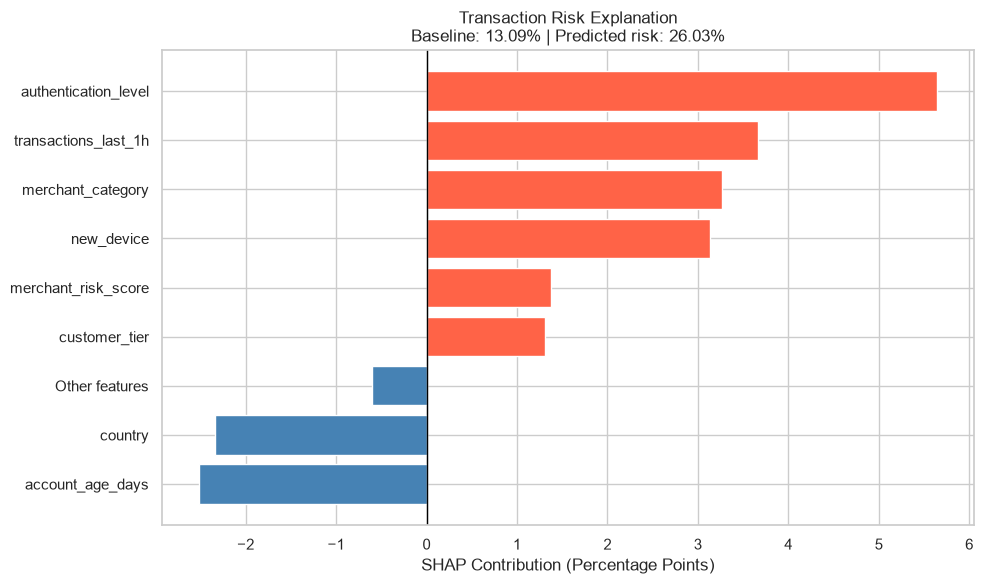


Transaction Example 5
Probability: 25.36%
Decision: Manual Review
Increasing factors: prior_chargebacks=1: +4.95 pp; transactions_last_1h=4: +2.22 pp; merchant_category=Healthcare: +2.08 pp
Decreasing factors: new_device=0: -0.90 pp; ip_risk_score=0.173: -0.54 pp; merchant_risk_score=0.285: -0.36 pp


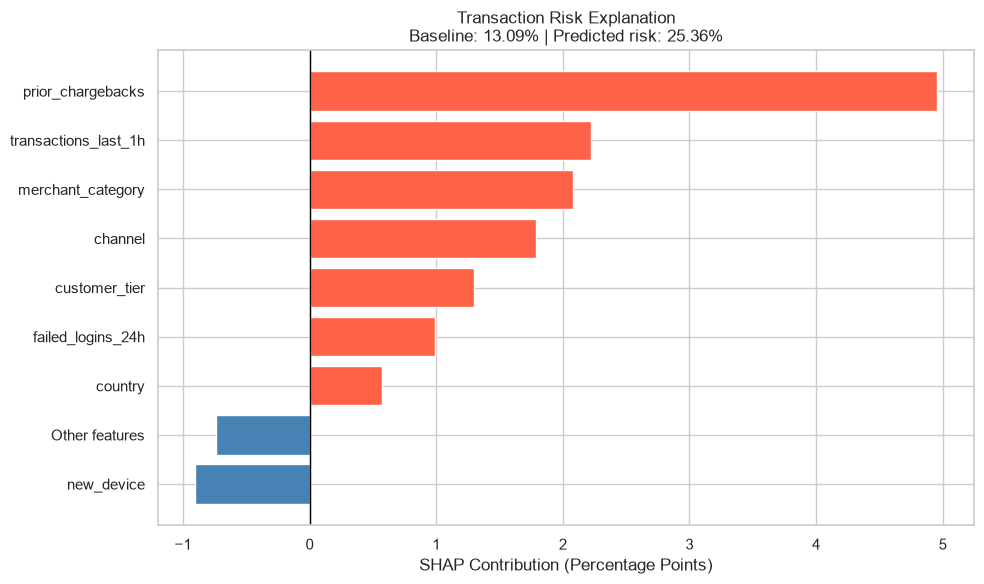

In [133]:
block_examples = high_risk_transactions.loc[
    high_risk_transactions["decision"] == "Block"
].nlargest(
    2, "fraud_probability"
)

review_examples = high_risk_transactions.loc[
    high_risk_transactions["decision"] == "Manual Review"
].nlargest(
    3, "fraud_probability"
)

selected_examples = pd.concat([
    block_examples,
    review_examples
])

# Fill remaining example slots if the policy differs
if len(selected_examples) < 5:

    additional = high_risk_transactions.loc[
        ~high_risk_transactions.index.isin(
            selected_examples.index
        )
    ].nlargest(
        5 - len(selected_examples),
        "fraud_probability"
    )

    selected_examples = pd.concat([
        selected_examples,
        additional
    ])

# If fewer than five transactions are flagged,
# explain additional approved transactions for comparison
if len(selected_examples) < 5:

    additional = explained_transactions.loc[
        ~explained_transactions.index.isin(
            selected_examples.index
        )
    ].nlargest(
        5 - len(selected_examples),
        "fraud_probability"
    )

    extra_values, extra_baseline = (
        fraud_explainer.explain(
            X_threshold.loc[additional.index]
        )
    )

    high_risk_shap = pd.concat([
        high_risk_shap, extra_values
    ])

    additional = additional.copy()

    additional["shap_baseline"] = extra_baseline

    for index in additional.index:

        factors = summarize_local_explanation(
            extra_values.loc[index],
            X_threshold.loc[index]
        )

        for key, value in factors.items():
            additional.loc[index, key] = value

    selected_examples = pd.concat([
        selected_examples, additional
    ])

assert len(selected_examples) == 5

for number, (index, row) in enumerate(
    selected_examples.iterrows(),
    start=1
):

    print(f"\nTransaction Example {number}")

    print(
        "Probability:",
        f"{row['fraud_probability']:.2%}"
    )

    print("Decision:", row["decision"])

    print(
        "Increasing factors:",
        row["risk_increasing_factors"]
    )

    print(
        "Decreasing factors:",
        row["risk_decreasing_factors"]
    )

    plot_local_explanation(
        high_risk_shap.loc[index],
        row["shap_baseline"],
        row["fraud_probability"],

        FIGURES_DIR / (
            f"shap_local_example_{number:02d}.png"
        )
    )

selected_examples.to_csv(
    METRICS_DIR / "shap_local_examples.csv",
    index=False
)

In [134]:
shap_export = high_risk_shap.copy()

shap_export.insert(
    0,
    ID_COLUMN,
    threshold_df.loc[
        shap_export.index,
        ID_COLUMN
    ]
)

shap_export.to_csv(
    METRICS_DIR / "transaction_shap_contributions.csv",
    index=False
)

joblib.dump(
    fraud_explainer.background,
    MODELS_DIR / "shap_reference_background.joblib"
)

print("Transaction SHAP contributions saved.")

print("SHAP reference background saved.")

Transaction SHAP contributions saved.
SHAP reference background saved.


## 11. Robustness, Stress Testing and Final Evaluation

Evaluate the robustness of the selected calibrated fraud
model under simulated distribution shifts, missing values,
unseen categories and extreme observations.

Compare performance against the original validation baseline
and quantify cross-validation variability.

Conduct final evaluation using the previously reserved
test dataset with the frozen model and operational thresholds.

No model selection, calibration fitting or threshold
optimization is performed using the final test dataset.

In [135]:
from src.robustness import (
    create_stress_scenarios,
    evaluate_frozen_policy,
    bootstrap_policy_intervals
)

from src.decision_engine import FraudDecisionEngine
from src.cost_analysis import create_cost_matrix

import hashlib
import joblib
import json

decision_engine = FraudDecisionEngine.load(
    MODELS_DIR
)

final_calibrated_model = decision_engine.model

final_pipeline = joblib.load(
    MODELS_DIR / "03_fraud_model_pipeline.joblib"
)

frozen_policy = decision_engine.policy

frozen_artifacts = [
    "03_fraud_model_pipeline.joblib",
    "04_calibrated_model.joblib",
    "decision_policy.json"
]

artifact_hashes = {
    name: hashlib.sha256(
        (MODELS_DIR / name).read_bytes()
    ).hexdigest()
    for name in frozen_artifacts
}

with open(
    MODELS_DIR / "frozen_artifact_hashes.json",
    "w",
    encoding="utf-8"
) as file:

    json.dump(
        artifact_hashes,
        file,
        indent=4
    )

print("Frozen model:", frozen_policy["model"])

print(
    "Review threshold:",
    frozen_policy["review_threshold"]
)

print(
    "Block threshold:",
    frozen_policy["block_threshold"]
)

print("Model artifacts recorded successfully.")

Frozen model: Logistic Regression | Original
Review threshold: 0.145
Block threshold: 0.265
Model artifacts recorded successfully.


In [136]:
stress_scenarios = create_stress_scenarios(
    X_threshold,
    y_threshold,
    random_state=RANDOM_STATE
)

stress_data_records = []

for name, (X_stress, y_stress) in (
    stress_scenarios.items()
):

    assert X_stress.index.equals(
        y_stress.index
    )

    assert list(X_stress.columns) == list(
        X_threshold.columns
    )

    assert (
        X_stress["transactions_last_1h"]
        <= X_stress["transactions_last_24h"]
    ).all()

    stress_data_records.append({

        "scenario": name,

        "transactions": len(X_stress),

        "fraud_count": int(y_stress.sum()),

        "fraud_prevalence": y_stress.mean(),

        "median_amount": (
            X_stress["transaction_amount"].median()
        ),

        "mean_velocity_1h": (
            X_stress["transactions_last_1h"].mean()
        ),

        "ecommerce_rate": (
            X_stress["channel"].eq("E-commerce").mean()
        ),

        "missing_cells": int(
            X_stress.isna().sum().sum()
        )
    })

stress_data_summary = pd.DataFrame(
    stress_data_records
)

display(stress_data_summary)

stress_data_summary.to_csv(
    METRICS_DIR / "stress_dataset_summary.csv",
    index=False
)

assert len(stress_scenarios) == 9

,scenario,transactions,fraud_count,fraud_prevalence,median_amount,mean_velocity_1h,ecommerce_rate,missing_cells
0,Clean,450,54,0.1200,83.1500,2.2422,0.4156,73
1,Amount x2,450,54,0.1200,166.3000,2.2422,0.4156,73
2,Velocity surge,450,54,0.1200,83.1500,4.2422,0.4156,73
3,Combined surge,450,54,0.1200,166.3000,4.2422,0.4156,73
4,30% missing injection,450,54,0.1200,82.3900,2.2422,0.4156,724
5,Authentication outage,450,54,0.1200,83.1500,2.2422,0.4156,490
6,Extreme 5%,450,54,0.1200,87.2100,2.2422,0.4156,73
7,Unseen device,450,54,0.1200,83.1500,2.2422,0.4156,73
8,70% ecommerce,250,34,0.1360,80.4800,2.3040,0.7000,38


In [137]:
stress_records = []

for name, (X_stress, y_stress) in (
    stress_scenarios.items()
):

    probabilities = (
        final_calibrated_model.predict_proba(
            X_stress
        )[:, 1]
    )

    assert len(probabilities) == len(X_stress)

    assert np.isfinite(probabilities).all()

    assert (
        (probabilities >= 0)
        & (probabilities <= 1)
    ).all()

    metrics = evaluate_frozen_policy(
        y_stress,
        probabilities,
        frozen_policy
    )

    stress_records.append({

        "scenario": name,

        **metrics
    })

    print(
        f"{name}: "
        f"AP={metrics['pr_auc']:.4f}, "
        f"Review={metrics['review_rate']:.2%}, "
        f"Cost/txn=${metrics['cost_per_transaction']:.2f}"
    )

stress_results = pd.DataFrame(
    stress_records
)

display(stress_results)

stress_results.to_csv(
    METRICS_DIR / "robustness_stress_results.csv",
    index=False
)

Clean: AP=0.2091, Review=24.44%, Cost/txn=$7.99
Amount x2: AP=0.2071, Review=27.78%, Cost/txn=$8.01
Velocity surge: AP=0.2091, Review=37.33%, Cost/txn=$7.54
Combined surge: AP=0.2071, Review=39.11%, Cost/txn=$7.52
30% missing injection: AP=0.2101, Review=20.22%, Cost/txn=$8.69
Authentication outage: AP=0.2134, Review=54.44%, Cost/txn=$7.40
Extreme 5%: AP=0.2016, Review=24.22%, Cost/txn=$8.04
Unseen device: AP=0.2108, Review=27.33%, Cost/txn=$7.54
70% ecommerce: AP=0.2582, Review=29.20%, Cost/txn=$7.70


,scenario,transactions,fraud_count,fraud_prevalence,pr_auc,roc_auc,brier,log_loss,flag_precision,flag_recall,flag_f1,mean_probability,review_threshold,block_threshold,approve_count,review_count,block_count,fraud_approved,fraud_reviewed,fraud_blocked,legitimate_approved,legitimate_reviewed,legitimate_blocked,review_rate,block_rate,fraud_flag_rate,expected_fraud_prevented,expected_fraud_capture,legitimate_flag_rate,total_cost,cost_per_transaction,probability_expected_cost,approve_all_cost,cost_saving,saving_pct,capacity_feasible
0,Clean,450,54,0.1200,0.2091,0.6781,0.1024,0.3508,0.2308,0.5000,0.3158,0.1212,0.1450,0.2650,333,110,7,27,24,3,306,86,4,0.2444,0.0156,0.5000,24.6000,0.4556,0.2273,3596.0000,7.9911,4158.1881,5400.0000,1804.0000,33.4074,True
1,Amount x2,450,54,0.1200,0.2071,0.6731,0.1026,0.3515,0.2105,0.5185,0.2995,0.1245,0.1450,0.2650,317,125,8,26,25,3,291,100,5,0.2778,0.0178,0.5185,25.5000,0.4722,0.2652,3606.0000,8.0133,4128.0132,5400.0000,1794.0000,33.2222,False
2,Velocity surge,450,54,0.1200,0.2091,0.6781,0.1027,0.3528,0.1902,0.6481,0.2941,0.1411,0.1450,0.2650,266,168,16,19,32,3,247,136,13,0.3733,0.0356,0.6481,31.8000,0.5889,0.3763,3391.0000,7.5356,4227.8509,5400.0000,2009.0000,37.2037,False
3,Combined surge,450,54,0.1200,0.2071,0.6731,0.1031,0.3541,0.1846,0.6667,0.2892,0.1448,0.1450,0.2650,255,176,19,18,32,4,237,144,15,0.3911,0.0422,0.6667,32.8000,0.6074,0.4015,3383.0000,7.5178,4244.3570,5400.0000,2017.0000,37.3519,False
4,30% missing injection,450,54,0.1200,0.2101,0.6513,0.1024,0.3554,0.2376,0.4444,0.3097,0.1057,0.1450,0.2650,349,91,10,30,23,1,319,68,9,0.2022,0.0222,0.4444,21.7000,0.4019,0.1944,3912.0000,8.6933,3539.8129,5400.0000,1488.0000,27.5556,True
5,Authentication outage,450,54,0.1200,0.2134,0.6657,0.1046,0.3609,0.1550,0.7778,0.2585,0.1683,0.1450,0.2650,179,245,26,12,37,5,167,208,21,0.5444,0.0578,0.7778,38.3000,0.7093,0.5783,3330.0000,7.4000,4190.8006,5400.0000,2070.0000,38.3333,False
6,Extreme 5%,450,54,0.1200,0.2016,0.6759,0.1029,0.3520,0.2308,0.5000,0.3158,0.1220,0.1450,0.2650,333,109,8,27,24,3,306,85,5,0.2422,0.0178,0.5000,24.6000,0.4556,0.2273,3616.0000,8.0356,4171.2195,5400.0000,1784.0000,33.0370,True
7,Unseen device,450,54,0.1200,0.2108,0.6923,0.1019,0.3485,0.2366,0.5741,0.3351,0.1241,0.1450,0.2650,319,123,8,23,30,1,296,93,7,0.2733,0.0178,0.5741,28.0000,0.5185,0.2525,3392.0000,7.5378,4140.0627,5400.0000,2008.0000,37.1852,False
8,70% ecommerce,250,34,0.1360,0.2582,0.7172,0.1123,0.3733,0.2658,0.6176,0.3717,0.1289,0.1450,0.2650,171,73,6,13,18,3,158,55,3,0.2920,0.0240,0.6176,19.2000,0.5647,0.2685,1926.0000,7.7040,2331.8185,3400.0000,1474.0000,43.3529,False


In [138]:
operational_stress_columns = [
    "scenario",
    "transactions",
    "review_count",
    "block_count",
    "review_rate",
    "block_rate",
    "expected_fraud_capture",
    "legitimate_flag_rate",
    "cost_per_transaction",
    "capacity_feasible"
]

display(
    stress_results[operational_stress_columns]
)

stress_results[
    operational_stress_columns
].to_csv(
    METRICS_DIR / "operational_stress_results.csv",
    index=False
)

,scenario,transactions,review_count,block_count,review_rate,block_rate,expected_fraud_capture,legitimate_flag_rate,cost_per_transaction,capacity_feasible
0,Clean,450,110,7,0.2444,0.0156,0.4556,0.2273,7.9911,True
1,Amount x2,450,125,8,0.2778,0.0178,0.4722,0.2652,8.0133,False
2,Velocity surge,450,168,16,0.3733,0.0356,0.5889,0.3763,7.5356,False
3,Combined surge,450,176,19,0.3911,0.0422,0.6074,0.4015,7.5178,False
4,30% missing injection,450,91,10,0.2022,0.0222,0.4019,0.1944,8.6933,True
5,Authentication outage,450,245,26,0.5444,0.0578,0.7093,0.5783,7.4000,False
6,Extreme 5%,450,109,8,0.2422,0.0178,0.4556,0.2273,8.0356,True
7,Unseen device,450,123,8,0.2733,0.0178,0.5185,0.2525,7.5378,False
8,70% ecommerce,250,73,6,0.2920,0.0240,0.5647,0.2685,7.7040,False


In [139]:
clean_baseline = stress_results.loc[
    stress_results["scenario"] == "Clean"
].iloc[0]

degradation_report = stress_results[
    [
        "scenario",
        "pr_auc",
        "roc_auc",
        "brier",
        "cost_per_transaction",
        "review_rate",
        "capacity_feasible"
    ]
].copy()

degradation_report["pr_auc_change_pct"] = (
    (
        degradation_report["pr_auc"]
        - clean_baseline["pr_auc"]
    )
    / clean_baseline["pr_auc"] * 100
)

degradation_report["roc_auc_change"] = (
    degradation_report["roc_auc"]
    - clean_baseline["roc_auc"]
)

degradation_report["brier_change"] = (
    degradation_report["brier"]
    - clean_baseline["brier"]
)

degradation_report["cost_change_pct"] = (
    (
        degradation_report["cost_per_transaction"]
        - clean_baseline["cost_per_transaction"]
    )
    / clean_baseline["cost_per_transaction"] * 100
)

degradation_report["review_rate_change_pp"] = (
    (
        degradation_report["review_rate"]
        - clean_baseline["review_rate"]
    ) * 100
)

display(degradation_report)

degradation_report.to_csv(
    METRICS_DIR / "model_degradation_report.csv",
    index=False
)

,scenario,pr_auc,roc_auc,brier,cost_per_transaction,review_rate,capacity_feasible,pr_auc_change_pct,roc_auc_change,brier_change,cost_change_pct,review_rate_change_pp
0,Clean,0.2091,0.6781,0.1024,7.9911,0.2444,True,0.0000,0.0000,0.0000,0.0000,0.0000
1,Amount x2,0.2071,0.6731,0.1026,8.0133,0.2778,False,-0.9549,-0.0050,0.0002,0.2781,3.3333
2,Velocity surge,0.2091,0.6781,0.1027,7.5356,0.3733,False,0.0000,0.0000,0.0003,-5.7008,12.8889
3,Combined surge,0.2071,0.6731,0.1031,7.5178,0.3911,False,-0.9549,-0.0050,0.0007,-5.9232,14.6667
4,30% missing injection,0.2101,0.6513,0.1024,8.6933,0.2022,True,0.4850,-0.0268,0.0000,8.7875,-4.2222
5,Authentication outage,0.2134,0.6657,0.1046,7.4000,0.5444,False,2.0339,-0.0124,0.0022,-7.3971,30.0000
6,Extreme 5%,0.2016,0.6759,0.1029,8.0356,0.2422,True,-3.5873,-0.0022,0.0005,0.5562,-0.2222
7,Unseen device,0.2108,0.6923,0.1019,7.5378,0.2733,False,0.8316,0.0142,-0.0006,-5.6730,2.8889
8,70% ecommerce,0.2582,0.7172,0.1123,7.7040,0.2920,False,23.4734,0.0391,0.0099,-3.5929,4.7556


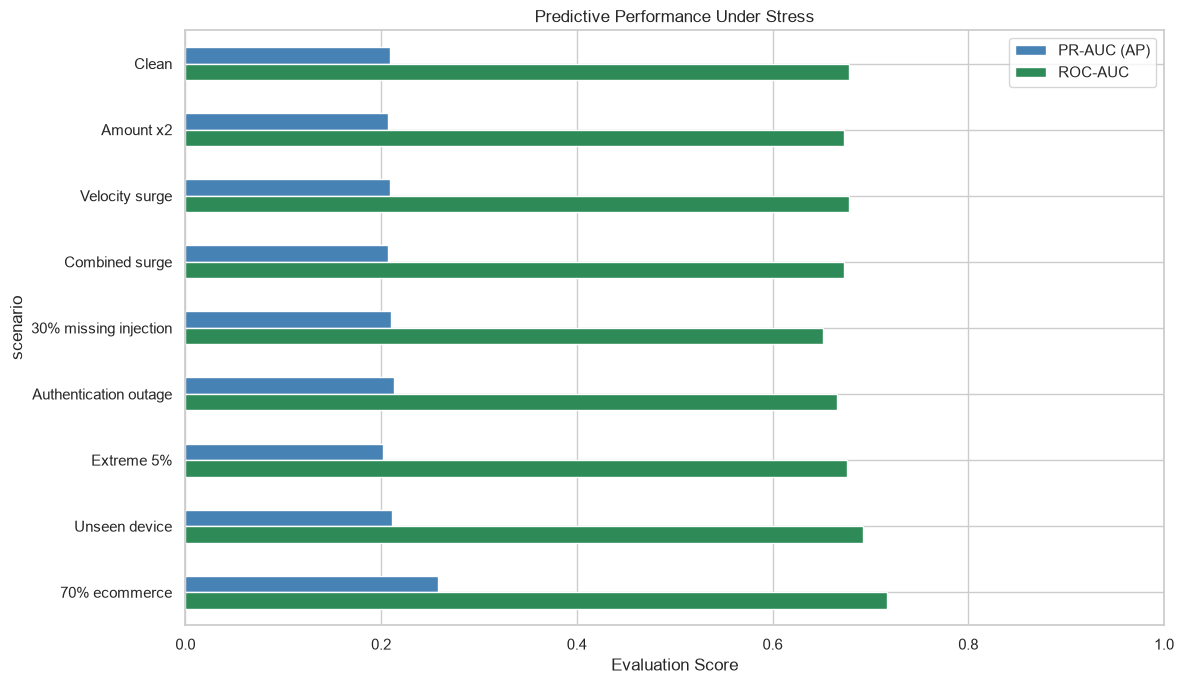

In [140]:
ax = stress_results.set_index(
    "scenario"
)[
    ["pr_auc", "roc_auc"]
].plot(
    kind="barh",
    figsize=(12, 7),
    color=["steelblue", "seagreen"]
)

ax.set_title("Predictive Performance Under Stress")

ax.set_xlabel("Evaluation Score")

ax.set_xlim(0, 1)

ax.invert_yaxis()

ax.legend(["PR-AUC (AP)", "ROC-AUC"])

plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "robustness_predictive_performance.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

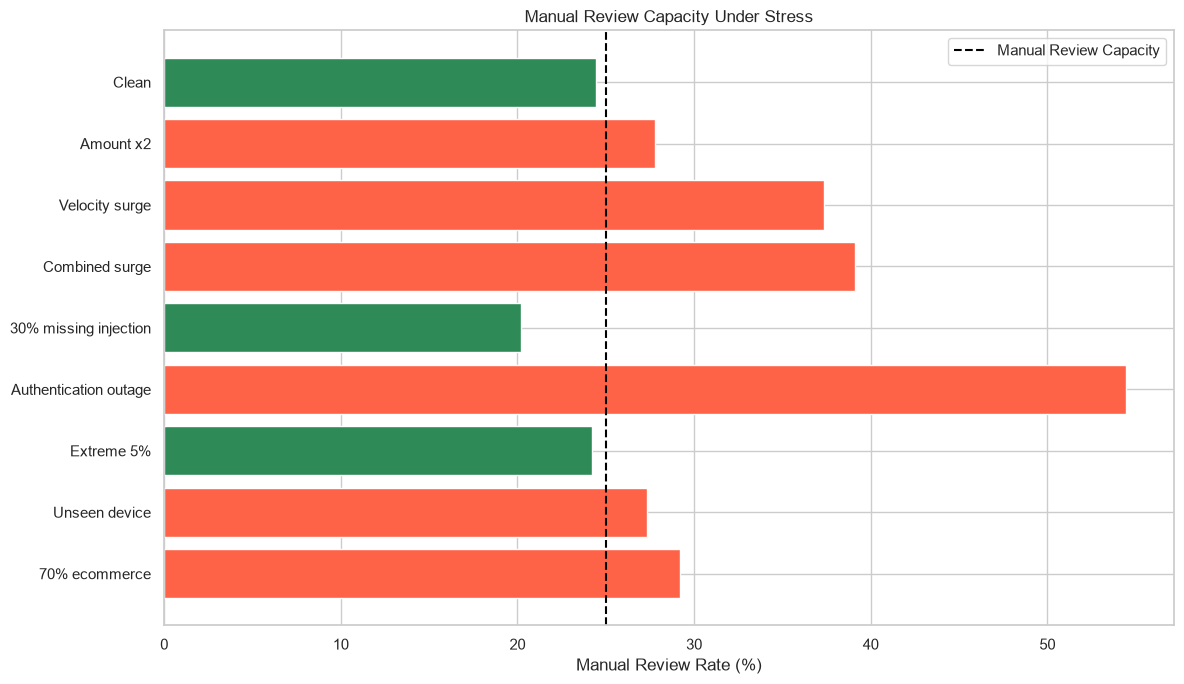

In [141]:
fig, ax = plt.subplots(figsize=(12, 7))

review_rates = (
    stress_results["review_rate"] * 100
)

colors = [
    "tomato" if rate > 25 else "seagreen"
    for rate in review_rates
]

ax.barh(
    stress_results["scenario"],
    review_rates,
    color=colors
)

ax.axvline(
    frozen_policy["max_review_rate"] * 100,
    color="black",
    linestyle="--",
    label="Manual Review Capacity"
)

ax.set_title("Manual Review Capacity Under Stress")

ax.set_xlabel("Manual Review Rate (%)")

ax.invert_yaxis()

ax.legend()

plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "robustness_review_capacity.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

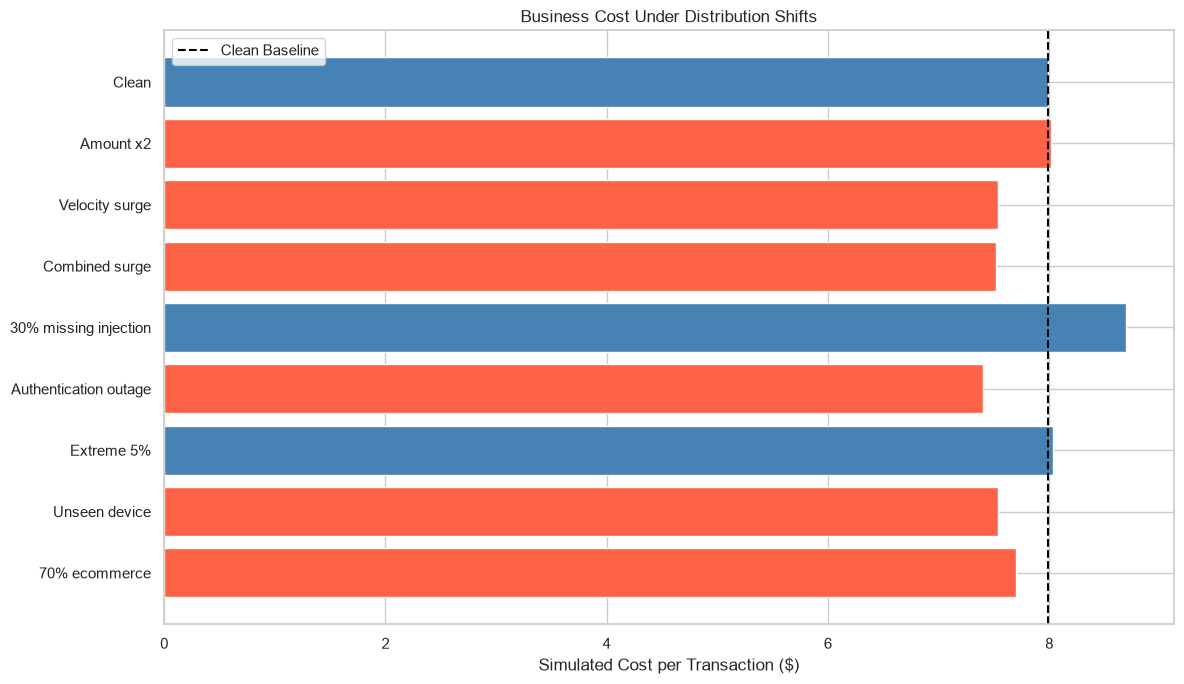

In [142]:
fig, ax = plt.subplots(figsize=(12, 7))

colors = [
    "steelblue" if feasible else "tomato"
    for feasible in stress_results["capacity_feasible"]
]

ax.barh(
    stress_results["scenario"],
    stress_results["cost_per_transaction"],
    color=colors
)

ax.axvline(
    clean_baseline["cost_per_transaction"],
    color="black",
    linestyle="--",
    label="Clean Baseline"
)

ax.set_title("Business Cost Under Distribution Shifts")

ax.set_xlabel("Simulated Cost per Transaction ($)")

ax.invert_yaxis()

ax.legend()

plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "robustness_business_cost.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [143]:
cv_performance = pd.read_csv(
    METRICS_DIR / "tuned_model_fold_results.csv"
)

cv_variability = (
    cv_performance
    .groupby("candidate")[
        ["pr_auc", "roc_auc"]
    ]
    .agg(
        ["mean", "std", "min", "max"]
    )
)

cv_variability.columns = [
    f"{metric}_{stat}"
    for metric, stat in cv_variability.columns
]

cv_variability["pr_auc_range"] = (
    cv_variability["pr_auc_max"]
    - cv_variability["pr_auc_min"]
)

cv_variability["roc_auc_range"] = (
    cv_variability["roc_auc_max"]
    - cv_variability["roc_auc_min"]
)

display(cv_variability)

cv_variability.to_csv(
    METRICS_DIR / "cv_robustness_variability.csv"
)

selected_cv = cv_performance.loc[
    cv_performance["candidate"]
    == frozen_policy["model"]
].sort_values("fold")

display(
    selected_cv[
        ["fold", "pr_auc", "roc_auc"]
    ]
)

,pr_auc_mean,pr_auc_std,pr_auc_min,pr_auc_max,roc_auc_mean,roc_auc_std,roc_auc_min,roc_auc_max,pr_auc_range,roc_auc_range
candidate,,,,,,,,,,
Logistic Regression | Engineered,0.2520,0.0303,0.2096,0.2919,0.6509,0.0423,0.6003,0.7069,0.0823,0.1066
Logistic Regression | Original,0.2473,0.0418,0.2031,0.2935,0.6394,0.0371,0.6126,0.7028,0.0903,0.0902
Random Forest | Engineered,0.2651,0.0431,0.2200,0.3321,0.6649,0.0431,0.6077,0.7150,0.1121,0.1073
Random Forest | Original,0.2414,0.0365,0.2008,0.2858,0.6693,0.0327,0.6339,0.7197,0.0850,0.0858
XGBoost | Engineered,0.2647,0.0518,0.2055,0.3395,0.6462,0.0625,0.5779,0.7180,0.1340,0.1401
XGBoost | Original,0.2519,0.0557,0.2087,0.3463,0.6376,0.0445,0.5863,0.6768,0.1376,0.0905


,fold,pr_auc,roc_auc
0,1,0.2031,0.6126
1,2,0.2348,0.6132
2,3,0.2160,0.6366
3,4,0.2935,0.6316
4,5,0.2893,0.7028


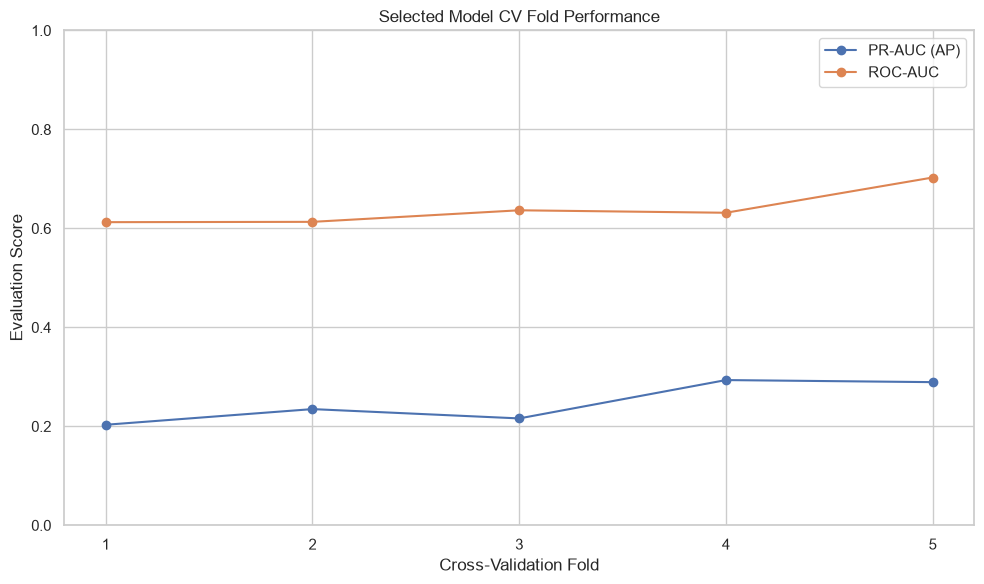

In [144]:
ax = selected_cv.set_index(
    "fold"
)[
    ["pr_auc", "roc_auc"]
].plot(
    kind="line",
    marker="o",
    figsize=(10, 6)
)

ax.set_title("Selected Model CV Fold Performance")

ax.set_xlabel("Cross-Validation Fold")

ax.set_ylabel("Evaluation Score")

ax.set_xticks([1, 2, 3, 4, 5])

ax.set_ylim(0, 1)

ax.legend(["PR-AUC (AP)", "ROC-AUC"])

plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "selected_model_fold_variability.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### 11.1 Final Independent Model Evaluation

Evaluate the frozen production candidate using the reserved
600-transaction final test partition.

The model parameters, preprocessing transformations,
probability calibration and operational thresholds remain
unchanged.

Final test results are reported without subsequent model
selection or threshold adjustment.

In [145]:
assert len(X_test) == 600

assert X_test.index.equals(y_test.index)

assert set(test_df[ID_COLUMN]).isdisjoint(
    train_df[ID_COLUMN]
)

assert set(test_df[ID_COLUMN]).isdisjoint(
    calibration_df[ID_COLUMN]
)

assert set(test_df[ID_COLUMN]).isdisjoint(
    threshold_df[ID_COLUMN]
)

# Verify saved model artifacts remain unchanged
for name, original_hash in artifact_hashes.items():

    current_hash = hashlib.sha256(
        (MODELS_DIR / name).read_bytes()
    ).hexdigest()

    assert current_hash == original_hash

print("Final evaluation integrity checks passed.")

print("Test transactions:", len(X_test))

print("Fraud transactions:", int(y_test.sum()))

print(
    "Legitimate transactions:",
    int((y_test == 0).sum())
)

Final evaluation integrity checks passed.
Test transactions: 600
Fraud transactions: 73
Legitimate transactions: 527


In [146]:
final_test_input = test_df[
    [ID_COLUMN] + feature_columns
].copy()

final_test_decisions = (
    decision_engine.score_transactions(
        final_test_input
    )
)

final_test_probabilities = (
    final_test_decisions[
        "fraud_probability"
    ].to_numpy()
)

assert len(final_test_probabilities) == 600

assert np.isfinite(
    final_test_probabilities
).all()

assert final_test_decisions.index.equals(
    y_test.index
)

final_test_metrics = evaluate_frozen_policy(
    y_test,
    final_test_probabilities,
    frozen_policy
)

display(pd.Series(final_test_metrics))

pd.DataFrame(
    [final_test_metrics]
).to_csv(
    METRICS_DIR / "final_test_metrics.csv",
    index=False
)

transactions                      600
fraud_count                        73
fraud_prevalence               0.1217
pr_auc                         0.2195
roc_auc                        0.6895
brier                          0.1028
log_loss                       0.3518
flag_precision                 0.2168
flag_recall                    0.4247
flag_f1                        0.2870
mean_probability               0.1213
review_threshold               0.1450
block_threshold                0.2650
approve_count                     457
review_count                      138
block_count                         5
fraud_approved                     42
fraud_reviewed                     30
fraud_blocked                       1
legitimate_approved               415
legitimate_reviewed               108
legitimate_blocked                  4
review_rate                    0.2300
block_rate                     0.0083
fraud_flag_rate                0.4247
expected_fraud_prevented      28.0000
expected_fra

In [147]:
final_test_outcomes = final_test_decisions.copy()

final_test_outcomes[TARGET] = y_test

final_outcome_table = pd.crosstab(
    final_test_outcomes["decision"],
    final_test_outcomes[TARGET]
).reindex(
    index=[
        "Approve",
        "Manual Review",
        "Block"
    ],
    columns=[0, 1],
    fill_value=0
)

final_outcome_table.columns = [
    "Legitimate", "Fraud"
]

display(final_outcome_table)

final_outcome_table.to_csv(
    METRICS_DIR / "final_test_operational_outcomes.csv"
)

final_test_outcomes.to_csv(
    METRICS_DIR / "final_test_predictions.csv",
    index=False
)

,Legitimate,Fraud
decision,,
Approve,415,42
Manual Review,108,30
Block,4,1


In [148]:
final_cost_matrix = pd.DataFrame(
    create_cost_matrix(
        frozen_policy["cost_assumptions"]
    ),
    index=final_outcome_table.index,
    columns=final_outcome_table.columns
)

final_cost_breakdown = (
    final_outcome_table * final_cost_matrix
)

display(final_cost_breakdown)

assert np.isclose(
    final_cost_breakdown.values.sum(),
    final_test_metrics["total_cost"]
)

final_cost_breakdown.to_csv(
    METRICS_DIR / "final_test_cost_breakdown.csv"
)

,Legitimate,Fraud
decision,,
Approve,0.0000,4200.0000
Manual Review,540.0000,450.0000
Block,100.0000,2.0000


In [149]:
from src.cost_analysis import policy_metrics

locked_policies = pd.read_csv(
    METRICS_DIR / "selected_policy_comparison.csv"
)

final_policy_records = []

for _, row in locked_policies.iterrows():

    assert row["candidate"] == frozen_policy["model"]

    assert (
        row["method"]
        == frozen_policy["calibration_method"]
    )

    metrics = policy_metrics(
        y_test,
        final_test_probabilities,
        float(row["review_threshold"]),
        float(row["block_threshold"]),
        frozen_policy["cost_assumptions"],
        frozen_policy["max_review_rate"],
        frozen_policy["max_block_rate"]
    )

    final_policy_records.append({
        "policy": row["policy"],
        **metrics
    })

# Uncalibrated classifier at default threshold
raw_test_probabilities = (
    final_pipeline.predict_proba(X_test)[:, 1]
)

raw_metrics = policy_metrics(
    y_test,
    raw_test_probabilities,
    0.50,
    0.50,
    frozen_policy["cost_assumptions"],
    frozen_policy["max_review_rate"],
    frozen_policy["max_block_rate"]
)

final_policy_records.append({
    "policy": "Uncalibrated 0.50",
    **raw_metrics
})

final_policy_comparison = pd.DataFrame(
    final_policy_records
)

display(
    final_policy_comparison[
        [
            "policy",
            "review_count",
            "block_count",
            "total_cost",
            "saving_pct",
            "capacity_feasible"
        ]
    ]
)

final_policy_comparison.to_csv(
    METRICS_DIR / "final_test_policy_comparison.csv",
    index=False
)

,policy,review_count,block_count,total_cost,saving_pct,capacity_feasible
0,Default 0.50,0,0,7300.0000,0.0000,True
1,Optimized binary,0,5,7302.0000,-0.0274,True
2,Optimized three-way,138,5,5292.0000,27.5068,True
3,Approve all,0,0,7300.0000,0.0000,True
4,Uncalibrated 0.50,0,81,6742.0000,7.6438,False


In [150]:
from src.calibration import reliability_table

from sklearn.metrics import brier_score_loss

final_calibration_comparison = pd.DataFrame({

    "method": [
        "Constant prevalence baseline",
        "Uncalibrated",
        "Calibrated"
    ],

    "brier": [

        brier_score_loss(
            y_test,
            np.full(len(y_test), y_train.mean())
        ),

        brier_score_loss(
            y_test,
            raw_test_probabilities
        ),

        brier_score_loss(
            y_test,
            final_test_probabilities
        )
    ]
})

display(final_calibration_comparison)

final_calibration_comparison.to_csv(
    METRICS_DIR / "final_test_calibration.csv",
    index=False
)

final_reliability = reliability_table(
    y_test,
    final_test_probabilities,
    n_bins=5
)

display(final_reliability)

final_reliability.to_csv(
    METRICS_DIR / "final_test_reliability.csv",
    index=False
)

,method,brier
0,Constant prevalence baseline,0.1069
1,Uncalibrated,0.1439
2,Calibrated,0.1028


,bin,transactions,fraud_count,mean_probability,observed_fraud_rate,calibration_gap,weight
0,"(0.0234, 0.0839]",120,4,0.0670,0.0333,0.0336,0.2000
1,"(0.0839, 0.103]",120,9,0.0936,0.0750,0.0186,0.2000
2,"(0.103, 0.124]",120,10,0.1138,0.0833,0.0305,0.2000
3,"(0.124, 0.152]",120,22,0.1375,0.1833,0.0458,0.2000
4,"(0.152, 0.433]",120,28,0.1945,0.2333,0.0388,0.2000


In [151]:
validation_metrics = evaluate_frozen_policy(
    y_threshold,
    final_calibrated_model.predict_proba(
        X_threshold
    )[:, 1],
    frozen_policy
)

comparison_keys = [
    "pr_auc",
    "roc_auc",
    "brier",
    "flag_precision",
    "flag_recall",
    "flag_f1",
    "review_rate",
    "block_rate",
    "expected_fraud_capture",
    "cost_per_transaction",
    "saving_pct"
]

generalization_report = pd.DataFrame({

    "metric": comparison_keys,

    "validation": [
        validation_metrics[key]
        for key in comparison_keys
    ],

    "final_test": [
        final_test_metrics[key]
        for key in comparison_keys
    ]
})

generalization_report["change"] = (
    generalization_report["final_test"]
    - generalization_report["validation"]
)

display(generalization_report)

generalization_report.to_csv(
    METRICS_DIR / "final_generalization_report.csv",
    index=False
)

,metric,validation,final_test,change
0,pr_auc,0.2091,0.2195,0.0104
1,roc_auc,0.6781,0.6895,0.0114
2,brier,0.1024,0.1028,0.0004
3,flag_precision,0.2308,0.2168,-0.0140
4,flag_recall,0.5000,0.4247,-0.0753
5,flag_f1,0.3158,0.2870,-0.0288
6,review_rate,0.2444,0.2300,-0.0144
7,block_rate,0.0156,0.0083,-0.0072
8,expected_fraud_capture,0.4556,0.3836,-0.0720
9,cost_per_transaction,7.9911,8.8200,0.8289


In [152]:
bootstrap_intervals, bootstrap_results = (
    bootstrap_policy_intervals(
        y_test,
        final_test_probabilities,
        frozen_policy,
        n_bootstrap=1000,
        random_state=RANDOM_STATE
    )
)

display(bootstrap_intervals)

bootstrap_intervals.to_csv(
    METRICS_DIR / "final_test_confidence_intervals.csv"
)

bootstrap_results.to_csv(
    METRICS_DIR / "final_test_bootstrap_results.csv",
    index=False
)

,lower_95,upper_95
pr_auc,0.1662,0.3140
roc_auc,0.6238,0.7518
brier,0.0846,0.1208
review_rate,0.1983,0.2650
expected_fraud_capture,0.2879,0.4788
cost_per_transaction,6.8522,10.8951
saving_pct,17.1351,37.1882


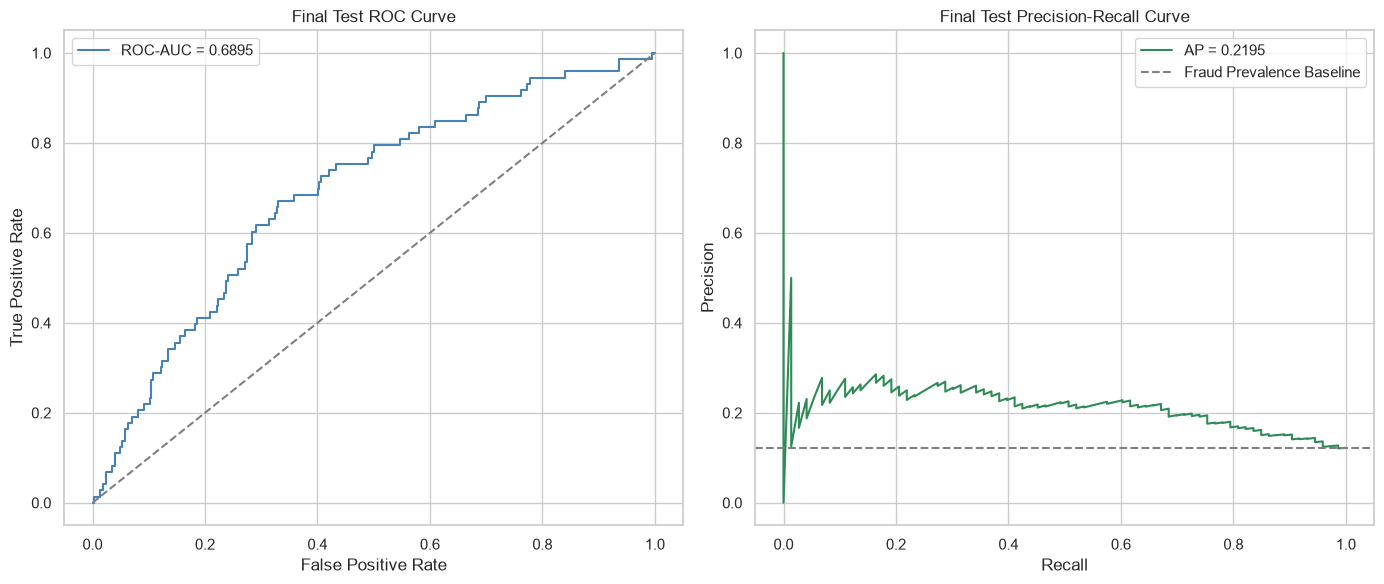

In [153]:
from sklearn.metrics import (
    roc_curve,
    precision_recall_curve
)

fpr, tpr, _ = roc_curve(
    y_test,
    final_test_probabilities
)

precision, recall, _ = precision_recall_curve(
    y_test,
    final_test_probabilities
)

fig, axes = plt.subplots(
    1, 2,
    figsize=(14, 6)
)

axes[0].plot(
    fpr,
    tpr,
    color="steelblue",
    label=(
        f"ROC-AUC = "
        f"{final_test_metrics['roc_auc']:.4f}"
    )
)

axes[0].plot(
    [0, 1], [0, 1],
    linestyle="--",
    color="gray"
)

axes[0].set_title("Final Test ROC Curve")
axes[0].set_xlabel("False Positive Rate")
axes[0].set_ylabel("True Positive Rate")
axes[0].legend()

axes[1].plot(
    recall,
    precision,
    color="seagreen",
    label=(
        f"AP = "
        f"{final_test_metrics['pr_auc']:.4f}"
    )
)

axes[1].axhline(
    y_test.mean(),
    color="gray",
    linestyle="--",
    label="Fraud Prevalence Baseline"
)

axes[1].set_title("Final Test Precision-Recall Curve")
axes[1].set_xlabel("Recall")
axes[1].set_ylabel("Precision")
axes[1].legend()

plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "final_test_roc_pr_curves.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

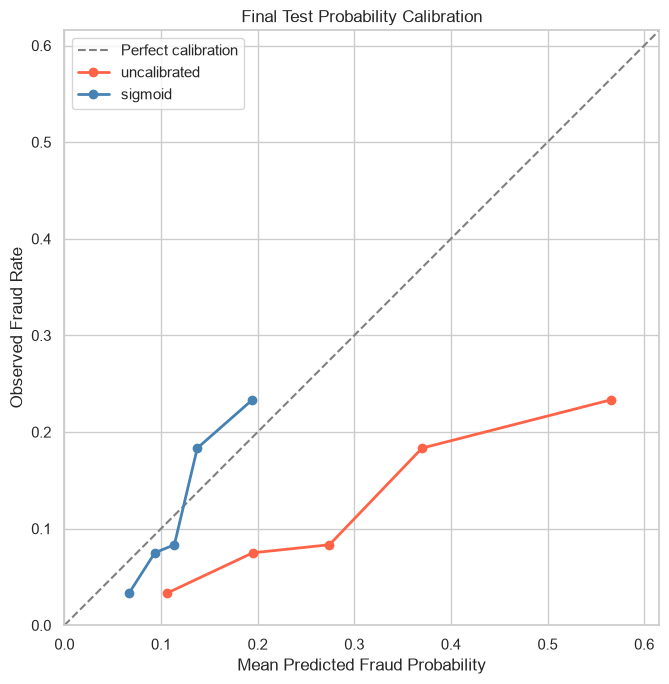

In [154]:
from src.calibration import plot_calibration_curves

plot_calibration_curves(
    y_true=y_test,

    probability_sets={
        "uncalibrated": raw_test_probabilities,

        frozen_policy["calibration_method"]:
            final_test_probabilities
    },

    title="Final Test Probability Calibration",

    save_path=(
        FIGURES_DIR / "final_test_calibration_curve.png"
    ),

    n_bins=5
)

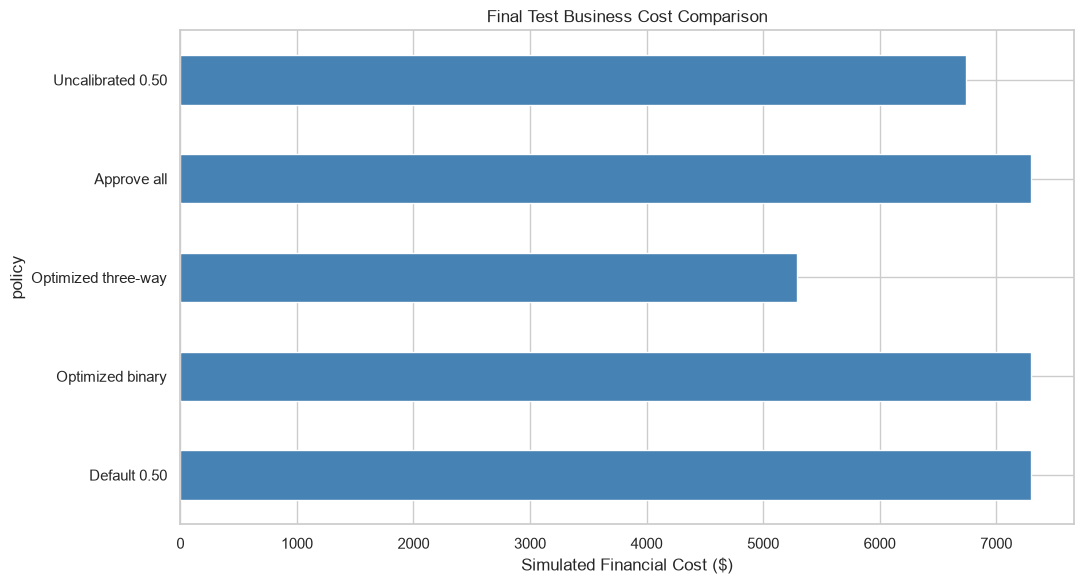

In [155]:
ax = final_policy_comparison.set_index(
    "policy"
)["total_cost"].plot(
    kind="barh",
    figsize=(11, 6),
    color="steelblue"
)

ax.set_title("Final Test Business Cost Comparison")

ax.set_xlabel("Simulated Financial Cost ($)")

plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "final_test_business_cost.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

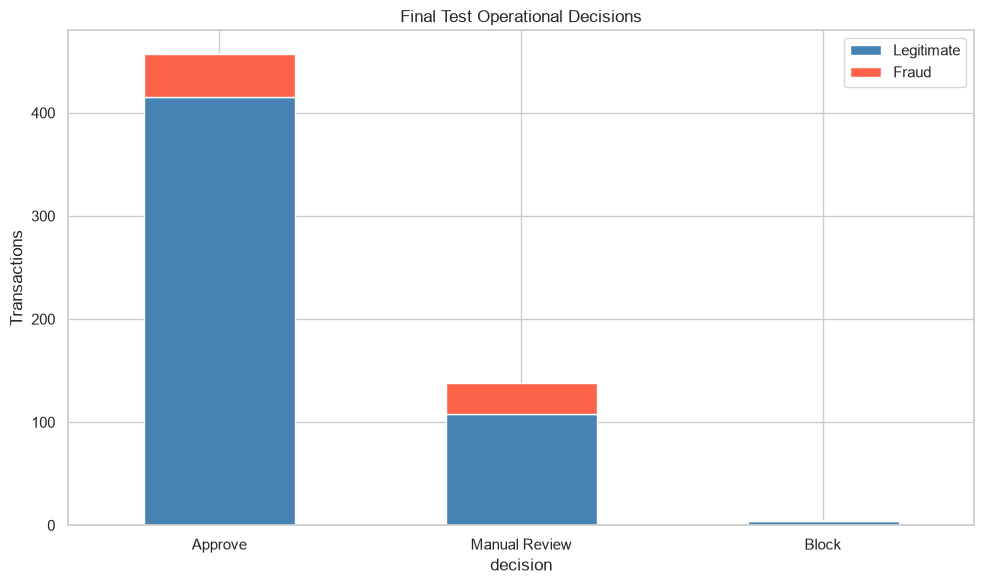

In [156]:
ax = final_outcome_table.plot(
    kind="bar",
    stacked=True,
    figsize=(10, 6),
    color=["steelblue", "tomato"]
)

ax.set_title("Final Test Operational Decisions")

ax.set_ylabel("Transactions")

plt.xticks(rotation=0)

plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "final_test_operational_outcomes.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [157]:
for name, original_hash in artifact_hashes.items():

    current_hash = hashlib.sha256(
        (MODELS_DIR / name).read_bytes()
    ).hexdigest()

    assert current_hash == original_hash

print("Model artifacts remain unchanged.")

print("No final test-based retraining performed.")

print("No final test-based threshold optimization performed.")

print("Final model evaluation completed.")

Model artifacts remain unchanged.
No final test-based retraining performed.
No final test-based threshold optimization performed.
Final model evaluation completed.


## 12. Model Governance and Production Monitoring

Implement feature drift detection, prediction drift monitoring,
data-quality checks, operational capacity monitoring and
labeled performance evaluation.

Define model review, retraining and temporary suspension rules.

Generate a model card documenting intended use, evaluation
methodology, assumptions, limitations and known risks.

The selected model and operational thresholds remain frozen.

In [158]:
from src.monitoring import (
    population_stability_index,
    build_monitoring_reference,
    monitor_batch,
    DEFAULT_CONFIG
)

from src.decision_engine import FraudDecisionEngine

from src.robustness import (
    create_stress_scenarios,
    evaluate_frozen_policy
)

import json
import hashlib

decision_engine = FraudDecisionEngine.load(
    MODELS_DIR
)

frozen_policy = decision_engine.policy

final_calibrated_model = decision_engine.model

print("Monitoring configuration initialized.")

display(pd.Series(DEFAULT_CONFIG))

Monitoring configuration initialized.


minimum_batch                     200.0000
minimum_fraud                      20.0000
minimum_legitimate                 20.0000
minimum_blocks_for_precision       20.0000
psi_warning                         0.1000
psi_major                           0.2500
missing_increase_warning            0.0500
missing_increase_critical           0.2000
authentication_missing_critical     0.3000
unknown_warning                     0.0500
unknown_critical                    0.2000
ap_relative_drop                    0.2000
brier_increase                      0.0200
capture_drop                        0.1000
legitimate_flag_increase            0.1000
block_precision_target              0.5000
tail_warning                        0.0300
dtype: float64

In [162]:
import importlib
import src.monitoring

importlib.reload(src.monitoring)

from src.monitoring import (
    population_stability_index,
    build_monitoring_reference,
    monitor_batch,
    DEFAULT_CONFIG
)

print("Updated monitoring module loaded successfully.")

Updated monitoring module loaded successfully.


In [163]:
reference_probabilities = (
    final_calibrated_model.predict_proba(
        X_threshold
    )[:, 1]
)

reference_metrics = evaluate_frozen_policy(
    y_threshold,
    reference_probabilities,
    frozen_policy
)

monitoring_reference = build_monitoring_reference(
    X_train=X_train,

    validation_probabilities=reference_probabilities,

    validation_metrics=reference_metrics,

    policy=frozen_policy,

    n_bins=10
)

reference_path = (
    MODELS_DIR / "monitoring_reference.json"
)

with open(
    reference_path,
    "w",
    encoding="utf-8"
) as file:

    json.dump(
        monitoring_reference,
        file,
        indent=4,
        allow_nan=False
    )

print(
    "Monitored input features:",
    len(monitoring_reference["features"])
)

print(
    "Input reference size:",
    monitoring_reference["reference_n"]
)

print(
    "Prediction reference size:",
    monitoring_reference["score_reference_n"]
)

print("Monitoring reference saved.")

Monitored input features: 23
Input reference size: 1500
Prediction reference size: 450
Monitoring reference saved.


In [164]:
reference_missingness = pd.DataFrame([

    {
        "feature": feature,

        "reference_missing_rate": (
            specification["missing_rate"]
        )
    }

    for feature, specification in
    monitoring_reference["features"].items()

]).sort_values(
    "reference_missing_rate",
    ascending=False
)

display(reference_missingness)

reference_missingness.to_csv(
    METRICS_DIR / "monitoring_reference_missingness.csv",
    index=False
)

,feature,reference_missing_rate
19,authentication_level,0.0973
3,distance_from_usual_location_km,0.0260
10,merchant_risk_score,0.0220
13,login_to_transaction_minutes,0.0200
2,transaction_amount,0.0180
11,ip_risk_score,0.0140
0,hour,0.0000
6,account_age_days,0.0000
5,transactions_last_24h,0.0000
4,transactions_last_1h,0.0000


In [165]:
clean_drift, clean_kpis, clean_alerts = (
    monitor_batch(

        X=X_threshold,

        probabilities=reference_probabilities,

        reference=monitoring_reference,

        y_true=y_threshold
    )
)

display(clean_drift)

display(pd.Series(clean_kpis))

display(clean_alerts)

print(
    "Monitoring status:",
    clean_kpis["status"]
)

,feature,psi,drift_level,reference_missing_rate,current_missing_rate,missing_increase,unknown_rate,upper_tail_cut,upper_tail_rate
0,ip_risk_score,0.0616,stable,0.0140,0.0111,-0.0029,0.0000,NaN,NaN
1,transaction_amount,0.0517,stable,0.0180,0.0133,-0.0047,0.0000,707.0956,0.0000
2,merchant_risk_score,0.0484,stable,0.0220,0.0222,0.0002,0.0000,NaN,NaN
3,email_age_days,0.0453,stable,0.0000,0.0000,0.0000,0.0000,NaN,NaN
4,account_age_days,0.0435,stable,0.0000,0.0000,0.0000,0.0000,NaN,NaN
5,country,0.0346,stable,0.0000,0.0000,0.0000,0.0000,NaN,NaN
6,merchant_category,0.0288,stable,0.0000,0.0000,0.0000,0.0000,NaN,NaN
7,transactions_last_1h,0.0266,stable,0.0000,0.0000,0.0000,0.0000,NaN,NaN
8,device_age_days,0.0258,stable,0.0000,0.0000,0.0000,0.0000,NaN,NaN
9,transactions_last_24h,0.0202,stable,0.0000,0.0000,0.0000,0.0000,NaN,NaN


transactions                    450
mean_probability             0.1212
score_psi                    0.0000
review_rate                  0.2444
block_rate                   0.0156
review_count                    110
block_count                       7
label_status              evaluated
pr_auc                       0.2091
roc_auc                      0.6781
brier                        0.1024
expected_fraud_capture       0.4556
legitimate_flag_rate         0.2273
block_precision              0.4286
cost_per_transaction         7.9911
saving_pct                  33.4074
fraud_count                      54
fraud_prevalence             0.1200
status                     NO_ALERT
dtype: object

,severity,metric,value,limit,recommended_action
0,info,block_count,7.0000,20.0000,Insufficient support for stable block precision.


Monitoring status: NO_ALERT


### 12.1 Monitoring under Simulated Distribution Shifts

Evaluate the monitoring system using the clean validation
batch and eight previously defined stress scenarios.

Investigate feature drift, prediction drift, missingness,
operational workload and performance degradation.

The original trained model and decision thresholds remain
unchanged throughout the monitoring experiments.

In [166]:
stress_scenarios = create_stress_scenarios(
    X_threshold,
    y_threshold,
    random_state=RANDOM_STATE
)

monitoring_records = []
drift_records = []
alert_records = []

for scenario, (X_batch, y_batch) in (
    stress_scenarios.items()
):

    probabilities = (
        final_calibrated_model.predict_proba(
            X_batch
        )[:, 1]
    )

    drift, kpis, alerts = monitor_batch(

        X=X_batch,

        probabilities=probabilities,

        reference=monitoring_reference,

        y_true=y_batch
    )

    monitoring_records.append({

        "scenario": scenario,

        **kpis
    })

    drift_records.append(
        drift.assign(scenario=scenario)
    )

    alert_records.append(
        alerts.assign(scenario=scenario)
    )

    print(
        f"{scenario}: {kpis['status']}"
    )

monitoring_summary = pd.DataFrame(
    monitoring_records
)

monitoring_drift_results = pd.concat(
    drift_records,
    ignore_index=True
)

monitoring_alerts = pd.concat(
    alert_records,
    ignore_index=True
)

display(monitoring_summary)

display(monitoring_alerts)

monitoring_summary.to_csv(
    METRICS_DIR / "monitoring_stress_summary.csv",
    index=False
)

monitoring_drift_results.to_csv(
    METRICS_DIR / "monitoring_feature_drift.csv",
    index=False
)

monitoring_alerts.to_csv(
    METRICS_DIR / "monitoring_alerts.csv",
    index=False
)

assert len(monitoring_summary) == 9

Clean: NO_ALERT
Amount x2: PAUSE_OR_ESCALATE
Velocity surge: PAUSE_OR_ESCALATE
Combined surge: PAUSE_OR_ESCALATE
30% missing injection: PAUSE_OR_ESCALATE
Authentication outage: PAUSE_OR_ESCALATE
Extreme 5%: REVIEW
Unseen device: PAUSE_OR_ESCALATE
70% ecommerce: PAUSE_OR_ESCALATE


,scenario,transactions,mean_probability,score_psi,review_rate,block_rate,review_count,block_count,label_status,pr_auc,roc_auc,brier,expected_fraud_capture,legitimate_flag_rate,block_precision,cost_per_transaction,saving_pct,fraud_count,fraud_prevalence,status
0,Clean,450,0.1212,0.0000,0.2444,0.0156,110,7,evaluated,0.2091,0.6781,0.1024,0.4556,0.2273,0.4286,7.9911,33.4074,54,0.1200,NO_ALERT
1,Amount x2,450,0.1245,0.0101,0.2778,0.0178,125,8,evaluated,0.2071,0.6731,0.1026,0.4722,0.2652,0.3750,8.0133,33.2222,54,0.1200,PAUSE_OR_ESCALATE
2,Velocity surge,450,0.1411,0.2055,0.3733,0.0356,168,16,evaluated,0.2091,0.6781,0.1027,0.5889,0.3763,0.1875,7.5356,37.2037,54,0.1200,PAUSE_OR_ESCALATE
3,Combined surge,450,0.1448,0.2568,0.3911,0.0422,176,19,evaluated,0.2071,0.6731,0.1031,0.6074,0.4015,0.2105,7.5178,37.3519,54,0.1200,PAUSE_OR_ESCALATE
4,30% missing injection,450,0.1057,0.4202,0.2022,0.0222,91,10,evaluated,0.2101,0.6513,0.1024,0.4019,0.1944,0.1000,8.6933,27.5556,54,0.1200,PAUSE_OR_ESCALATE
5,Authentication outage,450,0.1683,0.7898,0.5444,0.0578,245,26,evaluated,0.2134,0.6657,0.1046,0.7093,0.5783,0.1923,7.4000,38.3333,54,0.1200,PAUSE_OR_ESCALATE
6,Extreme 5%,450,0.1220,0.0010,0.2422,0.0178,109,8,evaluated,0.2016,0.6759,0.1029,0.4556,0.2273,0.3750,8.0356,33.0370,54,0.1200,REVIEW
7,Unseen device,450,0.1241,0.0146,0.2733,0.0178,123,8,evaluated,0.2108,0.6923,0.1019,0.5185,0.2525,0.1250,7.5378,37.1852,54,0.1200,PAUSE_OR_ESCALATE
8,70% ecommerce,250,0.1289,0.0341,0.2920,0.0240,73,6,evaluated,0.2582,0.7172,0.1123,0.5647,0.2685,0.5000,7.7040,43.3529,34,0.1360,PAUSE_OR_ESCALATE


,severity,metric,value,limit,recommended_action,scenario
0,info,block_count,7.0000,20.0000,Insufficient support for stable block precision.,Clean
1,major,transaction_amount:PSI,0.5213,0.2500,Investigate significant distribution drift.,Amount x2
2,warning,transaction_amount:upper_tail_rate,0.0422,0.0300,Investigate extreme observations.,Amount x2
3,critical,review_rate,0.2778,0.2500,Escalate queue overload; use approved overflow...,Amount x2
4,info,block_count,8.0000,20.0000,Insufficient support for stable block precision.,Amount x2
5,major,transactions_last_1h:PSI,2.7968,0.2500,Investigate significant distribution drift.,Velocity surge
6,major,transactions_last_24h:PSI,2.0286,0.2500,Investigate significant distribution drift.,Velocity surge
7,warning,fraud_probability:PSI,0.2055,0.1000,Review feature distribution.,Velocity surge
8,critical,review_rate,0.3733,0.2500,Escalate queue overload; use approved overflow...,Velocity surge
9,major,legitimate_flag_rate,0.3763,0.3273,Investigate performance degradation.,Velocity surge


In [167]:
significant_drift = (
    monitoring_drift_results.loc[
        monitoring_drift_results["psi"] >= 0.25
    ].sort_values(
        "psi",
        ascending=False
    )
)

display(
    significant_drift[
        [
            "scenario",
            "feature",
            "psi",
            "drift_level",
            "current_missing_rate",
            "unknown_rate"
        ]
    ]
)

significant_drift.to_csv(
    METRICS_DIR / "significant_feature_drift.csv",
    index=False
)

,scenario,feature,psi,drift_level,current_missing_rate,unknown_rate
168,Unseen device,device_type,13.2746,major,0.0000,1.0000
120,Authentication outage,authentication_level,7.4999,major,1.0000,0.0000
48,Velocity surge,transactions_last_1h,2.7968,major,0.0000,0.0000
72,Combined surge,transactions_last_1h,2.7968,major,0.0000,0.0000
49,Velocity surge,transactions_last_24h,2.0286,major,0.0000,0.0000
73,Combined surge,transactions_last_24h,2.0286,major,0.0000,0.0000
96,30% missing injection,ip_risk_score,1.0382,major,0.3067,0.0000
97,30% missing injection,transaction_amount,0.9623,major,0.3089,0.0000
98,30% missing injection,merchant_risk_score,0.9497,major,0.3178,0.0000
99,30% missing injection,distance_from_usual_location_km,0.8257,major,0.3133,0.0000


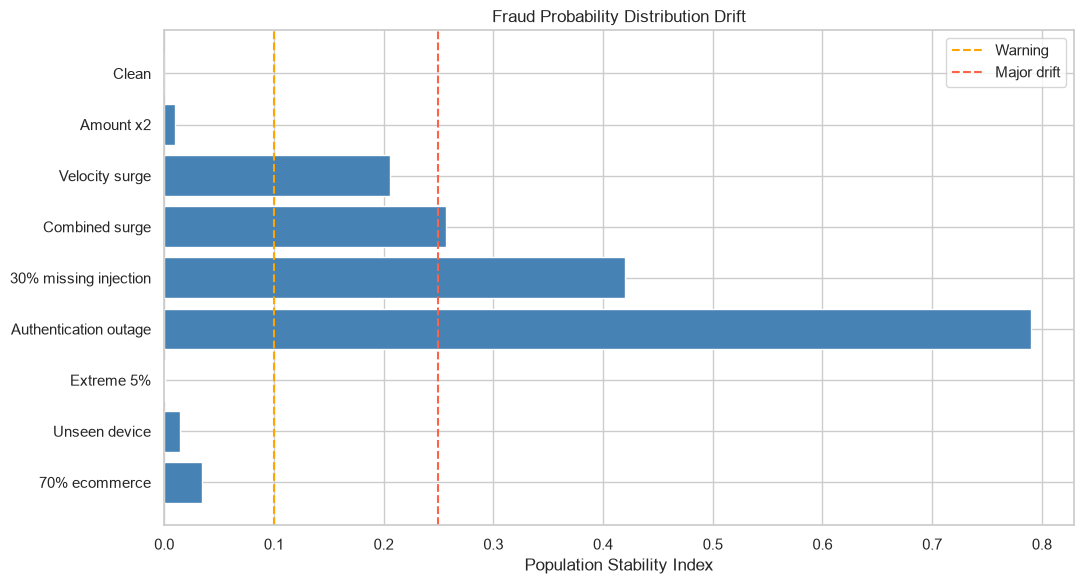

In [168]:
fig, ax = plt.subplots(
    figsize=(11, 6)
)

ax.barh(
    monitoring_summary["scenario"],
    monitoring_summary["score_psi"],
    color="steelblue"
)

ax.axvline(
    DEFAULT_CONFIG["psi_warning"],
    color="orange",
    linestyle="--",
    label="Warning"
)

ax.axvline(
    DEFAULT_CONFIG["psi_major"],
    color="tomato",
    linestyle="--",
    label="Major drift"
)

ax.set_title(
    "Fraud Probability Distribution Drift"
)

ax.set_xlabel(
    "Population Stability Index"
)

ax.invert_yaxis()

ax.legend()

plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "monitoring_prediction_drift.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

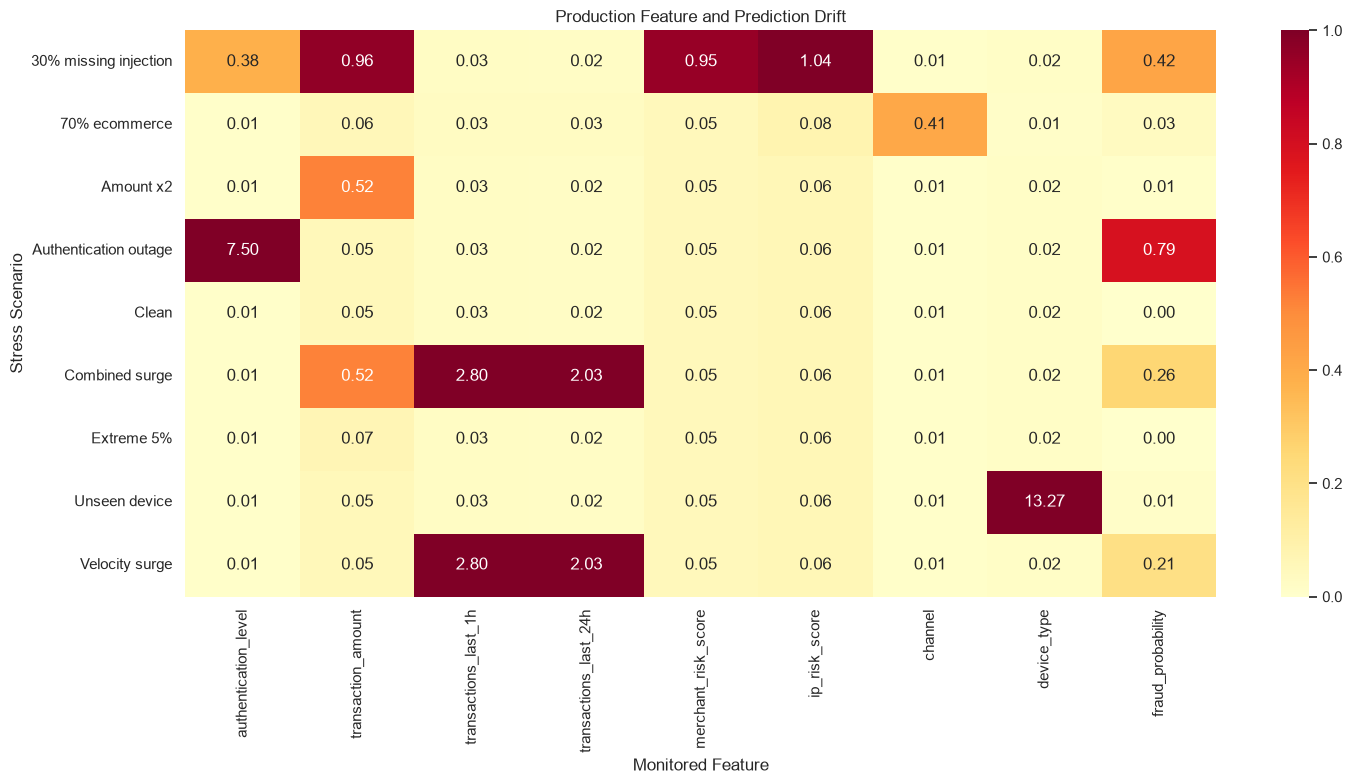

In [169]:
priority_monitoring_features = [
    "authentication_level",
    "transaction_amount",
    "transactions_last_1h",
    "transactions_last_24h",
    "merchant_risk_score",
    "ip_risk_score",
    "channel",
    "device_type",
    "fraud_probability"
]

drift_heatmap = (
    monitoring_drift_results.pivot(
        index="scenario",
        columns="feature",
        values="psi"
    ).reindex(
        columns=priority_monitoring_features
    )
)

plt.figure(figsize=(15, 8))

sns.heatmap(
    drift_heatmap,
    annot=True,
    fmt=".2f",
    cmap="YlOrRd",
    vmin=0,
    vmax=1
)

plt.title(
    "Production Feature and Prediction Drift"
)

plt.xlabel("Monitored Feature")
plt.ylabel("Stress Scenario")

plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "monitoring_feature_drift_heatmap.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

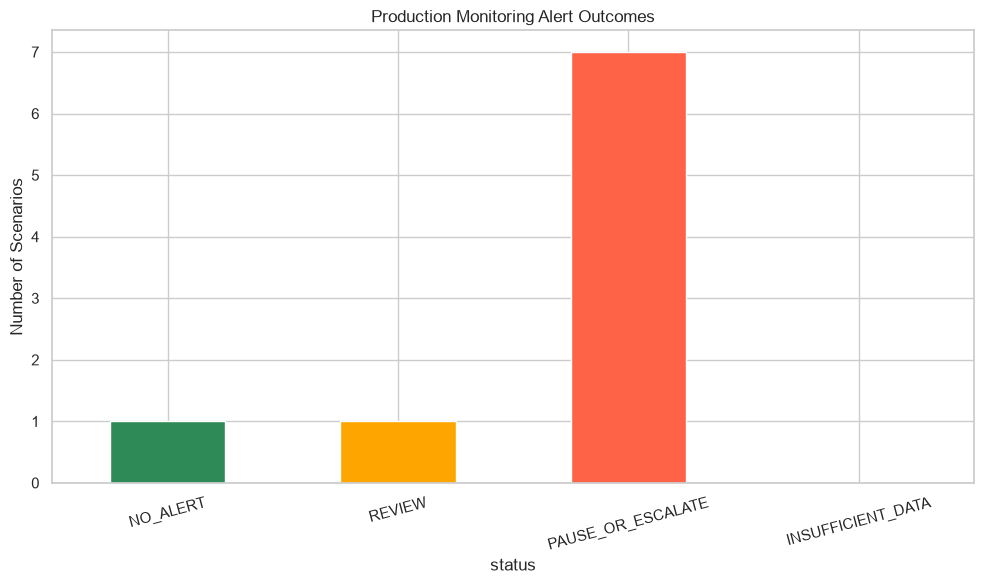

In [170]:
status_counts = (
    monitoring_summary["status"]
    .value_counts()
    .reindex(
        [
            "NO_ALERT",
            "REVIEW",
            "PAUSE_OR_ESCALATE",
            "INSUFFICIENT_DATA"
        ],
        fill_value=0
    )
)

ax = status_counts.plot(
    kind="bar",
    figsize=(10, 6),
    color=[
        "seagreen",
        "orange",
        "tomato",
        "gray"
    ]
)

ax.set_title(
    "Production Monitoring Alert Outcomes"
)

ax.set_ylabel("Number of Scenarios")

plt.xticks(rotation=15)

plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "monitoring_alert_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [171]:
unlabeled_drift, unlabeled_kpis, unlabeled_alerts = (
    monitor_batch(

        X=X_threshold,

        probabilities=reference_probabilities,

        reference=monitoring_reference,

        y_true=None
    )
)

display(pd.Series(unlabeled_kpis))

display(unlabeled_alerts)

assert (
    unlabeled_kpis["label_status"]
    == "not_supplied"
)

assert np.isnan(
    unlabeled_kpis["pr_auc"]
)

assert np.isnan(
    unlabeled_kpis["brier"]
)

print("Unlabeled production monitoring passed.")

transactions                       450
mean_probability                0.1212
score_psi                       0.0000
review_rate                     0.2444
block_rate                      0.0156
review_count                       110
block_count                          7
label_status              not_supplied
pr_auc                             NaN
roc_auc                            NaN
brier                              NaN
expected_fraud_capture             NaN
legitimate_flag_rate               NaN
block_precision                    NaN
cost_per_transaction               NaN
saving_pct                         NaN
status                        NO_ALERT
dtype: object

,severity,metric,value,limit,recommended_action


Unlabeled production monitoring passed.


### 12.2 Model Governance and Monitoring Rules

The fraud detection model should initially operate in shadow
mode or an analyst-assisted pilot.

Automatic transaction blocking is not recommended until
additional independent validation and operational approval
have been obtained.

Monitoring includes feature drift, probability drift,
data quality, predictive performance, customer impact
and operational financial performance.

In [172]:
model_card_path = (
    PROJECT_ROOT
    / "reports"
    / "06_model_card.pdf"
)

assert model_card_path.exists()

assert model_card_path.stat().st_size > 0

with open(
    model_card_path,
    "rb"
) as file:

    assert file.read(4) == b"%PDF"

print("Model card generated successfully.")

print(
    "Location:",
    model_card_path
)

print(
    "File size:",
    model_card_path.stat().st_size,
    "bytes"
)

Model card generated successfully.
Location: d:\Internship Tasks\Task - 2026.10.22\fraud-risk-intelligence-engine\reports\06_model_card.pdf
File size: 8693 bytes


In [173]:
with open(
    MODELS_DIR / "frozen_artifact_hashes.json",
    encoding="utf-8"
) as file:

    frozen_hashes = json.load(file)

for name, original_hash in frozen_hashes.items():

    current_hash = hashlib.sha256(
        (MODELS_DIR / name).read_bytes()
    ).hexdigest()

    assert current_hash == original_hash

print("Frozen model artifacts remain unchanged.")

print("No retraining performed.")

print("No threshold changes performed.")

print("Model governance implementation completed.")

Frozen model artifacts remain unchanged.
No retraining performed.
No threshold changes performed.
Model governance implementation completed.
